In [1]:
import pandas as pd
import json
import requests
import openpyxl

# API URL
api_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DA0321EN-SkillsNetwork/labs/module%201/Accessing%20Data%20Using%20APIs/jobs.json"

# Retrieve full dataset
response = requests.get(api_url)
data = response.json()


# Function to find number of jobs for a technology
def get_number_of_jobs_T(technology):
    number_of_jobs = 0

    for job in data:
        if technology.lower() in job["Key Skills"].lower():
            number_of_jobs += 1

    return technology, number_of_jobs


# Test Python
get_number_of_jobs_T("Python")


# Function to find number of jobs for a location
def get_number_of_jobs_L(location):
    number_of_jobs = 0

    for job in data:
        if location.lower() in job["Location"].lower():
            number_of_jobs += 1

    return location, number_of_jobs


# Test Los Angeles
get_number_of_jobs_L("Los Angeles")


# List of locations
locations = [
    "Los Angeles",
    "New York",
    "San Francisco",
    "Washington DC",
    "Seattle",
    "Austin",
    "Detroit"
]


# Create workbook
workbook = openpyxl.Workbook()
worksheet = workbook.active


# Add headers
worksheet["A1"] = "Location"
worksheet["B1"] = "Number of Jobs"


# Add results
row = 2

for location in locations:
    location, number_of_jobs = get_number_of_jobs_L(location)

    worksheet.cell(row=row, column=1, value=location)
    worksheet.cell(row=row, column=2, value=number_of_jobs)

    row += 1


# Save Excel file
workbook.save("job-postings.xlsx")

In [4]:

import requests
import openpyxl
from openpyxl.chart import BarChart, Reference

# Retrieve dataset
api_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DA0321EN-SkillsNetwork/labs/module%201/Accessing%20Data%20Using%20APIs/jobs.json"

response = requests.get(api_url)
response.raise_for_status()
data = response.json()

# Function to count jobs by location
def get_number_of_jobs_L(location):
    number_of_jobs = 0

    for job in data:
        if location.lower() in job["Location"].lower():
            number_of_jobs += 1

    return location, number_of_jobs

# Locations to analyze
locations = [
    "Los Angeles",
    "New York",
    "San Francisco",
    "Washington DC",
    "Seattle",
    "Austin",
    "Detroit"
]

# Count and sort jobs in descending order
results = [get_number_of_jobs_L(location) for location in locations]
results.sort(key=lambda x: x[1], reverse=True)

# Create workbook and worksheet
workbook = openpyxl.Workbook()
worksheet = workbook.active
worksheet.title = "Jobs by Location"

# Add headers
worksheet.append(["Location", "Number of Jobs"])

# Add sorted results
for location, number_of_jobs in results:
    worksheet.append([location, number_of_jobs])

# Create horizontal bar chart
chart = BarChart()
chart.type = "bar"
chart.style = 10
chart.title = "Number of Job Postings by Location"
chart.x_axis.title = "Number of Jobs"
chart.y_axis.title = "Location"
chart.height = 8
chart.width = 15
chart.legend = None

# Select chart data, including header
data_reference = Reference(
    worksheet,
    min_col=2,
    min_row=1,
    max_row=worksheet.max_row
)

# Select location labels
categories_reference = Reference(
    worksheet,
    min_col=1,
    min_row=2,
    max_row=worksheet.max_row
)

chart.add_data(data_reference, titles_from_data=True)
chart.set_categories(categories_reference)

# Put highest job count at the top
chart.y_axis.scaling.orientation = "maxMin"

# IMPORTANT: Attach chart to worksheet
worksheet.add_chart(chart, "D2")

# Save AFTER adding the chart
filename = "job-postings.xlsx"
workbook.save(filename)

print("Excel file saved successfully:", filename)
print("Number of charts created:", len(worksheet._charts))
print("Job counts in descending order:")
for location, count in results:
    print(location, count)


Excel file saved successfully: job-postings.xlsx
Number of charts created: 1
Job counts in descending order:
Washington DC 5316
Detroit 3945
Seattle 3375
New York 3226
Los Angeles 640
San Francisco 435
Austin 434


In [5]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# URL
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DA0321EN-SkillsNetwork/labs/datasets/Programming_Languages.html"

# Download webpage
data = requests.get(url).text

# Create soup object
soup = BeautifulSoup(data, "html.parser")

# Find table
table = soup.find("table")

# Extract rows
rows = table.find_all("tr")

languages = []
salaries = []

for row in rows[1:]:
    columns = row.find_all("td")

    languages.append(columns[1].text.strip())
    salaries.append(columns[3].text.strip())

# Create DataFrame
df = pd.DataFrame({
    "Language": languages,
    "Average Annual Salary": salaries
})

# Save CSV
df.to_csv("popular-languages.csv", index=False)

# Display data
df

,Language,Average Annual Salary
0,Python,"$114,383"
1,Java,"$101,013"
2,R,"$92,037"
3,Javascript,"$110,981"
4,Swift,"$130,801"
5,C++,"$113,865"
6,C#,"$88,726"
7,PHP,"$84,727"
8,SQL,"$84,793"
9,Go,"$94,082"


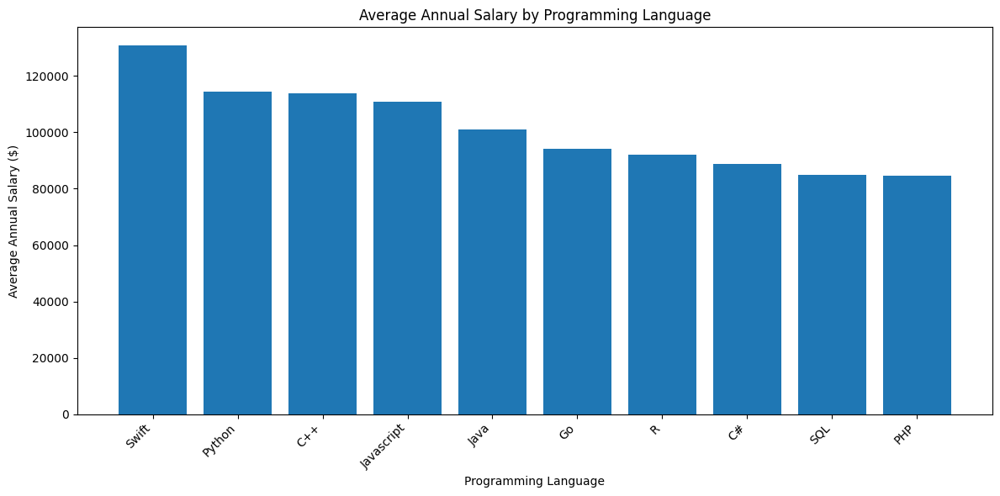

In [6]:

import matplotlib.pyplot as plt

# Convert salary column to numeric values
df["Average Annual Salary"] = (
    df["Average Annual Salary"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Sort salaries in descending order
df_sorted = df.sort_values(
    by="Average Annual Salary",
    ascending=False
)

# Create bar chart
plt.figure(figsize=(12, 6))
plt.bar(
    df_sorted["Language"],
    df_sorted["Average Annual Salary"]
)

# Add title and labels
plt.title("Average Annual Salary by Programming Language")
plt.xlabel("Programming Language")
plt.ylabel("Average Annual Salary ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Display chart
plt.show()


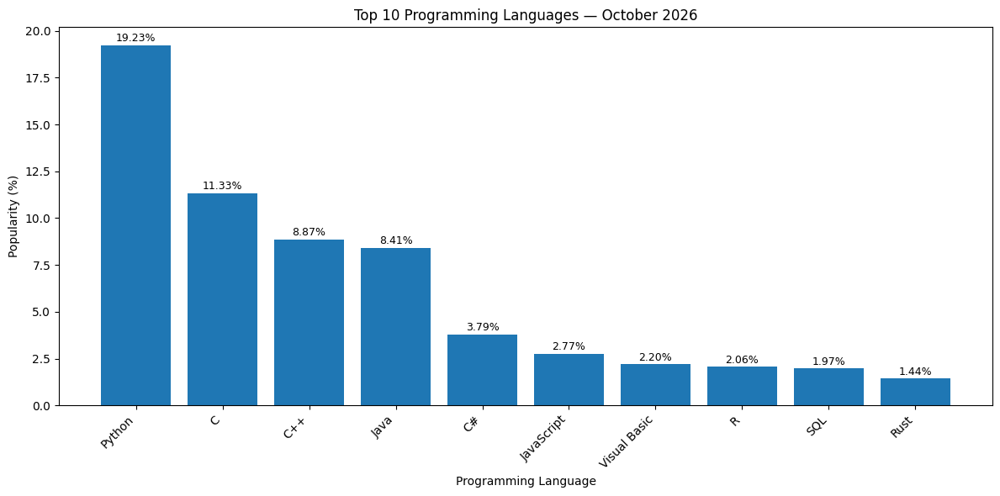

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

# Top 10 programming languages — October 2026
data = {
    "Language": [
        "Python", "C", "C++", "Java", "C#",
        "JavaScript", "Visual Basic", "R", "SQL", "Rust"
    ],
    "Popularity (%)": [
        19.23, 11.33, 8.87, 8.41, 3.79,
        2.77, 2.20, 2.06, 1.97, 1.44
    ]
}

df = pd.DataFrame(data)

# Create descending-order bar chart
df = df.sort_values("Popularity (%)", ascending=False)

plt.figure(figsize=(12, 6))
plt.bar(df["Language"], df["Popularity (%)"])

plt.title("Top 10 Programming Languages — October 2026")
plt.xlabel("Programming Language")
plt.ylabel("Popularity (%)")
plt.xticks(rotation=45, ha="right")

# Display values above bars
for i, value in enumerate(df["Popularity (%)"]):
    plt.text(i, value + 0.2, f"{value:.2f}%",
             ha="center", fontsize=9)

plt.tight_layout()
plt.show()


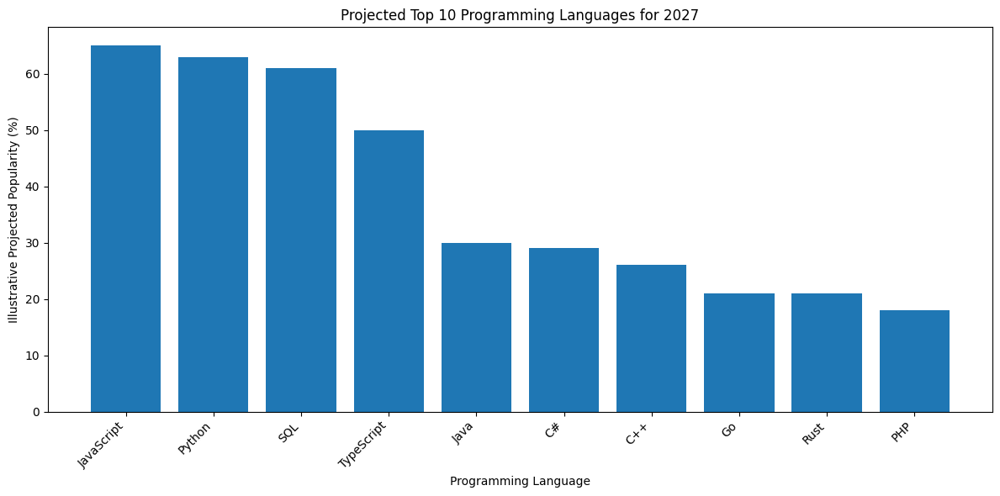

In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# Illustrative projection for 2027 — not official forecast data
data = {
    "Language": [
        "JavaScript", "Python", "SQL", "TypeScript",
        "Java", "C#", "C++", "Go", "Rust", "PHP"
    ],
    "Projected Popularity (%)": [
        65, 63, 61, 50, 30, 29, 26, 21, 21, 18
    ]
}

df_2027 = pd.DataFrame(data)

# Sort from highest to lowest
df_2027 = df_2027.sort_values(
    "Projected Popularity (%)",
    ascending=False
)

# Plot bar chart
plt.figure(figsize=(12, 6))
plt.bar(
    df_2027["Language"],
    df_2027["Projected Popularity (%)"]
)

plt.title("Projected Top 10 Programming Languages for 2027")
plt.xlabel("Programming Language")
plt.ylabel("Illustrative Projected Popularity (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# Load dataset
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"

df = pd.read_csv(file_path)

# Age mapping
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29,
    "35-44 years old": 39,
    "45-54 years old": 49,
    "55-64 years old": 59,
    "65 years or older": 70
}

# Create numeric Age column
df['Age_numeric'] = df['Age'].map(age_mapping)

# Calculate mean age
mean_age = df['Age_numeric'].mean()
print("Mean age:", mean_age)

# Count unique countries
unique_countries = df['Country'].nunique()
print("Number of unique countries:", unique_countries)

Mean age: 32.68101635065633
Number of unique countries: 185


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

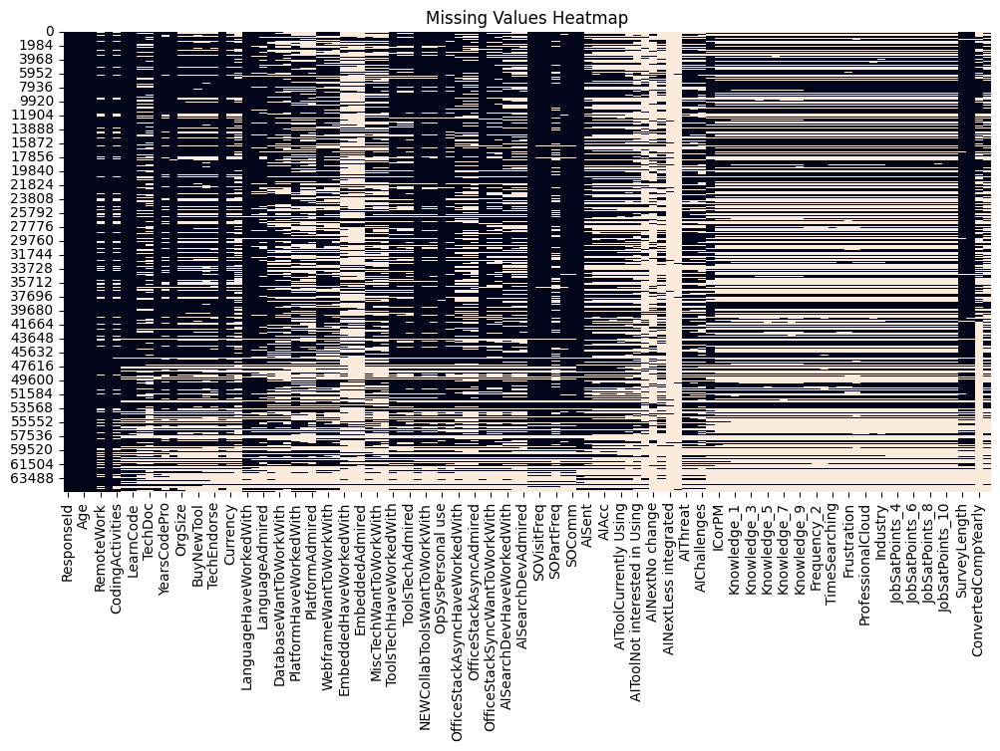

Missing values in Employment: 0
Most frequent Employment value: Employed, full-time
Missing values after imputation: 0


/tmp/ipykernel_1622/631825765.py:50: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


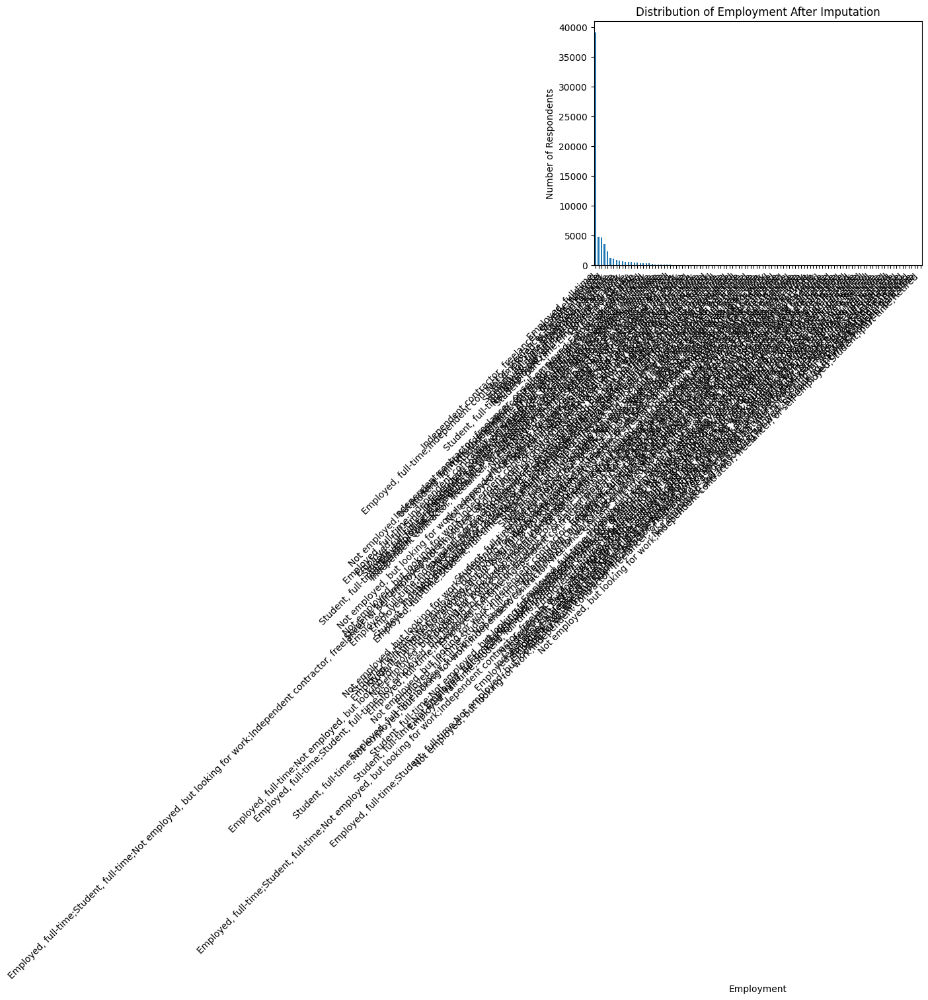

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# Define the URL of the dataset
file_path ="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv"

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Display the first few rows to ensure it loaded correctly
print(df.head())




# Task 1
df.info()
df.describe(include='all')

# Task 2
print(df.isnull().sum())

# Task 3

plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

# Task 4
print("Missing values in Employment:", df['Employment'].isnull().sum())

# Task 5
most_frequent_employment = df['Employment'].mode()[0]
print("Most frequent Employment value:", most_frequent_employment)

# Task 6
df['Employment'] = df['Employment'].fillna(most_frequent_employment)
print("Missing values after imputation:", df['Employment'].isnull().sum())

# Task 7
df['Employment'].value_counts().plot(kind='bar')
plt.title('Distribution of Employment After Imputation')
plt.xlabel('Employment')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Number of duplicate rows: 10
Duplicate rows after removal: 0
Missing values in CodingActivities: 10971
Missing values after forward-fill: 0
['CompTotal', 'AIComplex', 'ConvertedCompYearly']


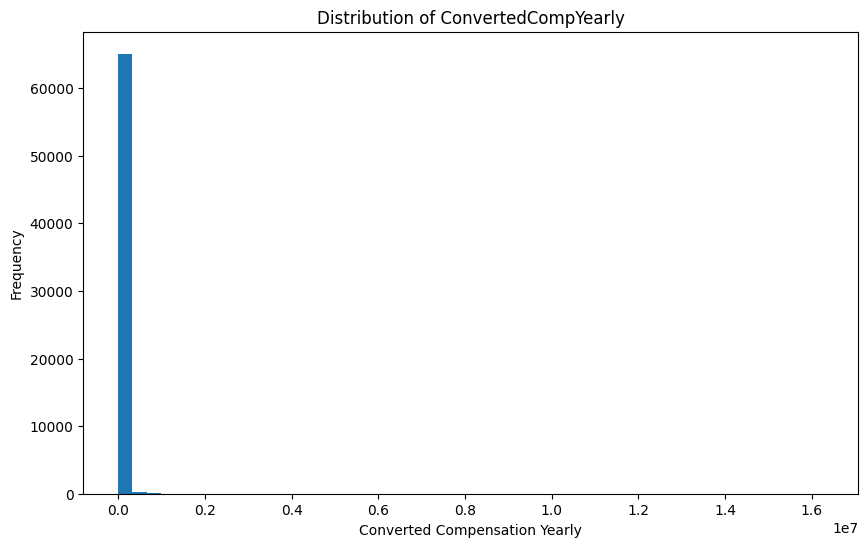

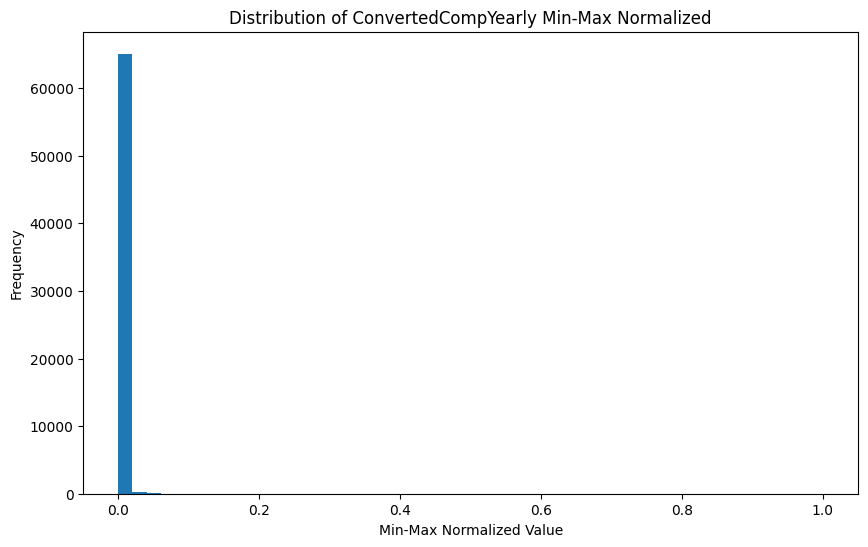

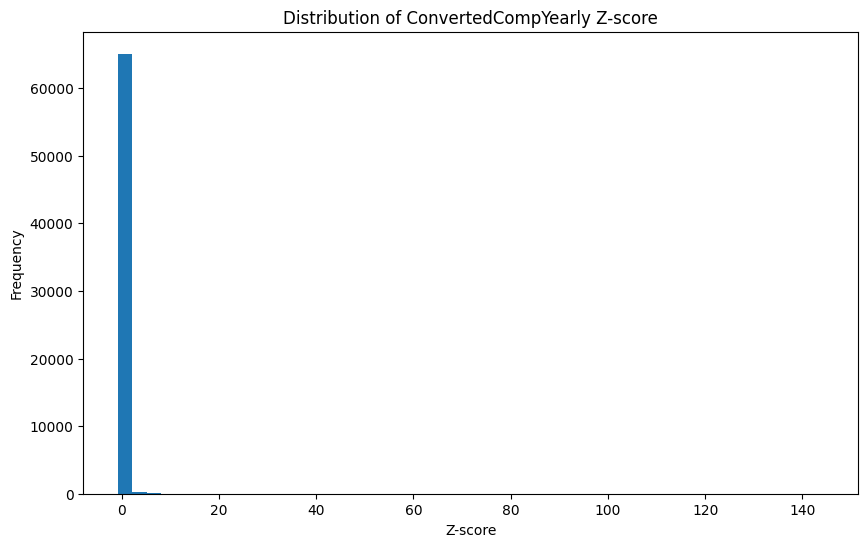

In [ ]:
# Task 1
print("Number of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows after removal:", df.duplicated().sum())


# Task 2
print("Missing values in CodingActivities:", df['CodingActivities'].isnull().sum())


# Task 3
df['CodingActivities'] = df['CodingActivities'].ffill()
print("Missing values after forward-fill:", df['CodingActivities'].isnull().sum())


# Task 4
compensation_columns = [col for col in df.columns if 'Comp' in col]
print(compensation_columns)


# Handle missing values before normalization
df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(
    df['ConvertedCompYearly'].median()
)


# Task 5 - Min-Max Scaling
min_value = df['ConvertedCompYearly'].min()
max_value = df['ConvertedCompYearly'].max()

df['ConvertedCompYearly_MinMax'] = (
    (df['ConvertedCompYearly'] - min_value) /
    (max_value - min_value)
)


# Task 6 - Z-score
mean_value = df['ConvertedCompYearly'].mean()
std_value = df['ConvertedCompYearly'].std()

df['ConvertedCompYearly_Zscore'] = (
    (df['ConvertedCompYearly'] - mean_value) /
    std_value
)


# Task 7 - Visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['ConvertedCompYearly'], bins=50)
plt.title('Distribution of ConvertedCompYearly')
plt.xlabel('Converted Compensation Yearly')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))
plt.hist(df['ConvertedCompYearly_MinMax'], bins=50)
plt.title('Distribution of ConvertedCompYearly Min-Max Normalized')
plt.xlabel('Min-Max Normalized Value')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))
plt.hist(df['ConvertedCompYearly_Zscore'], bins=50)
plt.title('Distribution of ConvertedCompYearly Z-score')
plt.xlabel('Z-score')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# ============================================
# 2. Explore the Dataset
# ============================================

# 2.1 Summarize the dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

# Create a summary table
summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Non-Null Count': df.notnull().sum(),
    'Missing Values': df.isnull().sum()
})

print("\nSummary Table:")
display(summary)


# 2.2 Generate basic statistics for numerical columns
print("\nBasic Statistics:")
display(df.describe())


# ============================================
# 3. Identifying and Removing Inconsistencies
# ============================================

# 3.1 Identify inconsistent or irrelevant entries in Country
print("\nUnique Country Values:")
print(df['Country'].unique())

print("\nCountry Counts:")
print(df['Country'].value_counts())


# 3.2 Standardize Country and EdLevel entries
df['Country'] = df['Country'].str.strip()
df['EdLevel'] = df['EdLevel'].str.strip()

# Example mapping for inconsistent country names
country_mapping = {
    'United States of America': 'United States',
    'USA': 'United States',
    'US': 'United States',
    'UK': 'United Kingdom'
}

df['Country'] = df['Country'].replace(country_mapping)


# ============================================
# 4. Encoding Categorical Variables
# ============================================

# 4.1 One-hot encode Employment
df = pd.get_dummies(df, columns=['Employment'], prefix='Employment')


# ============================================
# 5. Handling Missing Values
# ============================================

# 5.1 Identify columns with the highest number of missing values
missing_values = df.isnull().sum()
missing_values = missing_values.sort_values(ascending=False)

print("\nMissing Values by Column:")
print(missing_values[missing_values > 0])


# 5.2 Impute missing values in ConvertedCompYearly
median_compensation = df['ConvertedCompYearly'].median()

df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(
    median_compensation
)

print("\nMissing ConvertedCompYearly after imputation:")
print(df['ConvertedCompYearly'].isnull().sum())


# 5.3 Impute missing values in RemoteWork
most_frequent_remote = df['RemoteWork'].mode()[0]

df['RemoteWork'] = df['RemoteWork'].fillna(
    most_frequent_remote
)

print("\nMost frequent RemoteWork value:", most_frequent_remote)
print("Missing RemoteWork after imputation:",
      df['RemoteWork'].isnull().sum())


# ============================================
# 6. Feature Scaling and Transformation
# ============================================

# 6.1 Min-Max Scaling
min_value = df['ConvertedCompYearly'].min()
max_value = df['ConvertedCompYearly'].max()

df['ConvertedCompYearly_MinMax'] = (
    (df['ConvertedCompYearly'] - min_value) /
    (max_value - min_value)
)

print("\nMin-Max Scaled Compensation:")
display(
    df[['ConvertedCompYearly',
        'ConvertedCompYearly_MinMax']].head()
)


# 6.2 Log Transformation
import numpy as np

df['ConvertedCompYearly_Log'] = np.log1p(
    df['ConvertedCompYearly']
)

print("\nLog-Transformed Compensation:")
display(
    df[['ConvertedCompYearly',
        'ConvertedCompYearly_Log']].head()
)


# ============================================
# 7. Feature Engineering
# ============================================

# 7.1 Create ExperienceLevel based on YearsCodePro

# Convert YearsCodePro to numeric
df['YearsCodePro'] = pd.to_numeric(
    df['YearsCodePro'],
    errors='coerce'
)


# Define experience levels
def experience_level(years):
    if pd.isna(years):
        return 'Unknown'
    elif years < 2:
        return 'Entry Level'
    elif years < 5:
        return 'Junior'
    elif years < 10:
        return 'Mid Level'
    else:
        return 'Senior'


# Create new column
df['ExperienceLevel'] = df['YearsCodePro'].apply(
    experience_level
)


# Display the result
print("\nExperience Levels:")
display(
    df[['YearsCodePro',
        'ExperienceLevel']].head(10)
)


# ============================================
# Final Dataset Check
# ============================================

print("\nFinal Dataset Shape:")
print(df.shape)

print("\nFinal Dataset Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 65437 entries, 0 to 65436
Columns: 116 entries, ResponseId to ConvertedCompYearly_Zscore
dtypes: float64(15), int64(1), object(100)
memory usage: 58.4+ MB

Missing Values:
ResponseId                        0
MainBranch                        0
Age                               0
Employment                        0
RemoteWork                    10631
                              ...  
SurveyEase                     9199
ConvertedCompYearly               0
JobSat                        36311
ConvertedCompYearly_MinMax        0
ConvertedCompYearly_Zscore        0
Length: 116, dtype: int64

Summary Table:


,Data Type,Non-Null Count,Missing Values
ResponseId,int64,65437,0
MainBranch,object,65437,0
Age,object,65437,0
Employment,object,65437,0
RemoteWork,object,54806,10631
...,...,...,...
SurveyEase,object,56238,9199
ConvertedCompYearly,float64,65437,0
JobSat,float64,29126,36311
ConvertedCompYearly_MinMax,float64,65437,0



Basic Statistics:


,ResponseId,CompTotal,WorkExp,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,ConvertedCompYearly,JobSat,ConvertedCompYearly_MinMax,ConvertedCompYearly_Zscore
count,65437.000000,3.374000e+04,29658.000000,29324.000000,29393.000000,29411.000000,29450.000000,29448.00000,29456.000000,29456.000000,29450.000000,29445.000000,6.543700e+04,29126.000000,65437.000000,6.543700e+04
mean,32719.000000,2.963841e+145,11.466957,18.581094,7.522140,10.060857,24.343232,22.96522,20.278165,16.169432,10.955713,9.953948,7.257636e+04,6.935041,0.004464,-6.254453e-17
std,18890.179119,5.444117e+147,9.168709,25.966221,18.422661,21.833836,27.089360,27.01774,26.108110,24.845032,22.906263,21.775652,1.122207e+05,2.088259,0.006903,1.000000e+00
min,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000,0.000000,-6.467200e-01
25%,16360.000000,6.000000e+04,4.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,6.500000e+04,6.000000,0.003998,-6.751303e-02
50%,32719.000000,1.100000e+05,9.000000,10.000000,0.000000,0.000000,20.000000,15.00000,10.000000,5.000000,0.000000,0.000000,6.500000e+04,7.000000,0.003998,-6.751303e-02
75%,49078.000000,2.500000e+05,16.000000,22.000000,5.000000,10.000000,30.000000,30.00000,25.000000,20.000000,10.000000,10.000000,6.500000e+04,8.000000,0.003998,-6.751303e-02
max,65437.000000,1.000000e+150,50.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,1.625660e+07,10.000000,1.000000,1.442161e+02



Unique Country Values:
['United States of America'
 'United Kingdom of Great Britain and Northern Ireland' 'Canada' 'Norway'
 'Uzbekistan' 'Serbia' 'Poland' 'Philippines' 'Bulgaria' 'Switzerland'
 'India' 'Germany' 'Ireland' 'Italy' 'Ukraine' 'Australia' 'Brazil'
 'Japan' 'Austria' 'Iran, Islamic Republic of...' 'France' 'Saudi Arabia'
 'Romania' 'Turkey' 'Nepal' 'Algeria' 'Sweden' 'Netherlands' 'Croatia'
 'Pakistan' 'Czech Republic' 'Republic of North Macedonia' 'Finland'
 'Slovakia' 'Russian Federation' 'Greece' 'Israel' 'Belgium' 'Mexico'
 'United Republic of Tanzania' 'Hungary' 'Argentina' 'Portugal'
 'Sri Lanka' 'Latvia' 'China' 'Singapore' 'Lebanon' 'Spain' 'South Africa'
 'Lithuania' 'Viet Nam' 'Dominican Republic' 'Indonesia' 'Kosovo'
 'Morocco' 'Taiwan' 'Georgia' 'San Marino' 'Tunisia' 'Bangladesh'
 'Nigeria' 'Liechtenstein' 'Denmark' 'Ecuador' 'Malaysia' 'Albania'
 'Azerbaijan' 'Chile' 'Ghana' 'Peru' 'Bolivia' 'Egypt' 'Luxembourg'
 'Montenegro' 'Cyprus' 'Paraguay' 'Kazakhsta

,ConvertedCompYearly,ConvertedCompYearly_MinMax
0,65000.0,0.003998
1,65000.0,0.003998
2,65000.0,0.003998
3,65000.0,0.003998
4,65000.0,0.003998


... (2 outputs left out)


Experience Levels:


,YearsCodePro,ExperienceLevel
0,NaN,Unknown
1,17.0,Senior
2,27.0,Senior
3,NaN,Unknown
4,NaN,Unknown
5,NaN,Unknown
6,7.0,Mid Level
7,NaN,Unknown
8,NaN,Unknown
9,11.0,Senior



Final Dataset Shape:
(65437, 227)

Final Dataset Columns:
['ResponseId', 'MainBranch', 'Age', 'RemoteWork', 'Check', 'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline', 'TechDoc', 'YearsCode', 'YearsCodePro', 'DevType', 'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'BuildvsBuy', 'TechEndorse', 'Country', 'Currency', 'CompTotal', 'LanguageHaveWorkedWith', 'LanguageWantToWorkWith', 'LanguageAdmired', 'DatabaseHaveWorkedWith', 'DatabaseWantToWorkWith', 'DatabaseAdmired', 'PlatformHaveWorkedWith', 'PlatformWantToWorkWith', 'PlatformAdmired', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'EmbeddedHaveWorkedWith', 'EmbeddedWantToWorkWith', 'EmbeddedAdmired', 'MiscTechHaveWorkedWith', 'MiscTechWantToWorkWith', 'MiscTechAdmired', 'ToolsTechHaveWorkedWith', 'ToolsTechWantToWorkWith', 'ToolsTechAdmired', 'NEWCollabToolsHaveWorkedWith', 'NEWCollabToolsWantToWorkWith', 'NEWCollabToolsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'OfficeStackAsyncHaveW

,ResponseId,MainBranch,Age,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,...,"Employment_Student, full-time;Not employed, but looking for work;Student, part-time","Employment_Student, full-time;Retired","Employment_Student, full-time;Student, part-time","Employment_Student, full-time;Student, part-time;Employed, part-time","Employment_Student, full-time;Student, part-time;Retired","Employment_Student, part-time","Employment_Student, part-time;Employed, part-time","Employment_Student, part-time;Retired",ConvertedCompYearly_Log,ExperienceLevel
0,1,I am a developer by profession,Under 18 years old,Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,...,False,False,False,False,False,False,False,False,11.082158,Unknown
1,2,I am a developer by profession,35-44 years old,Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,...,False,False,False,False,False,False,False,False,11.082158,Senior
2,3,I am a developer by profession,45-54 years old,Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,...,False,False,False,False,False,False,False,False,11.082158,Senior
3,4,I am learning to code,18-24 years old,"Hybrid (some remote, some in-person)",Apples,Hobby;Contribute to open-source projects;Other...,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,NaN,...,False,False,False,False,False,False,False,False,11.082158,Unknown
4,5,I am a developer by profession,18-24 years old,"Hybrid (some remote, some in-person)",Apples,Hobby;Contribute to open-source projects;Other...,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,API document(s) and/or SDK document(s);User gu...,...,False,False,False,False,False,False,False,False,11.082158,Unknown


In [ ]:
# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Set pandas option to display all columns
pd.set_option('display.max_columns', None)

# Display the first few rows of the dataset
df.head()

# Check missing values in critical columns
print("Missing values before handling:")
print(df[['Employment', 'JobSat', 'RemoteWork']].isnull().sum())


# Fill missing values with the most frequent value (mode)

df['Employment'] = df['Employment'].fillna(
    df['Employment'].mode()[0]
)

df['JobSat'] = df['JobSat'].fillna(
    df['JobSat'].mode()[0]
)

df['RemoteWork'] = df['RemoteWork'].fillna(
    df['RemoteWork'].mode()[0]
)


# Check missing values after handling
print("\nMissing values after handling:")
print(df[['Employment', 'JobSat', 'RemoteWork']].isnull().sum())

Missing values before handling:
Employment        0
JobSat        36311
RemoteWork    10631
dtype: int64

Missing values after handling:
Employment    0
JobSat        0
RemoteWork    0
dtype: int64


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,EmbeddedHaveWorkedWith,EmbeddedWantToWorkWith,EmbeddedAdmired,MiscTechHaveWorkedWith,MiscTechWantToWorkWith,MiscTechAdmired,ToolsTechHaveWorkedWith,ToolsTechWantToWorkWith,ToolsTechAdmired,NEWCollabToolsHaveWorkedWith,NEWCollabToolsWantToWorkWith,NEWCollabToolsAdmired,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackSyncHaveWorkedWith,OfficeStackSyncWantToWorkWith,OfficeStackSyncAdmired,AISearchDevHaveWorkedWith,AISearchDevWantToWorkWith,AISearchDevAdmired,NEWSOSites,SOVisitFreq,SOAccount,SOPartFreq,SOHow,SOComm,AISelect,AISent,AIBen,AIAcc,AIComplex,AIToolCurrently Using,AIToolInterested in Using,AIToolNot interested in Using,AINextMuch more integrated,AINextNo change,AINextMore integrated,AINextLess integrated,AINextMuch less integrated,AIThreat,AIEthics,AIChallenges,TBranch,ICorPM,WorkExp,Knowledge_1,Knowledge_2,Knowledge_3,Knowledge_4,Knowledge_5,Knowledge_6,Knowledge_7,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I have never visited Stack Overflow or the Sta...,NaN,NaN,NaN,NaN,NaN,Yes,Very favorable,Increase productivity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Dynamodb;MongoDB;PostgreSQL,PostgreSQL,PostgreSQL,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Express;Next.js;Node.js;React,Express;Htmx;Node.js;React;Remix,Express;Node.js;React,NaN,NaN,NaN,NaN,NaN,NaN,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,MacOS;Windows,MacOS,NaN,NaN,NaN,Microsoft Teams;Slack,Slack,Slack,NaN,NaN,NaN,Stack Overflow for Teams (private knowledge sh...,Multiple times per day,Yes,Multiple times per day,Quickly finding code solutions;Finding reliabl...,"Yes, definitely","No, and I don't plan to",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes,Individual contributor,17.0,Agree,Disagree,Agree,Agree,Agree,Neither agree nor disa

Median Job Satisfaction by Experience Range:
ExperienceRange
0-5     NaN
10-20   NaN
5-10    NaN
>20     NaN
Name: JobSat_numeric, dtype: float64


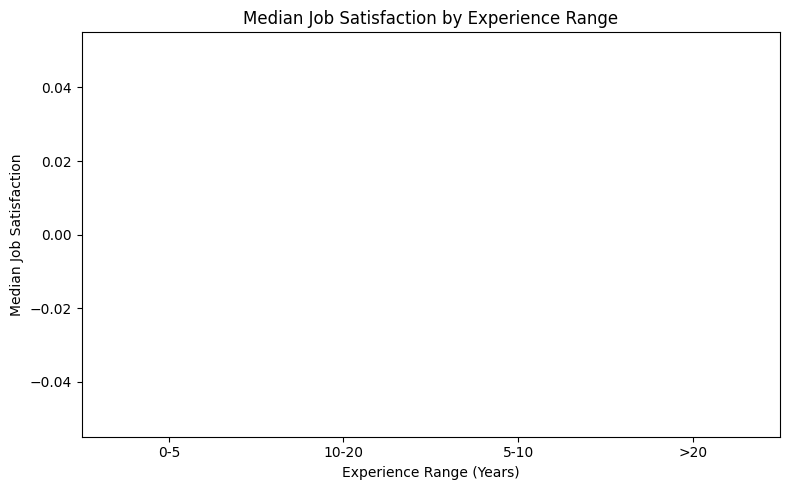

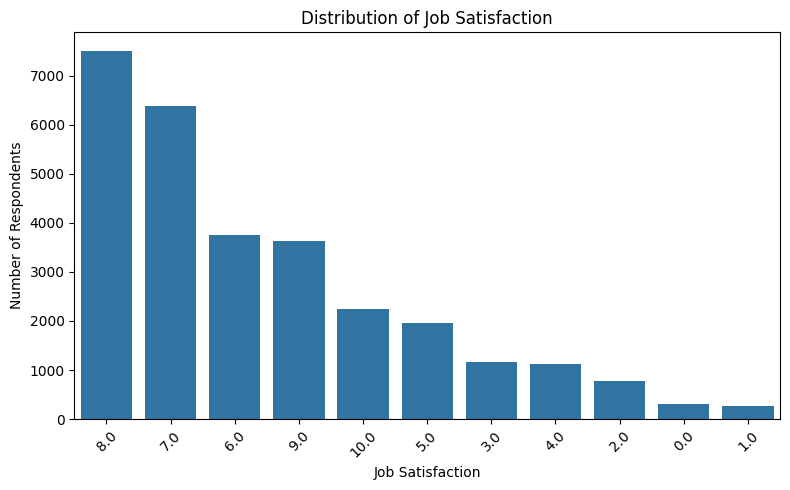

Remote Work Preferences by Employment Type:


RemoteWork,"Hybrid (some remote, some in-person)",In-person,Remote
Employment,,,
"Employed, full-time",17281,8552,13193
"Employed, full-time;Employed, part-time",85,32,95
"Employed, full-time;Independent contractor, freelancer, or self-employed",1330,366,1861
"Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time",80,17,87
"Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time;Retired",0,1,0
...,...,...,...
"Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work;Student, part-time",1,0,1
"Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Student, part-time",2,0,3
"Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Student, part-time;Employed, part-time;Retired",1,0,0


/tmp/ipykernel_1622/3107352480.py:131: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


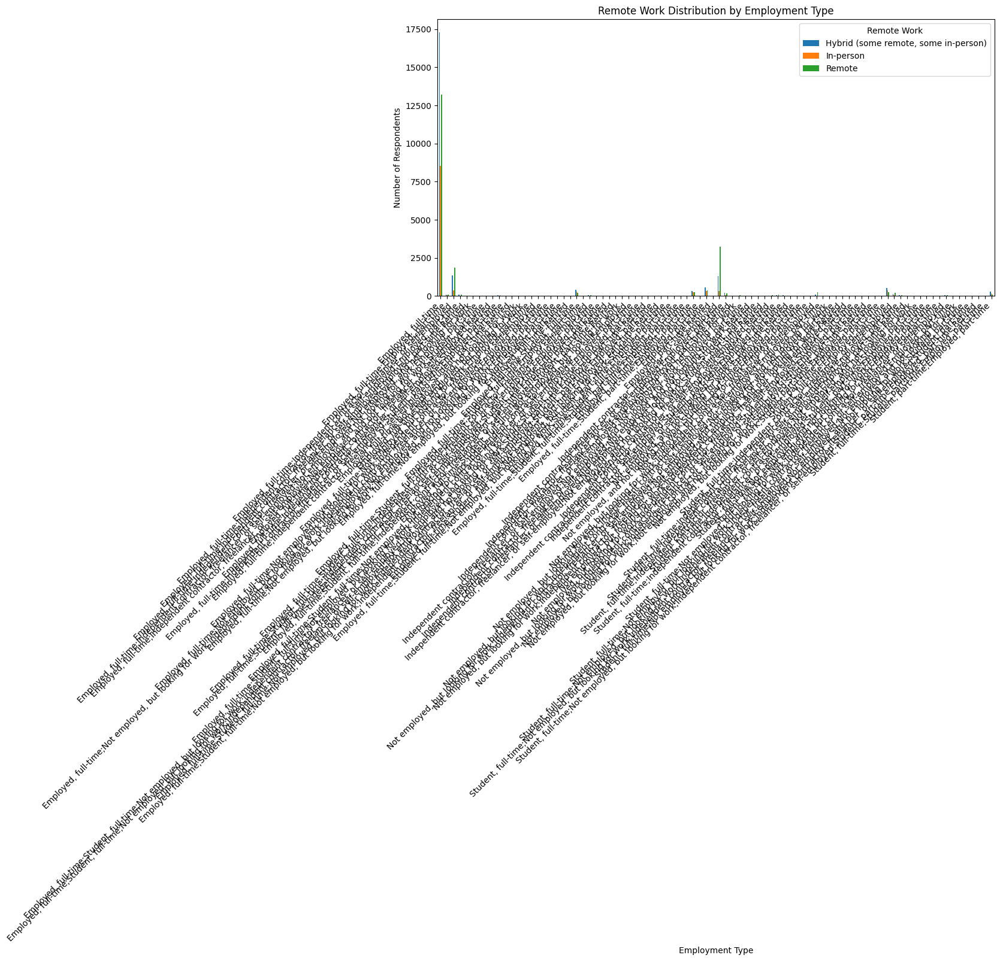

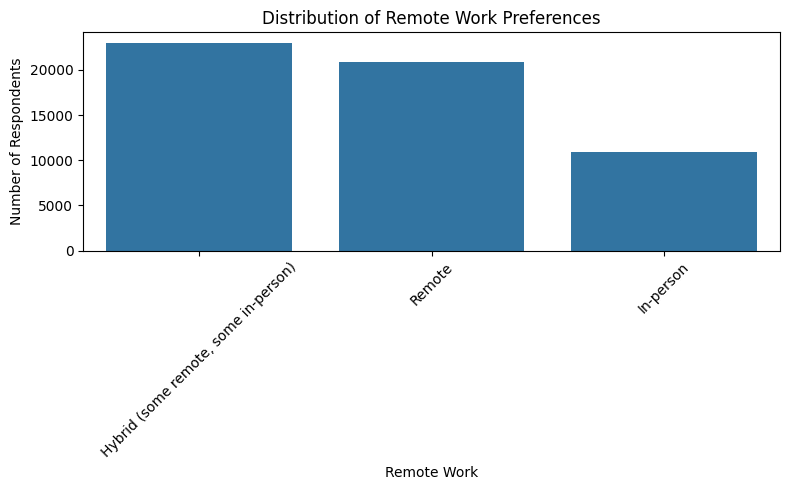

Top Programming Languages in Canada
JavaScript                 1296
Python                     1118
HTML/CSS                   1097
SQL                        1073
Bash/Shell (all shells)     798
TypeScript                  796
C#                          603
Java                        571
C++                         488
C                           415
dtype: int64


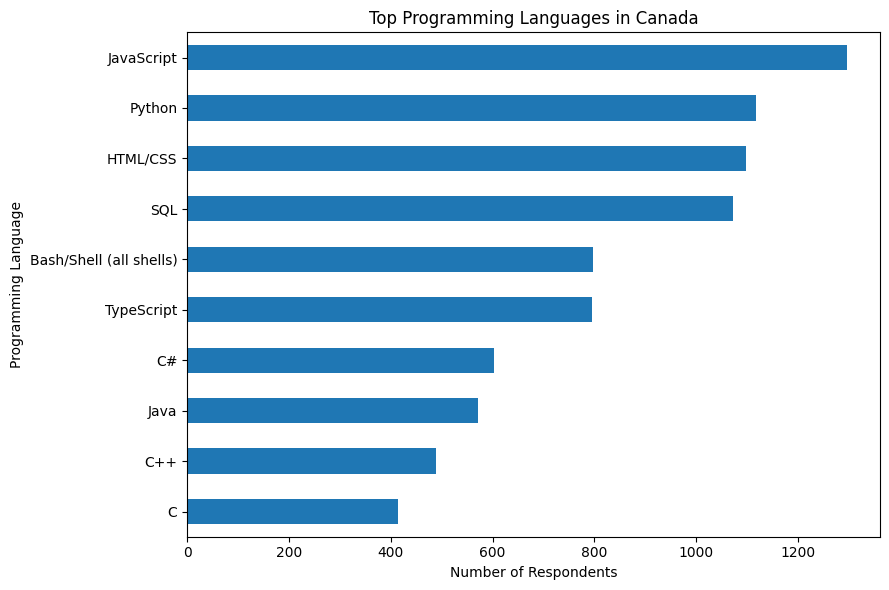

Correlation between YearsCodePro and JobSatPoints_1:
                YearsCodePro  JobSatPoints_1
YearsCodePro        1.000000       -0.032846
JobSatPoints_1     -0.032846        1.000000


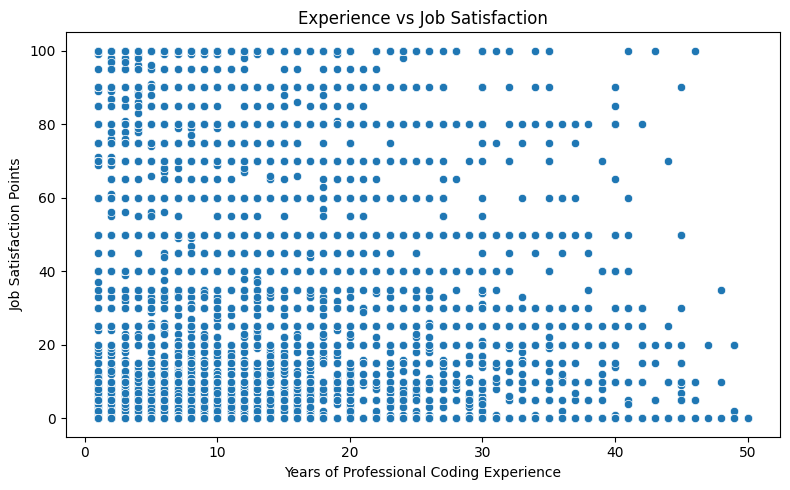

Educational Background vs Employment Type:


Employment,"Employed, full-time","Employed, full-time;Employed, part-time","Employed, full-time;Independent contractor, freelancer, or self-employed","Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time","Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time;Retired","Employed, full-time;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work","Employed, full-time;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work;Employed, part-time","Employed, full-time;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work;Student, part-time","Employed, full-time;Independent contractor, freelancer, or self-employed;Retired","Employed, full-time;Independent contractor, freelancer, or self-employed;Student, part-time","Employed, full-time;Independent contractor, freelancer, or self-employed;Student, part-time;Employed, part-time","Employed, full-time;Independent contractor, freelancer, or self-employed;Student, part-time;Retired","Employed, full-time;Not employed, and not looking for work","Employed, full-time;Not employed, but looking for work","Employed, full-time;Not employed, but looking for work;Employed, part-time","Employed, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed","Employed, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Employed, part-time","Employed, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work;Employed, part-time","Employed, full-time;Not employed, but looking for work;Not employed, and not looking for work;Employed, part-time","Employed, full-time;Retired","Employed, full-time;Student, full-time","Employed, full-time;Student, full-time;Employed, part-time","Employed, full-time;Student, full-time;Independent contractor, freelancer, or self-employed","Employed, full-time;Student, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time","Employed, full-time;Student, full-time;Independent contractor, freelancer, or self-employed;Student, part-time;Employed, part-time","Employed, full-time;Student, full-time;Independent contractor, freelancer, or self-employed;Student, part-time;Employed, part-time;Retired","Employed, full-time;Student, full-time;Independent contractor, freelancer, or self-employed;Student, part-time;Retired","Employed, full-time;Student, full-time;Not employed, but looking for work","Employed, full-time;Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed","Employed, full-time;Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Employed, part-time","Employed, full-time;Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work;Student, part-time;Employed, part-time","Employed, full-time;Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Not employed, and not looking for work;Student, part-time;Employed, part-time;Retired","Employed, full-time;Student, full-time;Not employed, but looking for work;Independent contractor, freelancer, or self-employed;Student, part-time;Employed, part-time","Employed, full-time;Student, full-time;Not employed, but looking for work;Student, part-time","Employed, full-time;Student, full-time;Not employed, but looking for work;Student, part-time;Employed, part-time","Employed, full-time;Student, full-time;Student, part-time","Employed, full-time;Student, full-time;Student, part-time;Employed, part-time","Employed, full-time;Student, part-time","Employed, full-time;Student, part-time;Employed, part-time","Employed, part-time","Empl

/tmp/ipykernel_1622/3107352480.py:265: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


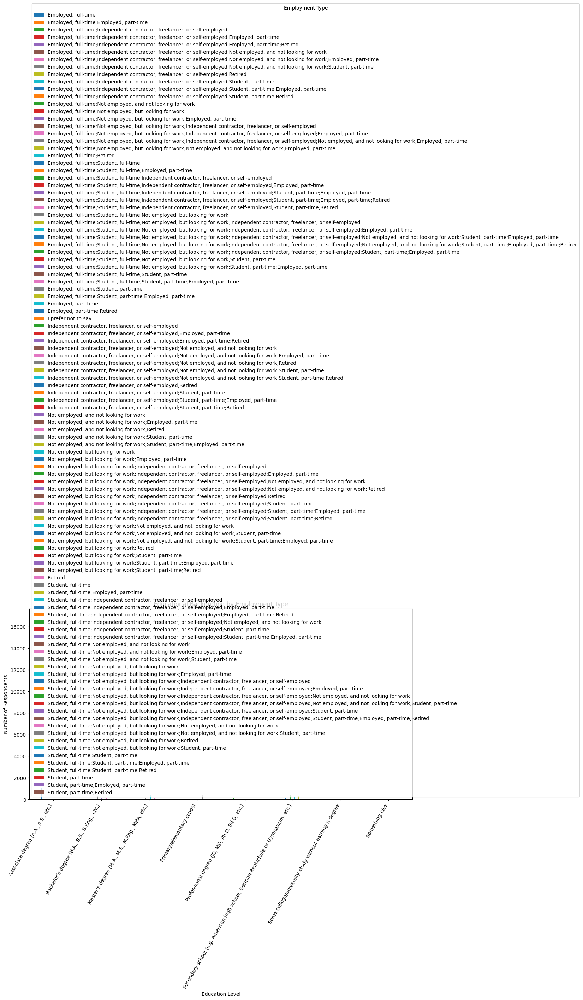

Dataset saved successfully as: cleaned_analyzed_survey_data.csv


In [ ]:
# ============================================
# Load the Stack Overflow Survey Dataset
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'

df = pd.read_csv(data_url)

# Display all columns
pd.set_option('display.max_columns', None)

# Display first few rows
display(df.head())


# ============================================
# Step 4: Analysis of Experience and Job Satisfaction
# ============================================

# Convert YearsCodePro to numeric
df['YearsCodePro'] = pd.to_numeric(
    df['YearsCodePro'],
    errors='coerce'
)


# Convert JobSat to numeric
job_sat_mapping = {
    'Very dissatisfied': 1,
    'Slightly dissatisfied': 2,
    'Neither satisfied nor dissatisfied': 3,
    'Slightly satisfied': 4,
    'Very satisfied': 5
}

df['JobSat_numeric'] = df['JobSat'].map(job_sat_mapping)


# Create experience ranges
def create_experience_range(years):
    if pd.isna(years):
        return np.nan
    elif years <= 5:
        return '0-5'
    elif years <= 10:
        return '5-10'
    elif years <= 20:
        return '10-20'
    else:
        return '>20'


df['ExperienceRange'] = df['YearsCodePro'].apply(
    create_experience_range
)


# Calculate median JobSat for each experience range
median_satisfaction = df.groupby(
    'ExperienceRange',
    observed=False
)['JobSat_numeric'].median()

print("Median Job Satisfaction by Experience Range:")
print(median_satisfaction)


# Visualize median satisfaction
plt.figure(figsize=(8, 5))

median_satisfaction.plot(kind='bar')

plt.title('Median Job Satisfaction by Experience Range')
plt.xlabel('Experience Range (Years)')
plt.ylabel('Median Job Satisfaction')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================
# Step 5: Visualize Job Satisfaction
# ============================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='JobSat',
    order=df['JobSat'].value_counts().index
)

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================
# Step 6: Analyzing Remote Work Preferences
# ============================================

# Cross-tabulate RemoteWork and Employment
remote_employment = pd.crosstab(
    df['Employment'],
    df['RemoteWork']
)

print("Remote Work Preferences by Employment Type:")
display(remote_employment)


# Visualize remote work by employment type
remote_employment.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Remote Work Distribution by Employment Type')
plt.xlabel('Employment Type')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Remote Work')
plt.tight_layout()
plt.show()


# Count plot for RemoteWork
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='RemoteWork',
    order=df['RemoteWork'].value_counts().index
)

plt.title('Distribution of Remote Work Preferences')
plt.xlabel('Remote Work')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================
# Step 7: Programming Language Trends by Region
# ============================================

# Select a country
country = 'Canada'

# Filter data for Canada
country_data = df[df['Country'] == country].copy()


# Count programming languages
language_counts = {}

for languages in country_data['LanguageHaveWorkedWith'].dropna():

    for language in languages.split(';'):

        language = language.strip()

        if language:
            language_counts[language] = (
                language_counts.get(language, 0) + 1
            )


# Convert to Series
language_counts = pd.Series(language_counts)

# Select top 10 languages
top_languages = language_counts.sort_values(
    ascending=False
).head(10)

print("Top Programming Languages in", country)
print(top_languages)


# Visualize top programming languages
plt.figure(figsize=(9, 6))

top_languages.sort_values().plot(
    kind='barh'
)

plt.title(f'Top Programming Languages in {country}')
plt.xlabel('Number of Respondents')
plt.ylabel('Programming Language')
plt.tight_layout()
plt.show()


# ============================================
# Step 8: Correlation Between Experience and Satisfaction
# ============================================

# Convert JobSatPoints_1 to numeric
df['JobSatPoints_1'] = pd.to_numeric(
    df['JobSatPoints_1'],
    errors='coerce'
)


# Calculate correlation
correlation = df[
    ['YearsCodePro', 'JobSatPoints_1']
].corr()

print("Correlation between YearsCodePro and JobSatPoints_1:")
print(correlation)


# Scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='YearsCodePro',
    y='JobSatPoints_1'
)

plt.title('Experience vs Job Satisfaction')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Job Satisfaction Points')
plt.tight_layout()
plt.show()


# ============================================
# Step 9: Educational Background and Employment
# ============================================

# Cross-tabulation
education_employment = pd.crosstab(
    df['EdLevel'],
    df['Employment']
)

print("Educational Background vs Employment Type:")
display(education_employment)


# Visualize education vs employment
education_employment.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Educational Background by Employment Type')
plt.xlabel('Education Level')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=60, ha='right')
plt.legend(title='Employment Type')
plt.tight_layout()
plt.show()


# ============================================
# Step 10: Save the Cleaned and Analyzed Dataset
# ============================================

output_file = 'cleaned_analyzed_survey_data.csv'

df.to_csv(
    output_file,
    index=False
)

print("Dataset saved successfully as:", output_file)

Dataset Shape:
(65437, 116)

Column Names:
['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check', 'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline', 'TechDoc', 'YearsCode', 'YearsCodePro', 'DevType', 'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'BuildvsBuy', 'TechEndorse', 'Country', 'Currency', 'CompTotal', 'LanguageHaveWorkedWith', 'LanguageWantToWorkWith', 'LanguageAdmired', 'DatabaseHaveWorkedWith', 'DatabaseWantToWorkWith', 'DatabaseAdmired', 'PlatformHaveWorkedWith', 'PlatformWantToWorkWith', 'PlatformAdmired', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'EmbeddedHaveWorkedWith', 'EmbeddedWantToWorkWith', 'EmbeddedAdmired', 'MiscTechHaveWorkedWith', 'MiscTechWantToWorkWith', 'MiscTechAdmired', 'ToolsTechHaveWorkedWith', 'ToolsTechWantToWorkWith', 'ToolsTechAdmired', 'NEWCollabToolsHaveWorkedWith', 'NEWCollabToolsWantToWorkWith', 'NEWCollabToolsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'OfficeStackAsyncHaveWor

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,EmbeddedHaveWorkedWith,EmbeddedWantToWorkWith,EmbeddedAdmired,MiscTechHaveWorkedWith,MiscTechWantToWorkWith,MiscTechAdmired,ToolsTechHaveWorkedWith,ToolsTechWantToWorkWith,ToolsTechAdmired,NEWCollabToolsHaveWorkedWith,NEWCollabToolsWantToWorkWith,NEWCollabToolsAdmired,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackSyncHaveWorkedWith,OfficeStackSyncWantToWorkWith,OfficeStackSyncAdmired,AISearchDevHaveWorkedWith,AISearchDevWantToWorkWith,AISearchDevAdmired,NEWSOSites,SOVisitFreq,SOAccount,SOPartFreq,SOHow,SOComm,AISelect,AISent,AIBen,AIAcc,AIComplex,AIToolCurrently Using,AIToolInterested in Using,AIToolNot interested in Using,AINextMuch more integrated,AINextNo change,AINextMore integrated,AINextLess integrated,AINextMuch less integrated,AIThreat,AIEthics,AIChallenges,TBranch,ICorPM,WorkExp,Knowledge_1,Knowledge_2,Knowledge_3,Knowledge_4,Knowledge_5,Knowledge_6,Knowledge_7,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat,JobSat_numeric,ExperienceRange
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I have never visited Stack Overflow or the Sta...,NaN,NaN,NaN,NaN,NaN,Yes,Very favorable,Increase productivity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17.0,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Dynamodb;MongoDB;PostgreSQL,PostgreSQL,PostgreSQL,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Express;Next.js;Node.js;React,Express;Htmx;Node.js;React;Remix,Express;Node.js;React,NaN,NaN,NaN,NaN,NaN,NaN,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,MacOS;Windows,MacOS,NaN,NaN,NaN,Microsoft Teams;Slack,Slack,Slack,NaN,NaN,NaN,Stack Overflow for Teams (private knowledge sh...,Multiple times per day,Yes,Multiple times per day,Quickly finding code solutions;Finding reliabl...,"Yes, definitely","No, and I don't plan to",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes,Individual contributor,17.0,Agree,Disagree


Missing Values in Each Column:
ResponseId                 0
MainBranch                 0
Age                        0
Employment                 0
RemoteWork             10631
                       ...  
SurveyEase              9199
ConvertedCompYearly    42002
JobSat                 36311
JobSat_numeric         65437
ExperienceRange        16733
Length: 116, dtype: int64

Percentage of Missing Values:
JobSat_numeric                100.000000
AINextMuch less integrated     98.245641
AINextLess integrated          96.401119
AINextNo change                80.900714
AINextMuch more integrated     79.464217
                                 ...    
Employment                      0.000000
Check                           0.000000
Age                             0.000000
MainBranch                      0.000000
ResponseId                      0.000000
Length: 116, dtype: float64

Missing Values After Handling:
Employment      0
JobSat          0
RemoteWork      0
YearsCodePro    0
dtype: in

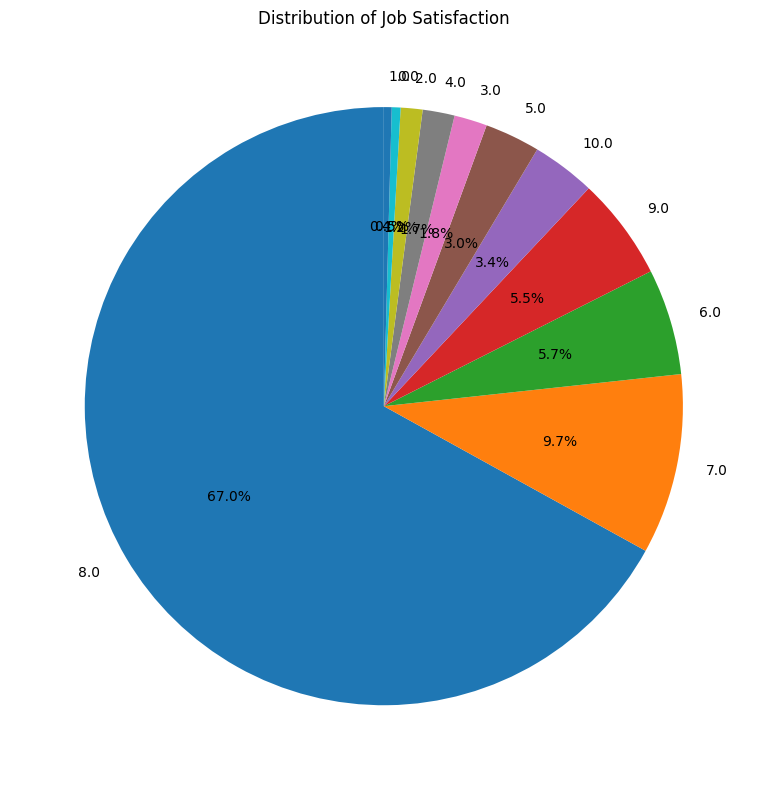


Programming Language Comparison:


,Worked With,Want to Work With
Bash/Shell (all shells),20412.0,13744.0
C,12184.0,0.0
C#,16318.0,12921.0
C++,13827.0,10873.0
Go,0.0,13837.0
HTML/CSS,31816.0,20721.0
Java,18239.0,0.0
JavaScript,37492.0,23774.0
Python,30719.0,25047.0
Rust,0.0,17232.0


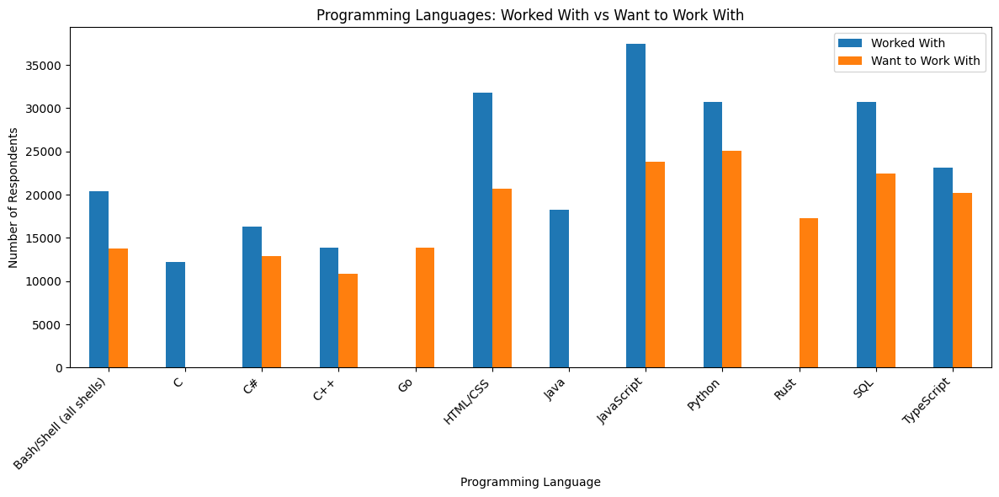


Remote Work by Top 10 Countries:


RemoteWork,"Hybrid (some remote, some in-person)",In-person,Remote
Country,,,
United States of America,4857,1472,4766
Germany,3098,647,1202
India,2290,1088,853
United Kingdom of Great Britain and Northern Ireland,1765,307,1152
Ukraine,828,111,1733
France,1344,357,409
Canada,970,227,907
Poland,686,134,714
Netherlands,1028,240,181


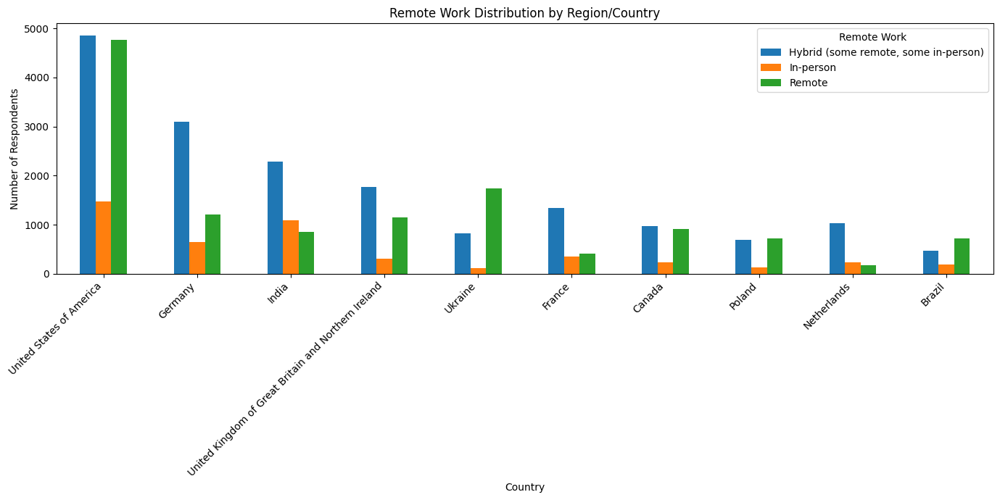


Pearson Correlation between YearsCodePro and JobSat:
nan


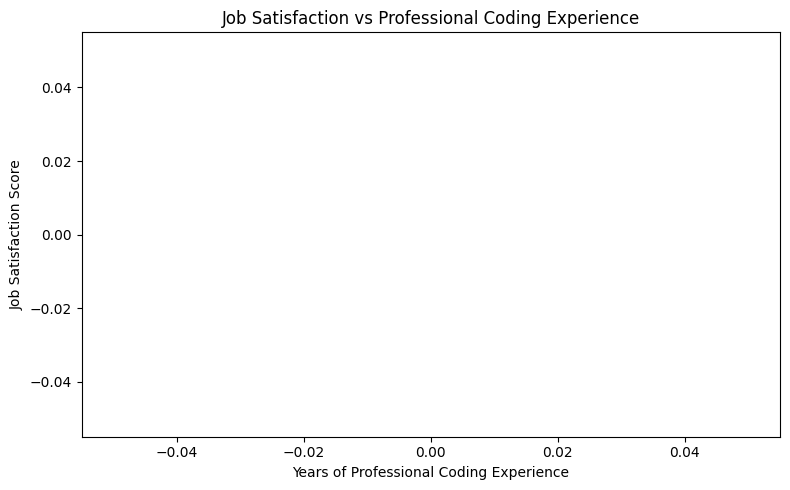


Employment vs Education Level:


EdLevel,"Associate degree (A.A., A.S., etc.)","Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Primary/elementary school,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",Some college/university study without earning a degree,Something else
Employment,,,,,,,,
"Employed, full-time",1059,16806,11011,160,2073,1460,3579,377
"Employed, full-time;Employed, part-time",9,90,61,1,8,9,15,3
"Employed, full-time;Independent contractor, freelancer, or self-employed",104,1381,963,25,159,181,492,41
"Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time",11,79,45,1,10,6,14,2
"Employed, full-time;Independent contractor, freelancer, or self-employed;Employed, part-time;Retired",0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...
"Student, full-time;Student, part-time;Employed, part-time",0,1,1,1,0,0,4,0
"Student, full-time;Student, part-time;Retired",0,0,0,1,0,1,0,0
"Student, part-time",12,105,26,48,5,140,75,17


/tmp/ipykernel_1622/233700844.py:281: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


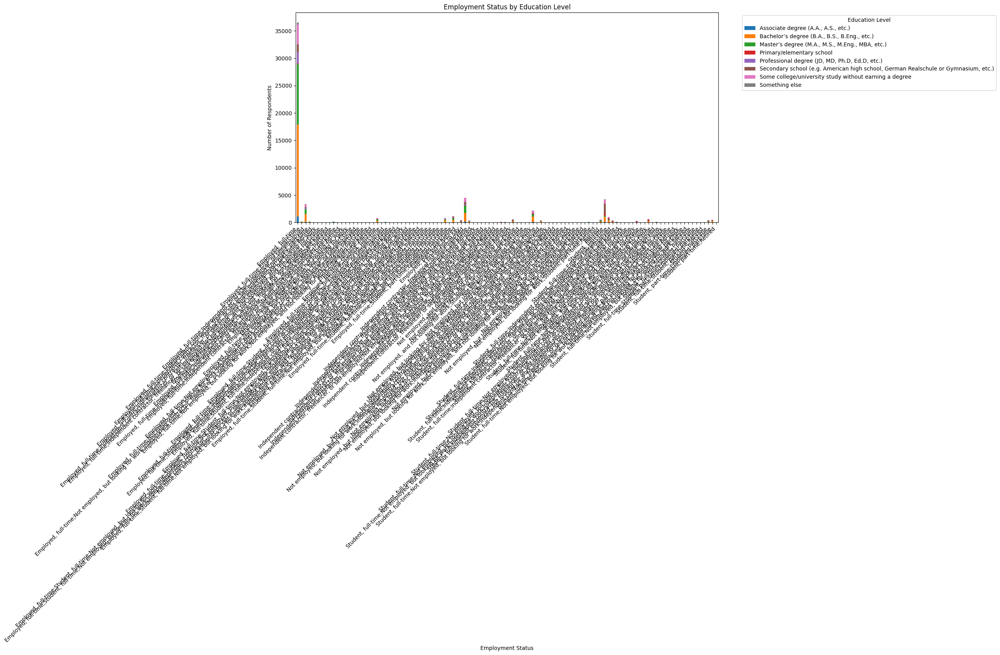


Cleaned dataset saved successfully as:
cleaned_stackoverflow_survey.csv


In [ ]:
# ============================================
# Step 2: Examine the Structure of the Data
# ============================================

# Display the shape of the dataset
print("Dataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types and non-null information
print("\nDataset Information:")
df.info()

# Display first few rows
print("\nFirst 5 Rows:")
display(df.head())


# ============================================
# Step 3: Handle Missing Data
# ============================================

# Identify missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# Display percentage of missing values
print("\nPercentage of Missing Values:")
print((df.isnull().sum() / len(df) * 100).sort_values(ascending=False))

# Fill missing categorical values with the most frequent value
categorical_columns = ['Employment', 'JobSat', 'RemoteWork']

for column in categorical_columns:
    if column in df.columns:
        if df[column].isnull().sum() > 0:
            df[column] = df[column].fillna(df[column].mode()[0])

# Fill missing YearsCodePro with the median
if 'YearsCodePro' in df.columns:
    df['YearsCodePro'] = pd.to_numeric(
        df['YearsCodePro'],
        errors='coerce'
    )

    df['YearsCodePro'] = df['YearsCodePro'].fillna(
        df['YearsCodePro'].median()
    )

# Check missing values after handling
print("\nMissing Values After Handling:")
print(df[['Employment', 'JobSat', 'RemoteWork', 'YearsCodePro']].isnull().sum())


# ============================================
# Step 4: Analyze Key Columns
# ============================================

# Employment distribution
print("\nEmployment Distribution:")
print(df['Employment'].value_counts())

# Job Satisfaction distribution
print("\nJob Satisfaction Distribution:")
print(df['JobSat'].value_counts())

# Professional Coding Experience distribution
print("\nYears of Professional Coding Experience:")
print(df['YearsCodePro'].value_counts().sort_index())


# ============================================
# Step 5: Visualize Job Satisfaction
# ============================================

# Count JobSat values
job_sat_counts = df['JobSat'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    job_sat_counts,
    labels=job_sat_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Job Satisfaction')
plt.tight_layout()
plt.show()


# ============================================
# Step 6: Programming Languages Analysis
# ============================================

# Count languages people have worked with
worked_languages = {}

for languages in df['LanguageHaveWorkedWith'].dropna():
    for language in languages.split(';'):
        language = language.strip()

        if language:
            worked_languages[language] = (
                worked_languages.get(language, 0) + 1
            )


# Count languages people want to work with
wanted_languages = {}

for languages in df['LanguageWantToWorkWith'].dropna():
    for language in languages.split(';'):
        language = language.strip()

        if language:
            wanted_languages[language] = (
                wanted_languages.get(language, 0) + 1
            )


# Convert to Series
worked_languages = pd.Series(worked_languages)
wanted_languages = pd.Series(wanted_languages)


# Get top 10 languages from both columns
top_worked = worked_languages.sort_values(
    ascending=False
).head(10)

top_wanted = wanted_languages.sort_values(
    ascending=False
).head(10)


# Create combined DataFrame
language_comparison = pd.DataFrame({
    'Worked With': top_worked,
    'Want to Work With': top_wanted
}).fillna(0)

print("\nProgramming Language Comparison:")
display(language_comparison)


# Grouped bar chart
language_comparison.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Programming Languages: Worked With vs Want to Work With')
plt.xlabel('Programming Language')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


# ============================================
# Step 7: Analyze Remote Work Trends
# ============================================

# Create a region/country column using Country
remote_region = pd.crosstab(
    df['Country'],
    df['RemoteWork']
)

# Select top 10 countries by total respondents
top_countries = remote_region.sum(
    axis=1
).sort_values(
    ascending=False
).head(10).index

remote_region_top = remote_region.loc[top_countries]

print("\nRemote Work by Top 10 Countries:")
display(remote_region_top)


# Grouped bar chart
remote_region_top.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Remote Work Distribution by Region/Country')
plt.xlabel('Country')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Remote Work')
plt.tight_layout()
plt.show()


# ============================================
# Step 8: Correlation between Job Satisfaction
# and Experience
# ============================================

# Convert JobSat into numerical values
job_sat_mapping = {
    'Very dissatisfied': 1,
    'Slightly dissatisfied': 2,
    'Neither satisfied nor dissatisfied': 3,
    'Slightly satisfied': 4,
    'Very satisfied': 5
}

df['JobSat_numeric'] = df['JobSat'].map(
    job_sat_mapping
)


# Calculate Pearson correlation
correlation = df[
    ['YearsCodePro', 'JobSat_numeric']
].corr(method='pearson').iloc[0, 1]

print("\nPearson Correlation between YearsCodePro and JobSat:")
print(correlation)


# Scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='YearsCodePro',
    y='JobSat_numeric'
)

plt.title('Job Satisfaction vs Professional Coding Experience')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Job Satisfaction Score')
plt.tight_layout()
plt.show()


# ============================================
# Step 9: Cross-tabulation Analysis
# Employment vs Education Level
# ============================================

# Create cross-tabulation
employment_education = pd.crosstab(
    df['Employment'],
    df['EdLevel']
)

print("\nEmployment vs Education Level:")
display(employment_education)


# Create stacked bar plot
employment_education.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title('Employment Status by Education Level')
plt.xlabel('Employment Status')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(
    title='Education Level',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


# ============================================
# Step 10: Export Cleaned Data
# ============================================

output_file = 'cleaned_stackoverflow_survey.csv'

df.to_csv(
    output_file,
    index=False
)

print("\nCleaned dataset saved successfully as:")
print(output_file)

Industry Distribution:
Industry
Software Development                          11918
Other:                                         3077
Fintech                                        1641
Internet, Telecomm or Information Services     1629
Banking/Financial Services                     1371
Healthcare                                     1277
Manufacturing                                  1265
Retail and Consumer Services                   1264
Government                                      962
Media & Advertising Services                    894
Higher Education                                890
Transportation, or Supply Chain                 859
Computer Systems Design and Services            844
Energy                                          578
Insurance                                       389
Name: count, dtype: int64


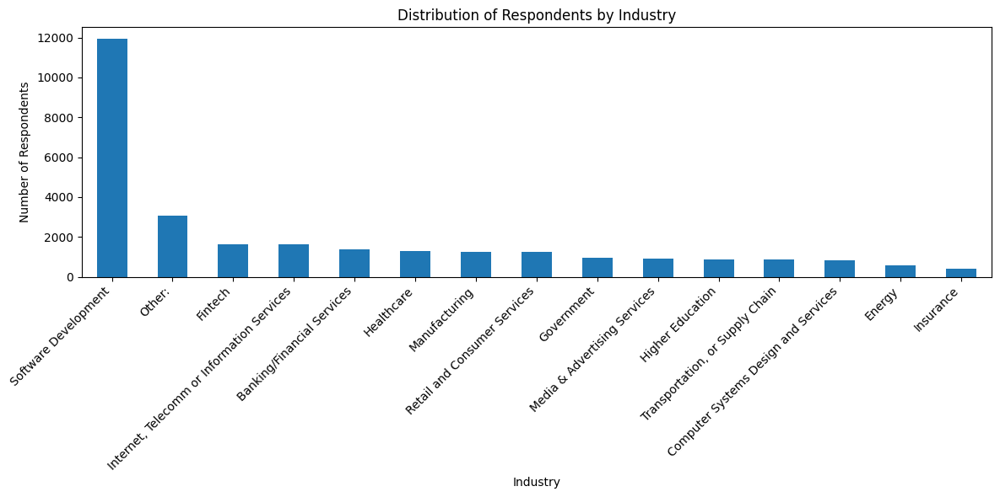

Mean compensation: 86155.28726264134
Median compensation: 65000.0
Standard deviation: 186756.9730862951

High compensation threshold: 646426.2065215267

Number of high compensation outliers: 89

High compensation outliers:


,ConvertedCompYearly
529,650000.0
828,1000000.0
1932,945000.0
2171,750000.0
2187,2000000.0


Q1: 32712.0
Q3: 107971.5
IQR: 75259.5
Lower bound: -80177.25
Upper bound: 220860.75

Number of IQR outliers: 978


,ConvertedCompYearly
428,230000.0
456,300000.0
461,254425.0
529,650000.0
545,400000.0


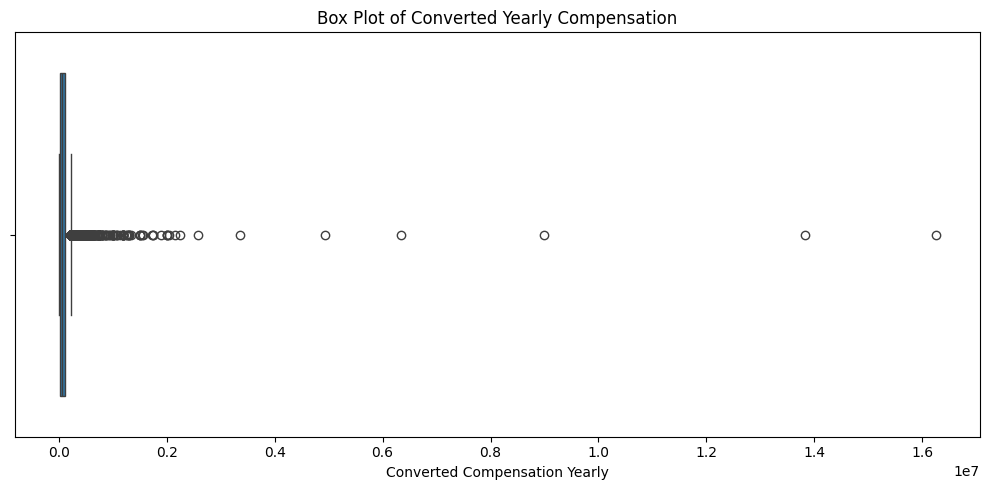

Original DataFrame shape: (65437, 116)
Cleaned DataFrame shape: (22457, 116)
Number of rows removed: 42980
Remaining outliers: 0
Correlation with Age:
Age_numeric            1.000000
WorkExp                0.846986
YearsCodePro           0.809932
ConvertedCompYearly    0.367714
JobSat                 0.062830
CompTotal             -0.021337
JobSatPoints_1        -0.039081
ResponseId            -0.040212
JobSatPoints_6        -0.051419
JobSatPoints_8        -0.051428
JobSatPoints_4        -0.069900
JobSatPoints_7        -0.082752
JobSatPoints_9        -0.083620
JobSatPoints_5        -0.096700
JobSatPoints_11       -0.106422
JobSatPoints_10       -0.111235
JobSat_numeric              NaN
Name: Age_numeric, dtype: float64


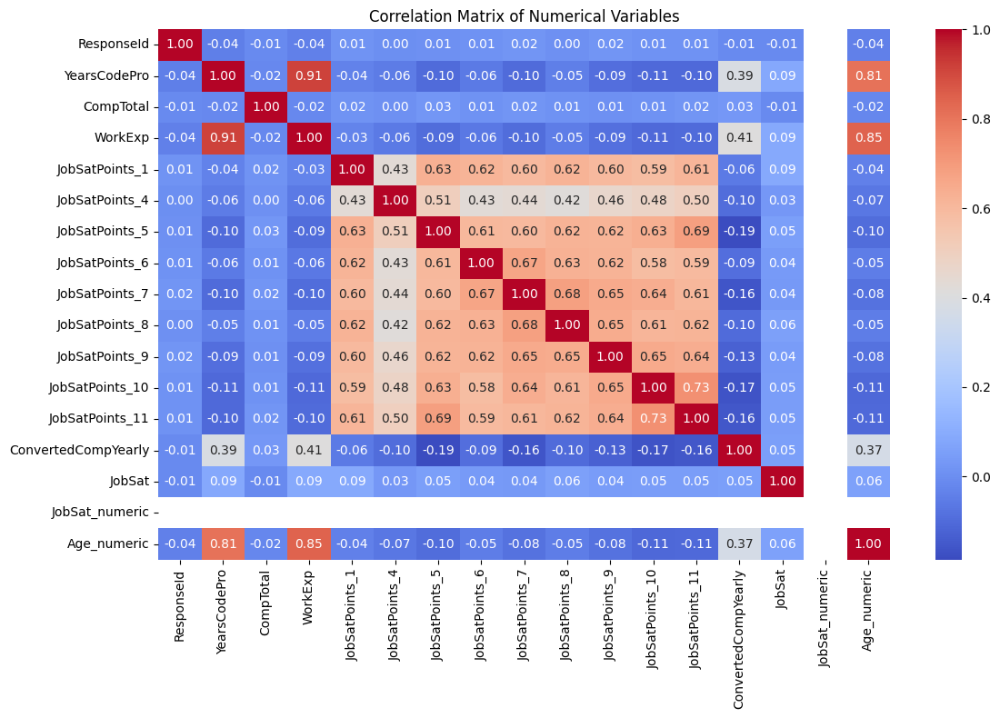

In [ ]:
# ============================================
# Import Libraries
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================
# Step 2: Plot the Distribution of Industry
# ============================================

# Count respondents by Industry
industry_counts = df['Industry'].value_counts()

print("Industry Distribution:")
print(industry_counts)


# Bar chart
plt.figure(figsize=(12, 6))

industry_counts.plot(kind='bar')

plt.title('Distribution of Respondents by Industry')
plt.xlabel('Industry')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# ============================================
# Step 3: Identify High Compensation Outliers
# ============================================

# Convert compensation column to numeric
df['ConvertedCompYearly'] = pd.to_numeric(
    df['ConvertedCompYearly'],
    errors='coerce'
)


# Calculate basic statistics
mean_comp = df['ConvertedCompYearly'].mean()
median_comp = df['ConvertedCompYearly'].median()
std_comp = df['ConvertedCompYearly'].std()

print("Mean compensation:", mean_comp)
print("Median compensation:", median_comp)
print("Standard deviation:", std_comp)


# Calculate threshold: 3 standard deviations above mean
high_comp_threshold = mean_comp + (3 * std_comp)

print("\nHigh compensation threshold:", high_comp_threshold)


# Identify high compensation values
high_comp_outliers = df[
    df['ConvertedCompYearly'] > high_comp_threshold
]

print("\nNumber of high compensation outliers:",
      len(high_comp_outliers))

print("\nHigh compensation outliers:")
display(
    high_comp_outliers[
        ['ConvertedCompYearly']
    ].head()
)


# ============================================
# Step 4: Detect Outliers Using IQR
# ============================================

# Remove missing values temporarily for calculations
compensation = df['ConvertedCompYearly'].dropna()


# Calculate Q1 and Q3
Q1 = compensation.quantile(0.25)
Q3 = compensation.quantile(0.75)


# Calculate IQR
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)


# Calculate lower and upper bounds
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)


# Identify outliers
outliers = df[
    (df['ConvertedCompYearly'] < lower_bound) |
    (df['ConvertedCompYearly'] > upper_bound)
]

print("\nNumber of IQR outliers:", len(outliers))


# Display some outliers
display(
    outliers[
        ['ConvertedCompYearly']
    ].head()
)


# Box plot
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['ConvertedCompYearly']
)

plt.title('Box Plot of Converted Yearly Compensation')
plt.xlabel('Converted Compensation Yearly')
plt.tight_layout()
plt.show()


# ============================================
# Step 5: Remove Outliers and Create New DataFrame
# ============================================

# Keep only values within the IQR bounds
df_cleaned = df[
    (df['ConvertedCompYearly'] >= lower_bound) &
    (df['ConvertedCompYearly'] <= upper_bound)
].copy()


# Check the size of the original and cleaned datasets
print("Original DataFrame shape:", df.shape)
print("Cleaned DataFrame shape:", df_cleaned.shape)

print(
    "Number of rows removed:",
    len(df) - len(df_cleaned)
)


# Verify that compensation outliers are removed
print(
    "Remaining outliers:",
    len(
        df_cleaned[
            (df_cleaned['ConvertedCompYearly'] < lower_bound) |
            (df_cleaned['ConvertedCompYearly'] > upper_bound)
        ]
    )
)


# ============================================
# Step 6: Correlation Analysis
# ============================================

# Map Age to approximate numeric values
age_mapping = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29,
    '35-44 years old': 39,
    '45-54 years old': 49,
    '55-64 years old': 59,
    '65 years or older': 70
}


# Create numeric Age column
df_cleaned['Age_numeric'] = df_cleaned['Age'].map(
    age_mapping
)


# Select numerical columns
numeric_columns = df_cleaned.select_dtypes(
    include='number'
).columns


# Calculate correlations with Age
age_correlations = df_cleaned[
    numeric_columns
].corr()['Age_numeric'].sort_values(
    ascending=False
)

print("Correlation with Age:")
print(age_correlations)


# Create correlation matrix
correlation_matrix = df_cleaned[
    numeric_columns
].corr()


# Visualize correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

count    2.343500e+04
mean     8.615529e+04
std      1.867570e+05
min      1.000000e+00
25%      3.271200e+04
50%      6.500000e+04
75%      1.079715e+05
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64


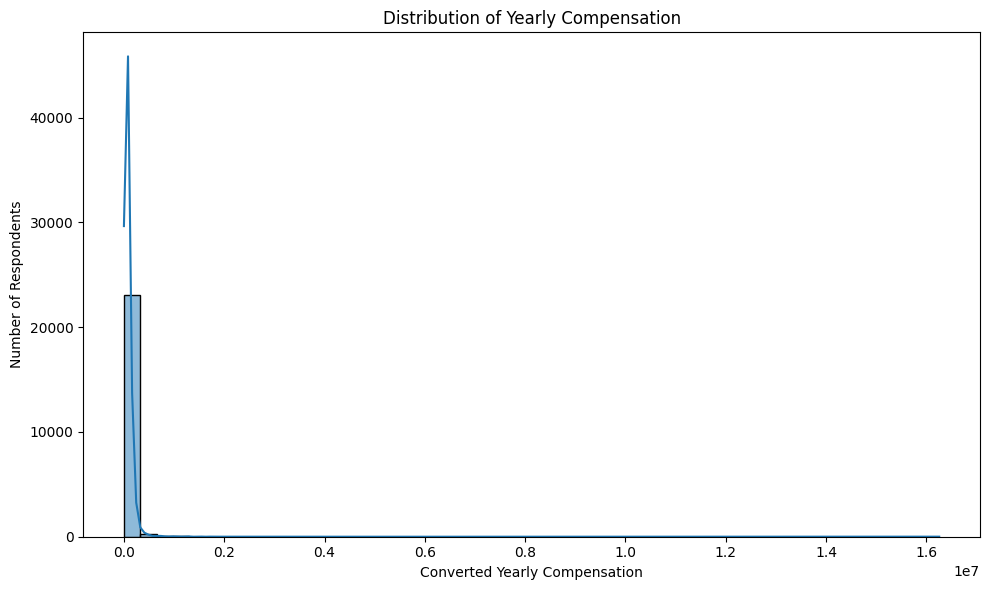

Median compensation for full-time employees: 69814.0


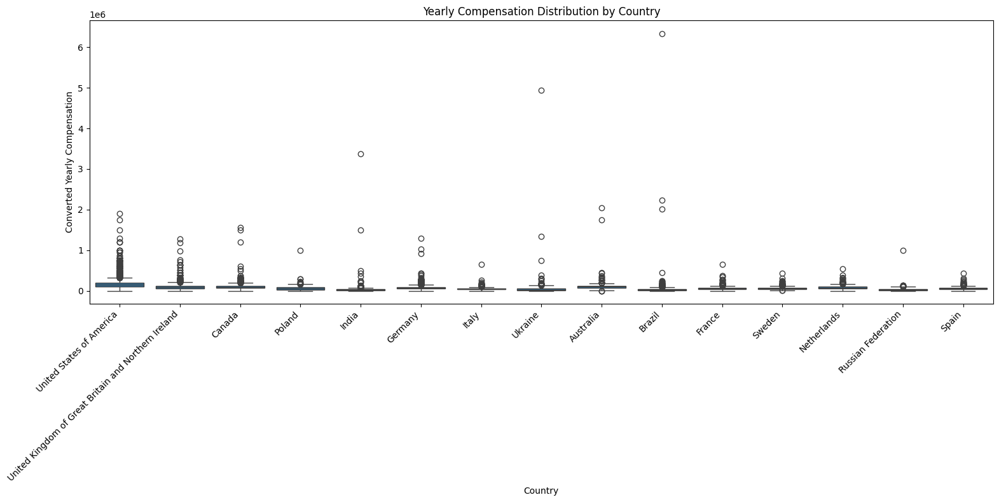

Q1: 32712.0
Q3: 107971.5
IQR: 75259.5
Lower Bound: -80177.25
Upper Bound: 220860.75
Original dataset shape: (65437, 116)
Cleaned dataset shape: (22457, 116)
Rows removed: 42980
Correlation Matrix:


,ConvertedCompYearly,WorkExp,JobSatPoints_1
ConvertedCompYearly,1.000000,0.408438,-0.058170
WorkExp,0.408438,1.000000,-0.032388
JobSatPoints_1,-0.058170,-0.032388,1.000000


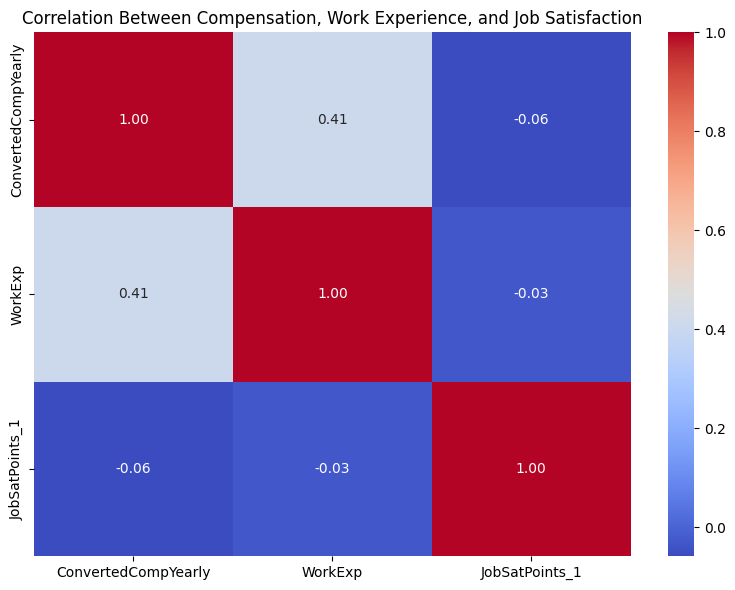

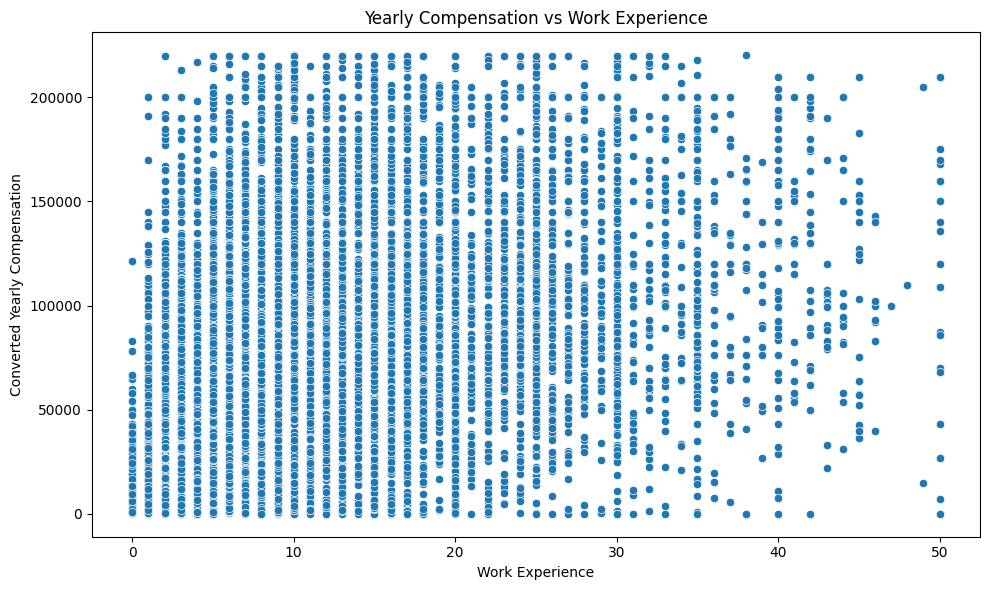

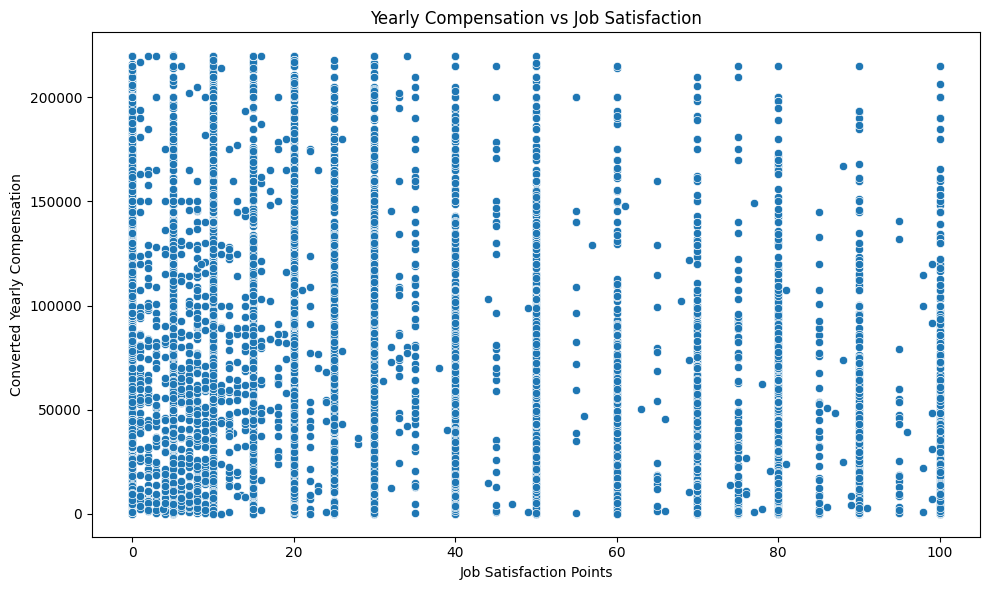

In [ ]:
# ============================================
# Step 3: Analyze and Visualize Compensation Distribution
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make sure ConvertedCompYearly is numeric
df['ConvertedCompYearly'] = pd.to_numeric(
    df['ConvertedCompYearly'], errors='coerce'
)

# Display summary statistics
print(df['ConvertedCompYearly'].describe())

# Histogram
plt.figure(figsize=(10, 6))
sns.histplot(
    df['ConvertedCompYearly'].dropna(),
    bins=50,
    kde=True
)
plt.title('Distribution of Yearly Compensation')
plt.xlabel('Converted Yearly Compensation')
plt.ylabel('Number of Respondents')
plt.tight_layout()
plt.show()


# ============================================
# Step 4: Calculate Median Compensation
# for Full-Time Employees
# ============================================

full_time = df[
    df['Employment'] == 'Employed, full-time'
]

median_full_time_compensation = full_time[
    'ConvertedCompYearly'
].median()

print("Median compensation for full-time employees:",
      median_full_time_compensation)


# ============================================
# Step 5: Compensation Distribution by Country
# ============================================

# Select the top 15 countries by number of respondents
top_countries = df['Country'].value_counts().head(15).index

country_data = df[
    df['Country'].isin(top_countries)
].copy()

# Box plot
plt.figure(figsize=(16, 8))

sns.boxplot(
    data=country_data,
    x='Country',
    y='ConvertedCompYearly'
)

plt.title('Yearly Compensation Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Converted Yearly Compensation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# ============================================
# Step 6: Remove Outliers
# ============================================

# Calculate Q1, Q3 and IQR
Q1 = df['ConvertedCompYearly'].quantile(0.25)
Q3 = df['ConvertedCompYearly'].quantile(0.75)

IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Create refined DataFrame without outliers
df_cleaned = df[
    (df['ConvertedCompYearly'] >= lower_bound) &
    (df['ConvertedCompYearly'] <= upper_bound)
].copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_cleaned.shape)
print("Rows removed:", len(df) - len(df_cleaned))


# ============================================
# Step 7: Correlations Between Key Variables
# ============================================

# Convert columns to numeric
df_cleaned['WorkExp'] = pd.to_numeric(
    df_cleaned['WorkExp'], errors='coerce'
)

df_cleaned['JobSatPoints_1'] = pd.to_numeric(
    df_cleaned['JobSatPoints_1'], errors='coerce'
)

# Select the required columns
correlation_data = df_cleaned[
    ['ConvertedCompYearly', 'WorkExp', 'JobSatPoints_1']
]

# Calculate correlations
correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Compensation, Work Experience, and Job Satisfaction')
plt.tight_layout()
plt.show()


# ============================================
# Step 8: Scatter Plots for Correlations
# ============================================

# Scatter plot: Compensation vs Work Experience
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cleaned,
    x='WorkExp',
    y='ConvertedCompYearly'
)

plt.title('Yearly Compensation vs Work Experience')
plt.xlabel('Work Experience')
plt.ylabel('Converted Yearly Compensation')
plt.tight_layout()
plt.show()


# Scatter plot: Compensation vs Job Satisfaction
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cleaned,
    x='JobSatPoints_1',
    y='ConvertedCompYearly'
)

plt.title('Yearly Compensation vs Job Satisfaction')
plt.xlabel('Job Satisfaction Points')
plt.ylabel('Converted Yearly Compensation')
plt.tight_layout()
plt.show()

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time       None  Apples   
4   Student, full-time       None  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                               None   
4                                 

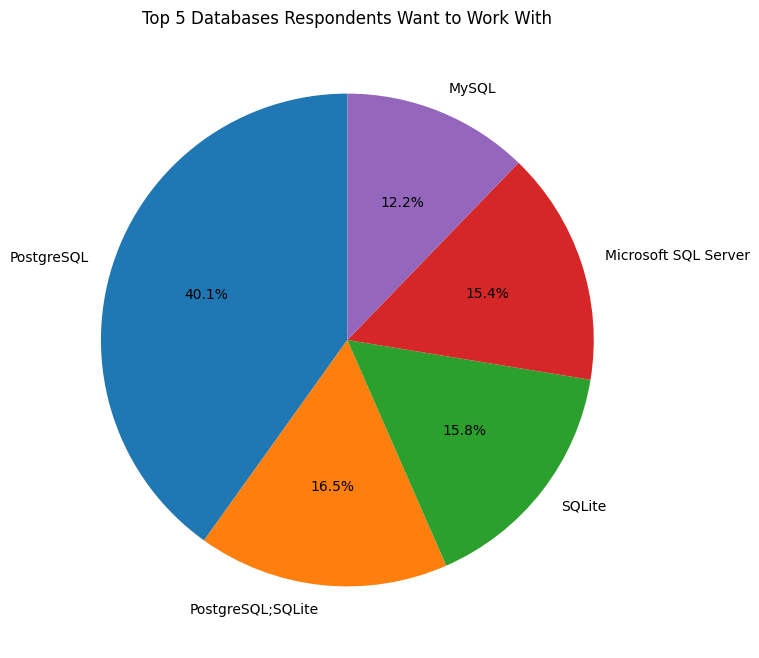

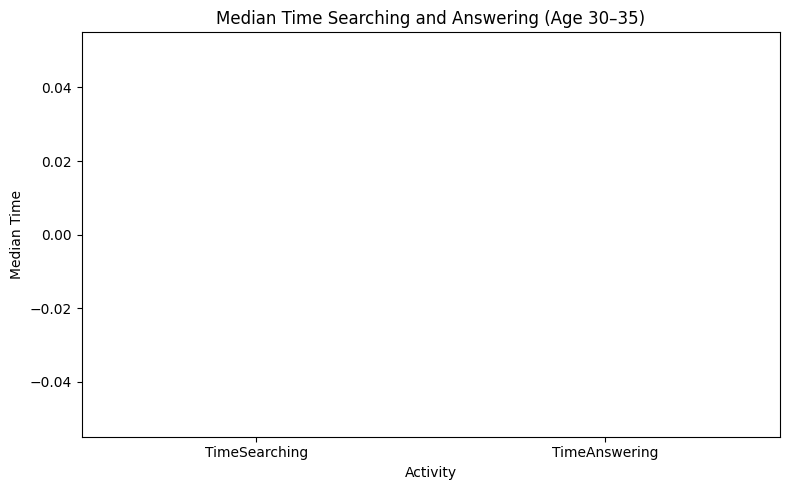

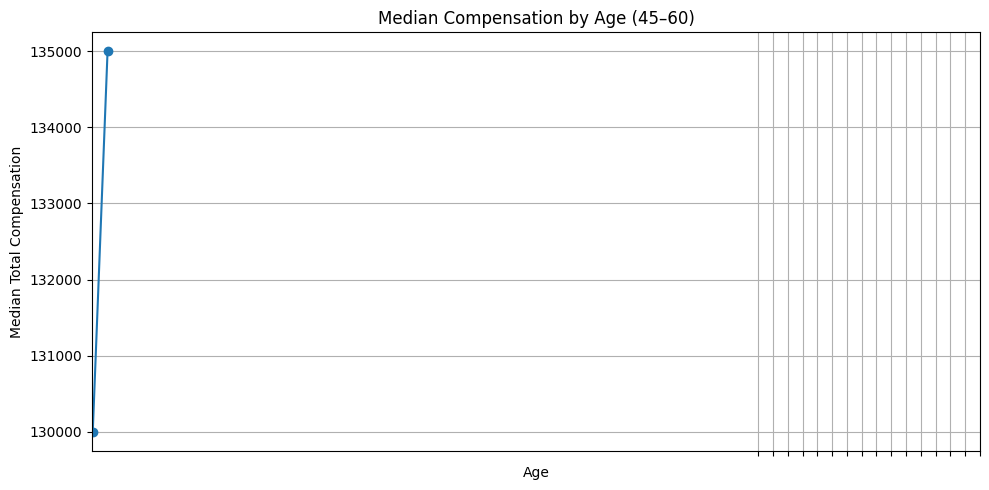

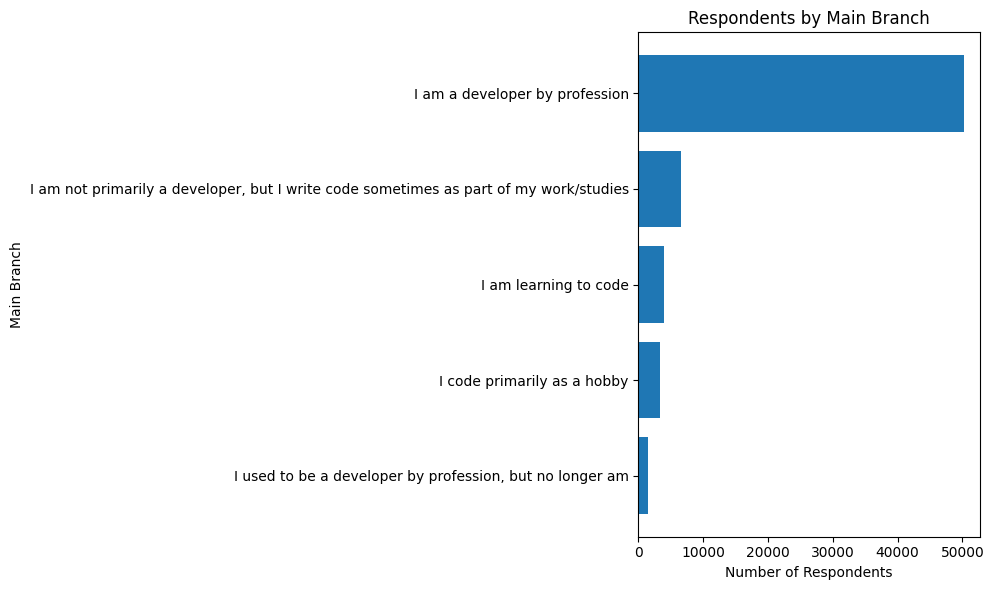

In [ ]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Load the CSV file from the correct remote URL
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Create SQLite database and insert data
conn = sqlite3.connect("survey-data.sqlite")
df.to_sql("main", conn, if_exists="replace", index=False)

# Verify the data
print(pd.read_sql_query("SELECT * FROM main LIMIT 5", conn))


# 1. Pie Chart: Top 5 Databases Respondents Want to Work With
query = """
SELECT DatabaseWantToWorkWith, COUNT(*) AS total
FROM main
WHERE DatabaseWantToWorkWith IS NOT NULL
GROUP BY DatabaseWantToWorkWith
ORDER BY total DESC
LIMIT 5
"""

df_db = pd.read_sql_query(query, conn)

plt.figure(figsize=(8, 8))
plt.pie(
    df_db["total"],
    labels=df_db["DatabaseWantToWorkWith"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Top 5 Databases Respondents Want to Work With")
plt.show()


# 2. Stacked Bar Chart: Median TimeSearching and TimeAnswering
# for respondents aged 30 to 35
query = """
SELECT Age, TimeSearching, TimeAnswering
FROM main
WHERE Age BETWEEN 30 AND 35
"""

df_time = pd.read_sql_query(query, conn)

median_time = df_time[["TimeSearching", "TimeAnswering"]].median()

median_time.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Median Time Searching and Answering (Age 30–35)")
plt.ylabel("Median Time")
plt.xlabel("Activity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 3. Line Chart: Median CompTotal for Ages 45 to 60
query = """
SELECT Age, CompTotal
FROM main
WHERE Age BETWEEN 45 AND 60
AND CompTotal IS NOT NULL
"""

df_comp = pd.read_sql_query(query, conn)

median_comp = df_comp.groupby("Age")["CompTotal"].median()

plt.figure(figsize=(10, 5))
plt.plot(median_comp.index, median_comp.values, marker="o")
plt.title("Median Compensation by Age (45–60)")
plt.xlabel("Age")
plt.ylabel("Median Total Compensation")
plt.xticks(range(45, 61))
plt.grid(True)
plt.tight_layout()
plt.show()


# 4. Horizontal Bar Chart: MainBranch
query = """
SELECT MainBranch, COUNT(*) AS total
FROM main
WHERE MainBranch IS NOT NULL
GROUP BY MainBranch
ORDER BY total DESC
"""

df_branch = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
plt.barh(df_branch["MainBranch"], df_branch["total"])
plt.title("Respondents by Main Branch")
plt.xlabel("Number of Respondents")
plt.ylabel("Main Branch")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# Close the database connection
conn.close()

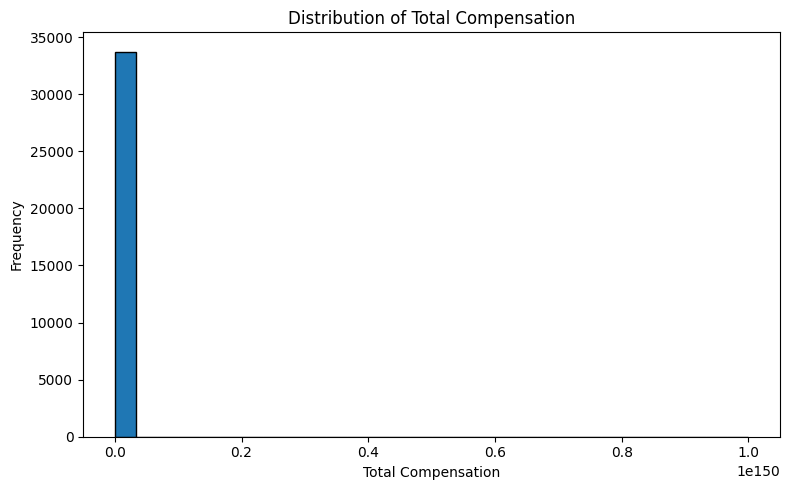

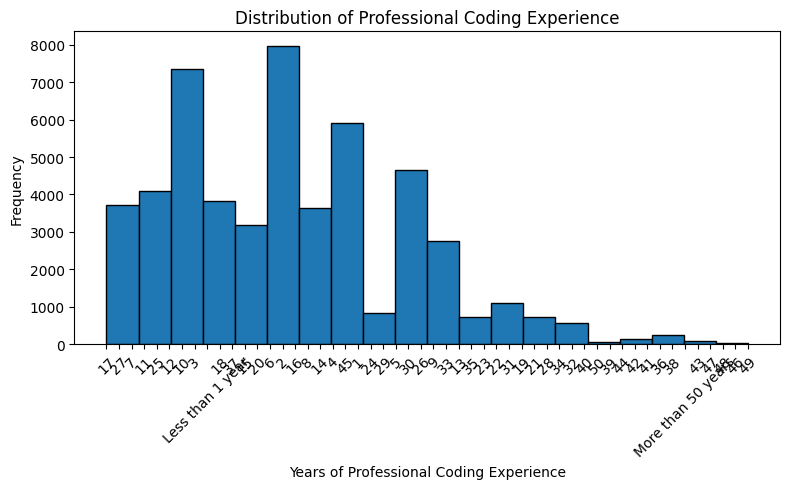

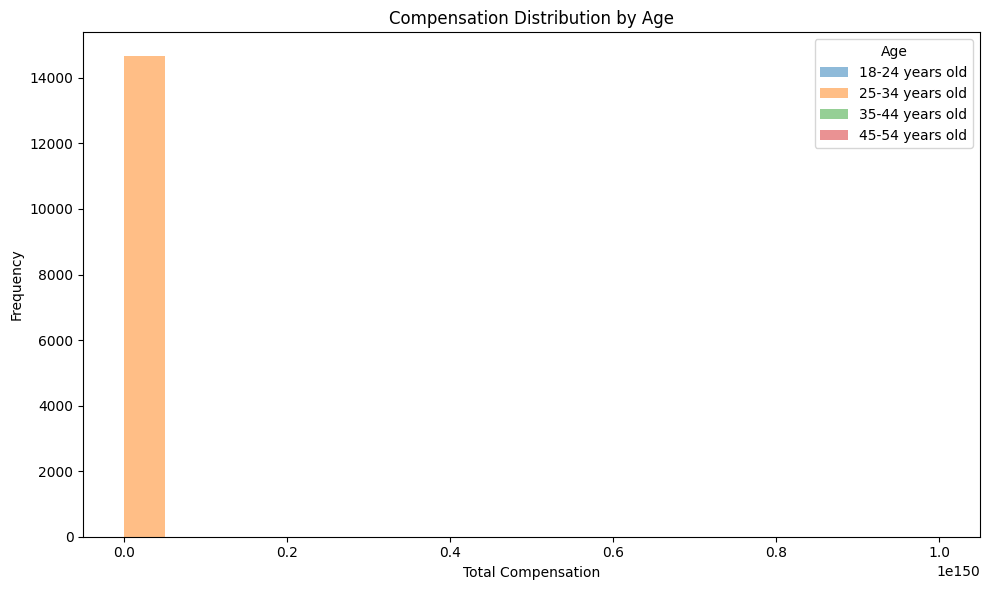

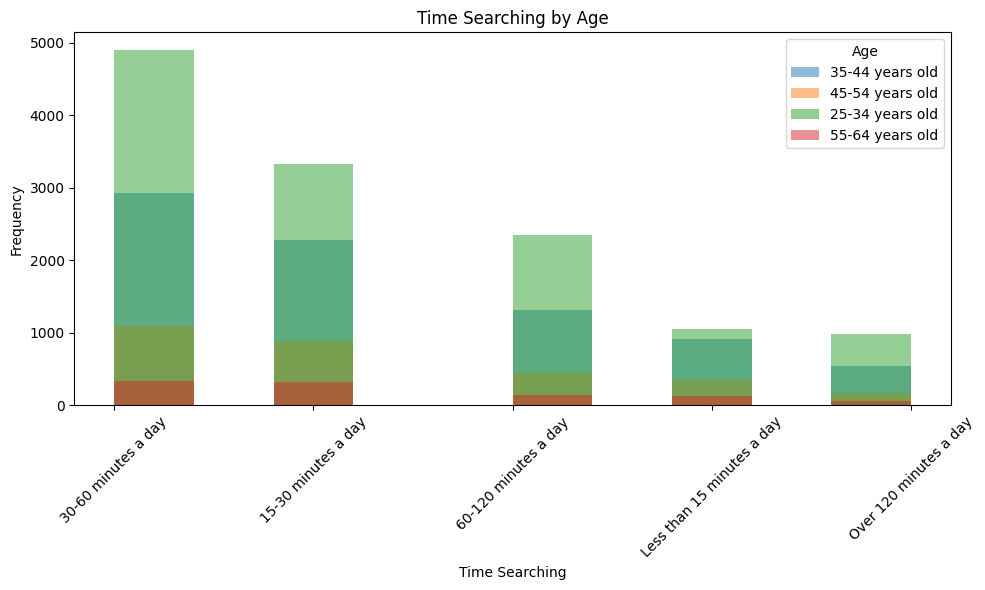

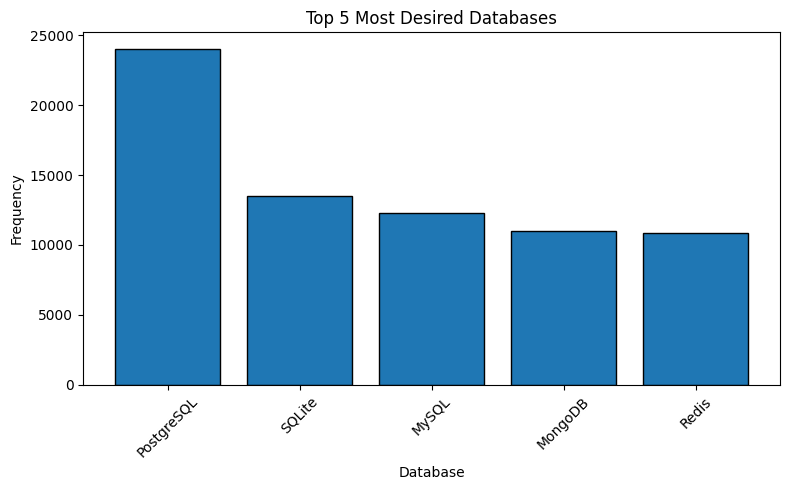

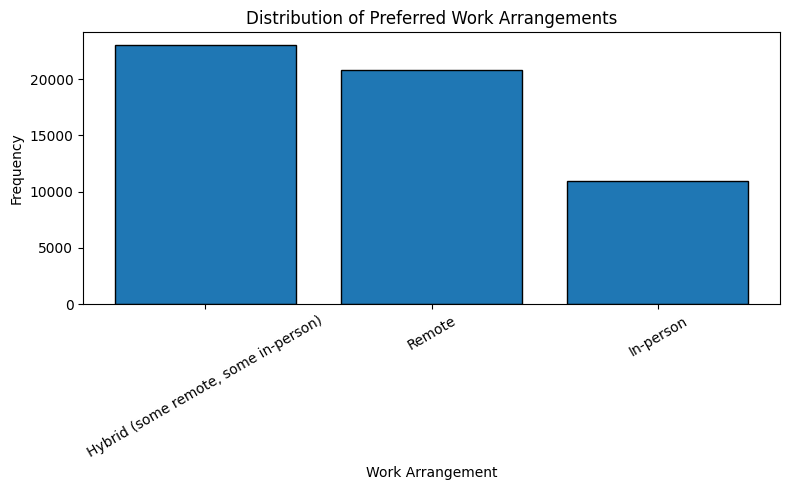

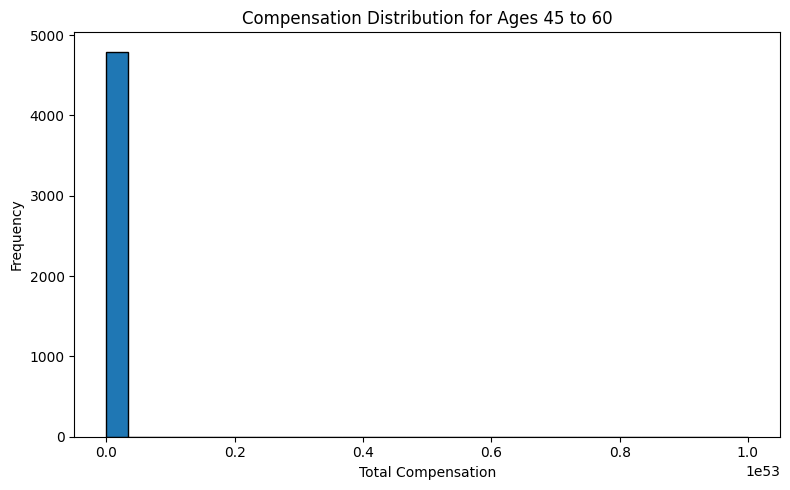

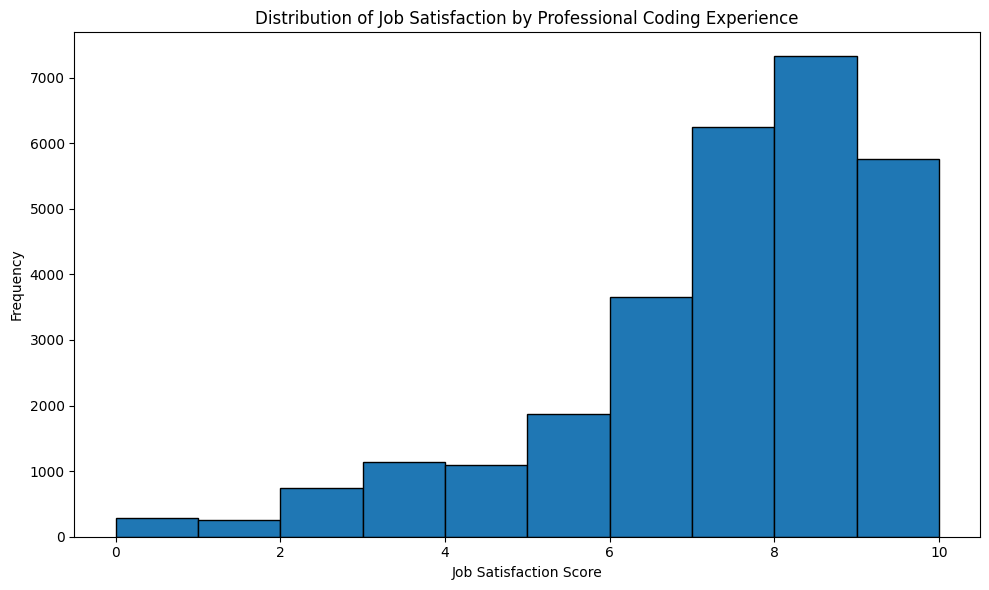

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Connect to the SQLite database
conn = sqlite3.connect("survey-data.sqlite")


# 1.1 Histogram of CompTotal (Total Compensation)
query = """
SELECT CompTotal
FROM main
WHERE CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

plt.figure(figsize=(8, 5))
plt.hist(df["CompTotal"], bins=30, edgecolor="black")
plt.title("Distribution of Total Compensation")
plt.xlabel("Total Compensation")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 1.2 Histogram of YearsCodePro
query = """
SELECT YearsCodePro
FROM main
WHERE YearsCodePro IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

plt.figure(figsize=(8, 5))
plt.hist(df["YearsCodePro"].dropna().astype(str), bins=20,
         edgecolor="black")
plt.title("Distribution of Professional Coding Experience")
plt.xlabel("Years of Professional Coding Experience")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2.1 Histogram Comparison of CompTotal by Age Group
query = """
SELECT Age, CompTotal
FROM main
WHERE Age IS NOT NULL AND CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

age_groups = df["Age"].unique()[:4]

plt.figure(figsize=(10, 6))
for age in age_groups:
    compensation = df.loc[df["Age"] == age, "CompTotal"]
    plt.hist(compensation, bins=20, alpha=0.5, label=str(age))

plt.title("Compensation Distribution by Age")
plt.xlabel("Total Compensation")
plt.ylabel("Frequency")
plt.legend(title="Age")
plt.tight_layout()
plt.show()


# 2.2 Histogram of TimeSearching for Different Age Groups
query = """
SELECT Age, TimeSearching
FROM main
WHERE Age IS NOT NULL AND TimeSearching IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

age_groups = df["Age"].unique()[:4]

plt.figure(figsize=(10, 6))
for age in age_groups:
    searching_time = df.loc[df["Age"] == age, "TimeSearching"]
    plt.hist(searching_time.astype(str), bins=10, alpha=0.5,
             label=str(age))

plt.title("Time Searching by Age")
plt.xlabel("Time Searching")
plt.ylabel("Frequency")
plt.legend(title="Age")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3.1 Histogram of Top 5 Desired Databases
query = """
SELECT DatabaseWantToWorkWith
FROM main
WHERE DatabaseWantToWorkWith IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

database_counts = (
    df["DatabaseWantToWorkWith"]
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(5)
)

plt.figure(figsize=(8, 5))
plt.bar(database_counts.index, database_counts.values,
        edgecolor="black")
plt.title("Top 5 Most Desired Databases")
plt.xlabel("Database")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3.2 Histogram of Preferred Work Locations (RemoteWork)
query = """
SELECT RemoteWork
FROM main
WHERE RemoteWork IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

remote_counts = df["RemoteWork"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(remote_counts.index, remote_counts.values,
        edgecolor="black")
plt.title("Distribution of Preferred Work Arrangements")
plt.xlabel("Work Arrangement")
plt.ylabel("Frequency")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 4.1 Histogram of CompTotal for Ages 45 to 60
query = """
SELECT CompTotal
FROM main
WHERE Age BETWEEN 45 AND 60
AND CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

plt.figure(figsize=(8, 5))
plt.hist(df["CompTotal"], bins=30, edgecolor="black")
plt.title("Compensation Distribution for Ages 45 to 60")
plt.xlabel("Total Compensation")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 4.2 Histogram of JobSat by YearsCodePro
query = """
SELECT YearsCodePro, JobSat
FROM main
WHERE YearsCodePro IS NOT NULL AND JobSat IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
plt.hist(df["JobSat"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of Job Satisfaction by Professional Coding Experience")
plt.xlabel("Job Satisfaction Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Final Step: Close the database connection
conn.close()


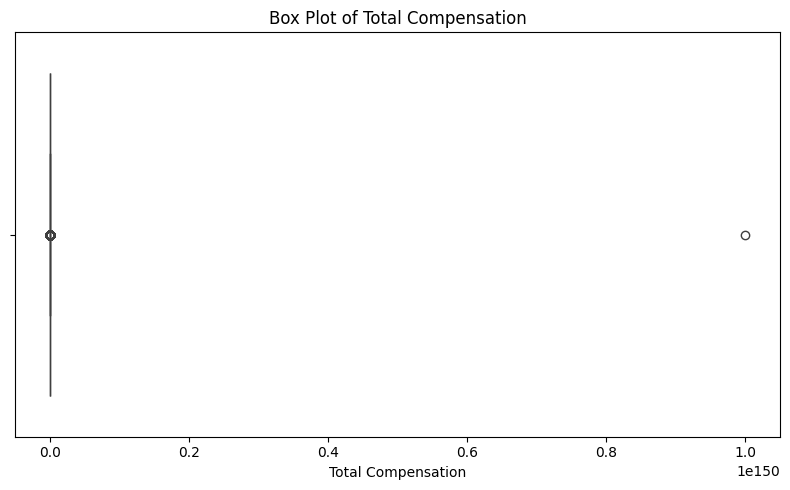

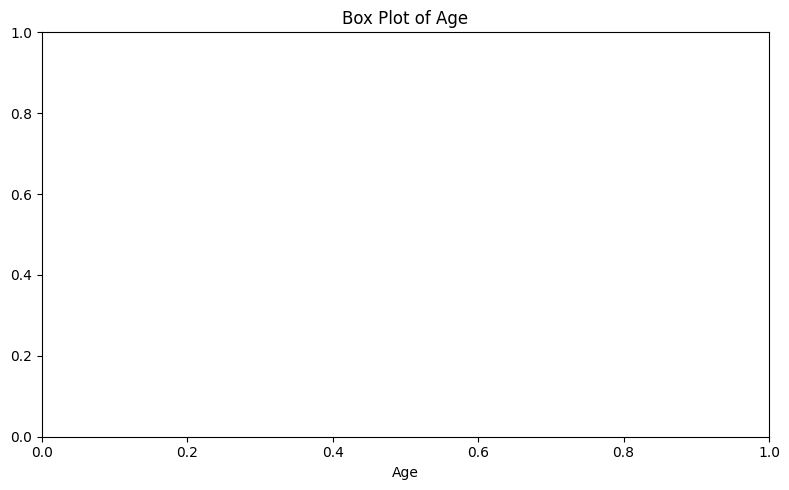

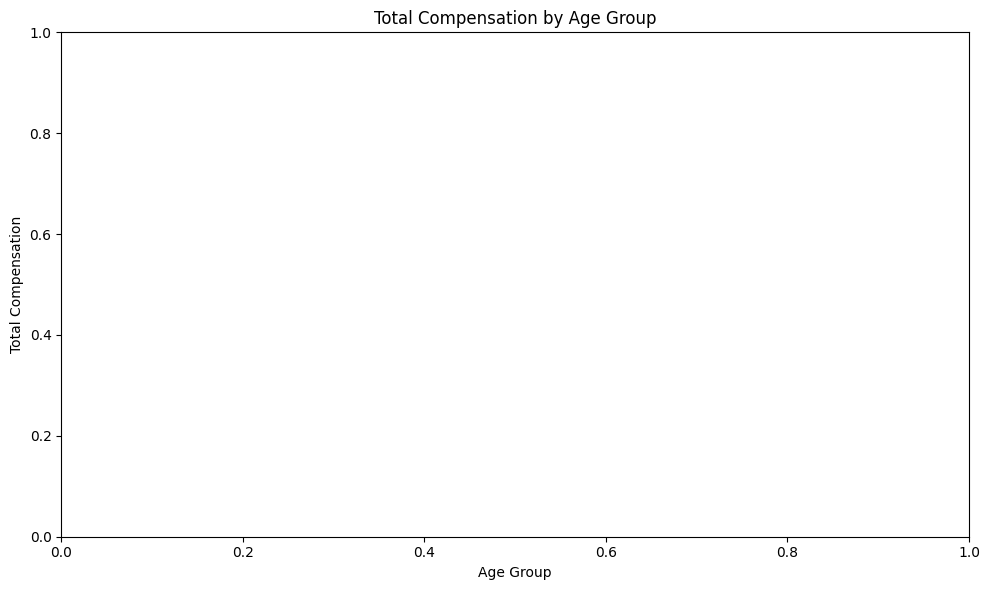

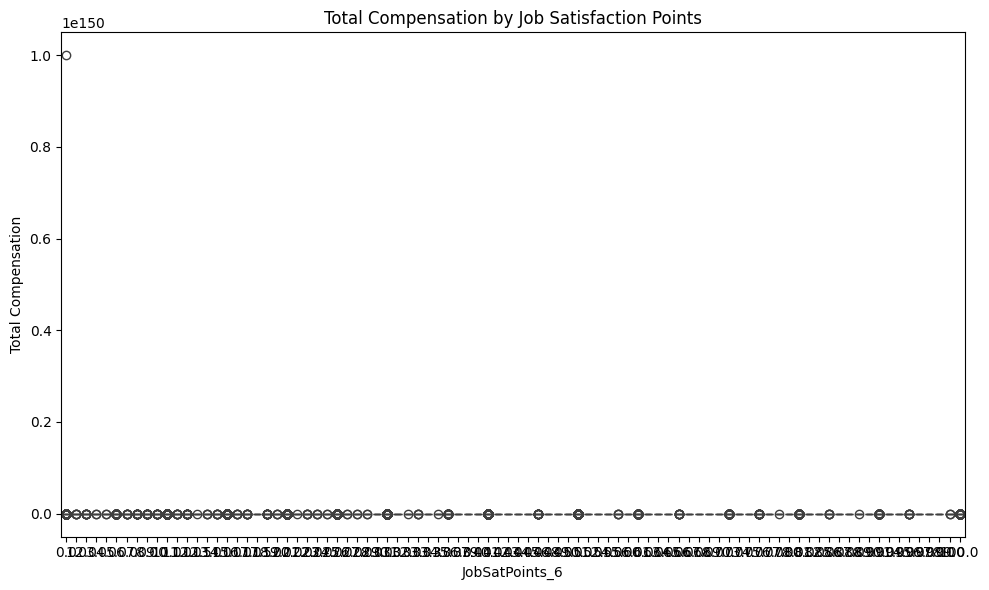

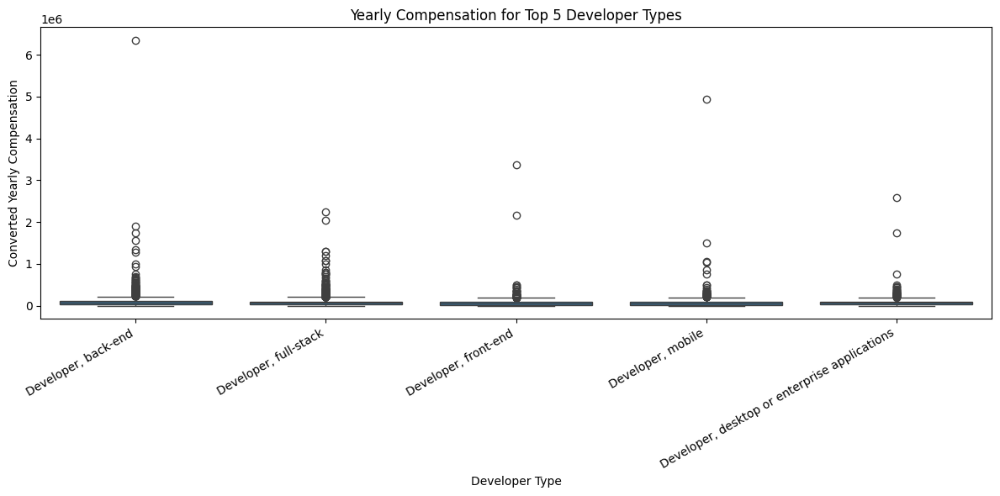

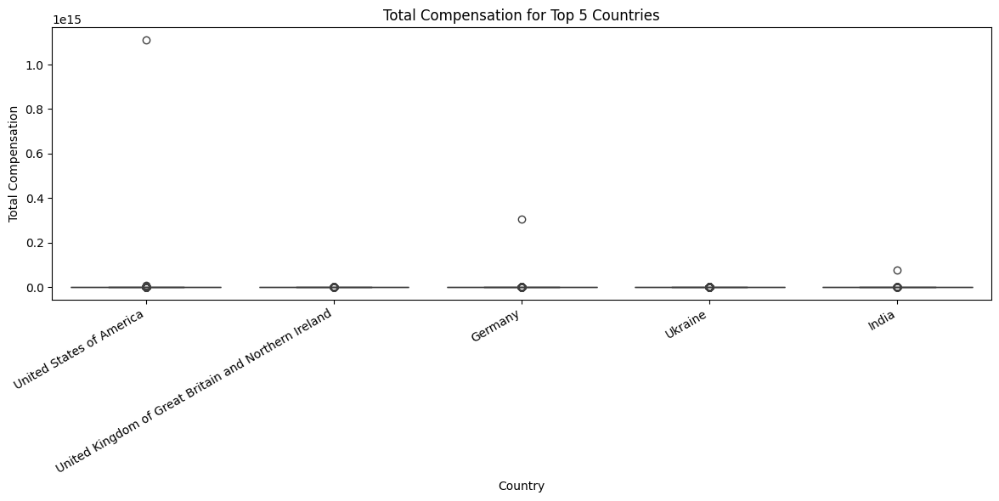

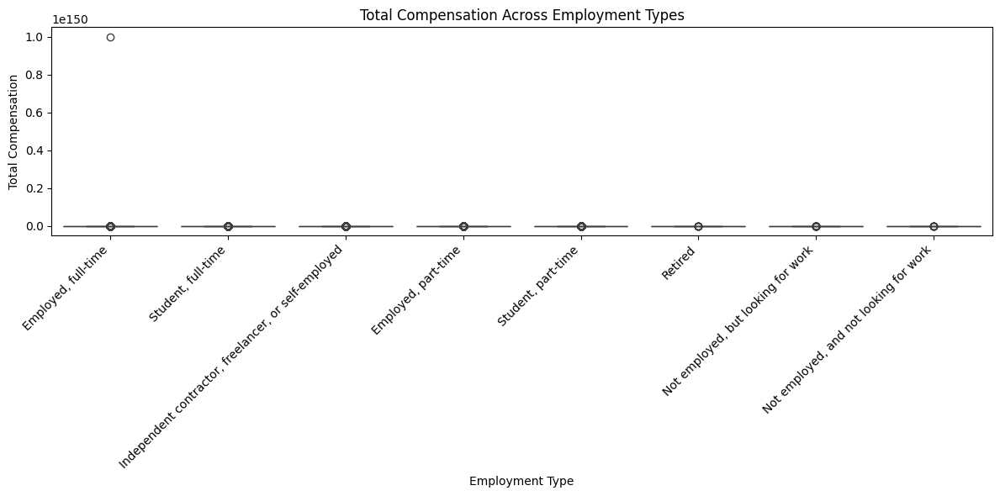

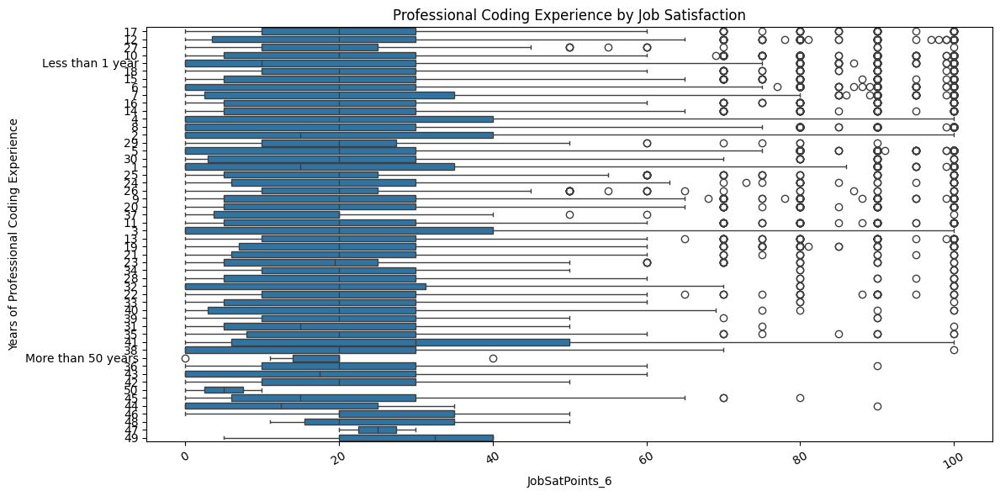

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the SQLite database
conn = sqlite3.connect("survey-data.sqlite")


# Task 1.1: Box Plot of CompTotal
query = """
SELECT CompTotal
FROM main
WHERE CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["CompTotal"] = pd.to_numeric(df["CompTotal"], errors="coerce")
df = df.dropna(subset=["CompTotal"])

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["CompTotal"])
plt.title("Box Plot of Total Compensation")
plt.xlabel("Total Compensation")
plt.tight_layout()
plt.show()


# Task 1.2: Box Plot of Age (converted to numeric values)
query = """
SELECT Age
FROM main
WHERE Age IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df.dropna(subset=["Age"])

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Age"])
plt.title("Box Plot of Age")
plt.xlabel("Age")
plt.tight_layout()
plt.show()


# Task 2.1: Box Plot of CompTotal Grouped by Age Groups
query = """
SELECT Age, CompTotal
FROM main
WHERE Age IS NOT NULL AND CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["CompTotal"] = pd.to_numeric(df["CompTotal"], errors="coerce")
df = df.dropna(subset=["Age", "CompTotal"])

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 24, 34, 44, 54, 64, 100],
    labels=["Under 25", "25-34", "35-44", "45-54", "55-64", "65+"]
)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="AgeGroup", y="CompTotal")
plt.title("Total Compensation by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Compensation")
plt.tight_layout()
plt.show()


# Task 2.2: Box Plot of CompTotal Grouped by Job Satisfaction
# (JobSatPoints_6)
query = """
SELECT JobSatPoints_6, CompTotal
FROM main
WHERE JobSatPoints_6 IS NOT NULL AND CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df["CompTotal"] = pd.to_numeric(df["CompTotal"], errors="coerce")
df = df.dropna(subset=["JobSatPoints_6", "CompTotal"])

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="JobSatPoints_6", y="CompTotal")
plt.title("Total Compensation by Job Satisfaction Points")
plt.xlabel("JobSatPoints_6")
plt.ylabel("Total Compensation")
plt.tight_layout()
plt.show()


# Task 3.1: Box Plot of ConvertedCompYearly for Top 5 Developer Types
query = """
SELECT DevType, ConvertedCompYearly
FROM main
WHERE DevType IS NOT NULL AND ConvertedCompYearly IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"], errors="coerce"
)
df = df.dropna(subset=["ConvertedCompYearly"])

dev_counts = (
    df["DevType"].str.split(";")
    .explode()
    .str.strip()
    .value_counts()
)
top5_dev = dev_counts.head(5).index

df_dev = df.assign(
    DevType=df["DevType"].str.split(";")
).explode("DevType")
df_dev["DevType"] = df_dev["DevType"].str.strip()
df_dev = df_dev[df_dev["DevType"].isin(top5_dev)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_dev, x="DevType", y="ConvertedCompYearly")
plt.title("Yearly Compensation for Top 5 Developer Types")
plt.xlabel("Developer Type")
plt.ylabel("Converted Yearly Compensation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Task 3.2: Box Plot of CompTotal for Top 5 Countries
query = """
SELECT Country, CompTotal
FROM main
WHERE Country IS NOT NULL AND CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["CompTotal"] = pd.to_numeric(df["CompTotal"], errors="coerce")
df = df.dropna(subset=["CompTotal"])

top5_countries = df["Country"].value_counts().head(5).index
df_country = df[df["Country"].isin(top5_countries)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_country, x="Country", y="CompTotal")
plt.title("Total Compensation for Top 5 Countries")
plt.xlabel("Country")
plt.ylabel("Total Compensation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Task 4.1: Box Plot of CompTotal Across Employment Types
query = """
SELECT Employment, CompTotal
FROM main
WHERE Employment IS NOT NULL AND CompTotal IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["CompTotal"] = pd.to_numeric(df["CompTotal"], errors="coerce")
df = df.dropna(subset=["CompTotal"])

employment_counts = (
    df["Employment"].str.split(";")
    .explode()
    .str.strip()
    .value_counts()
)
top_employment = employment_counts.head(10).index

df_emp = df.assign(
    Employment=df["Employment"].str.split(";")
).explode("Employment")
df_emp["Employment"] = df_emp["Employment"].str.strip()
df_emp = df_emp[df_emp["Employment"].isin(top_employment)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_emp, x="Employment", y="CompTotal")
plt.title("Total Compensation Across Employment Types")
plt.xlabel("Employment Type")
plt.ylabel("Total Compensation")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Task 4.2: Box Plot of YearsCodePro by Job Satisfaction
# (JobSatPoints_6)
query = """
SELECT YearsCodePro, JobSatPoints_6
FROM main
WHERE YearsCodePro IS NOT NULL AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df = df.dropna(subset=["YearsCodePro", "JobSatPoints_6"])

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="JobSatPoints_6", y="YearsCodePro")
plt.title("Professional Coding Experience by Job Satisfaction")
plt.xlabel("JobSatPoints_6")
plt.ylabel("Years of Professional Coding Experience")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Final Step: Close the database connection
conn.close()


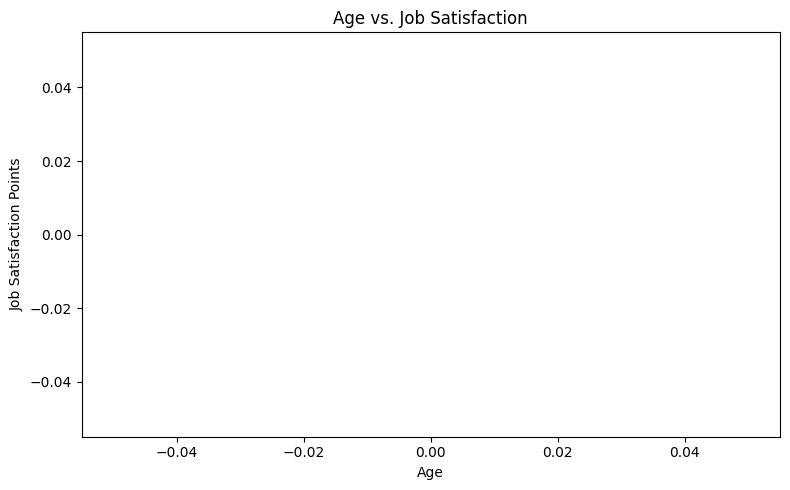

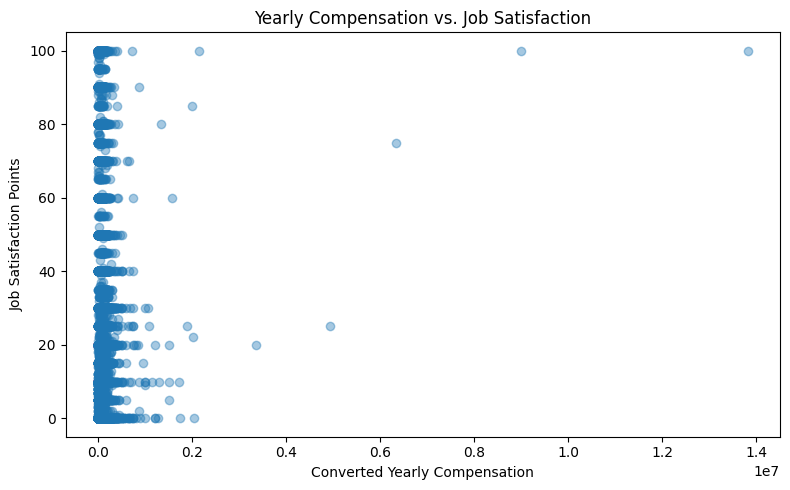

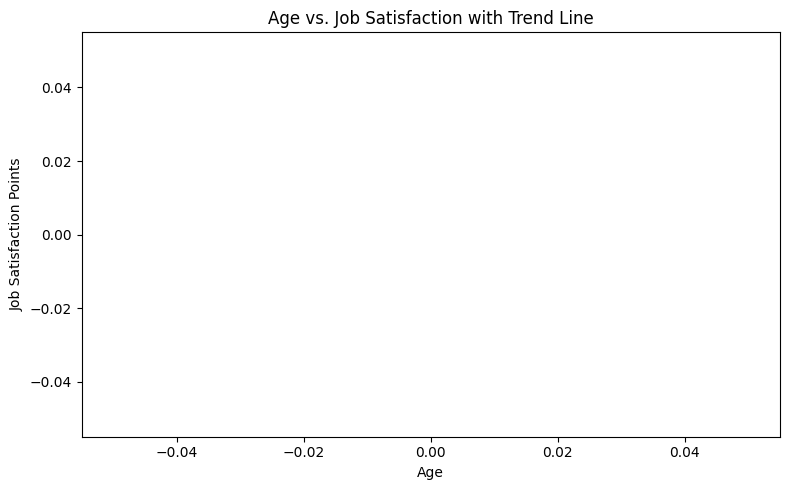

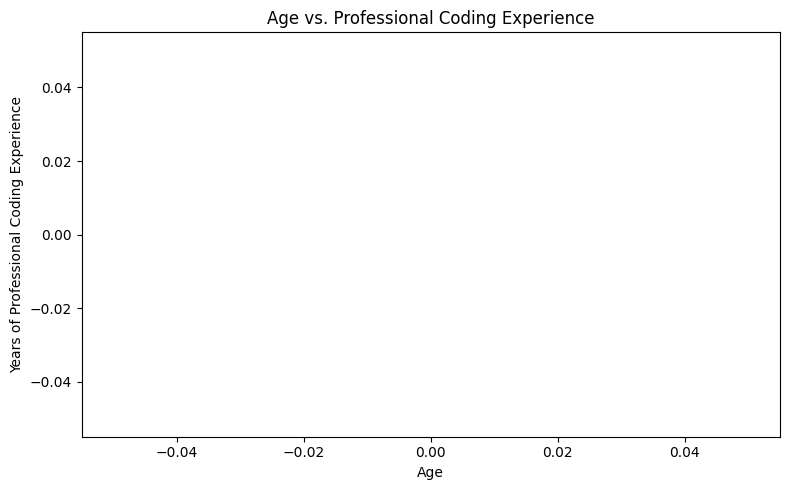

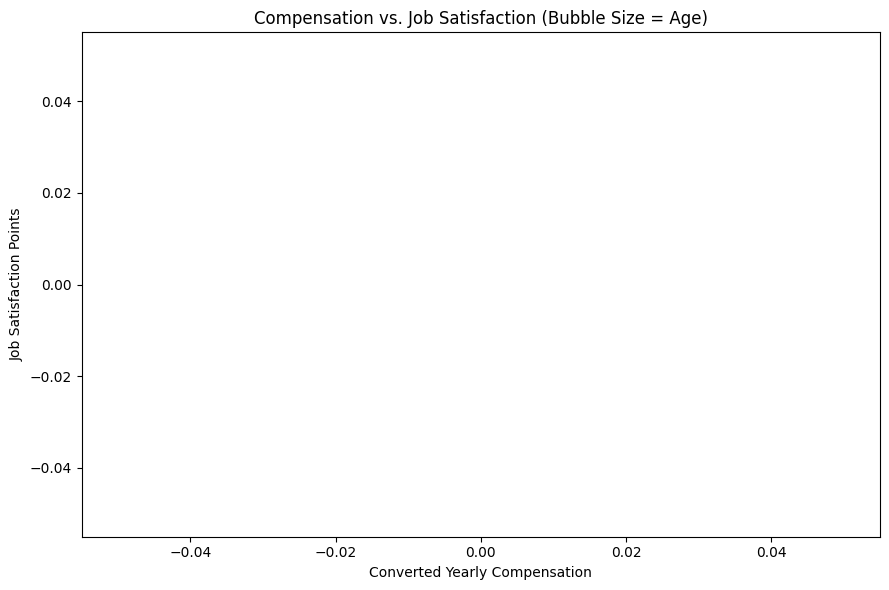

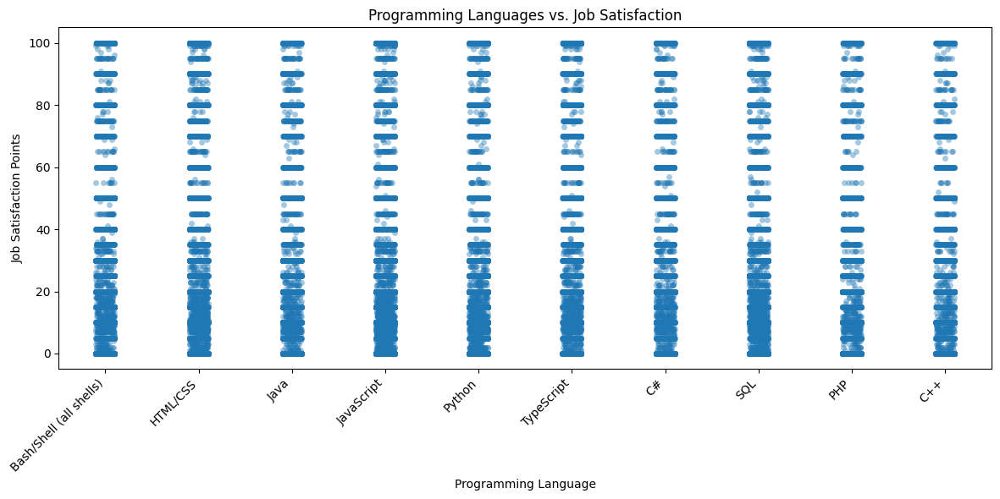

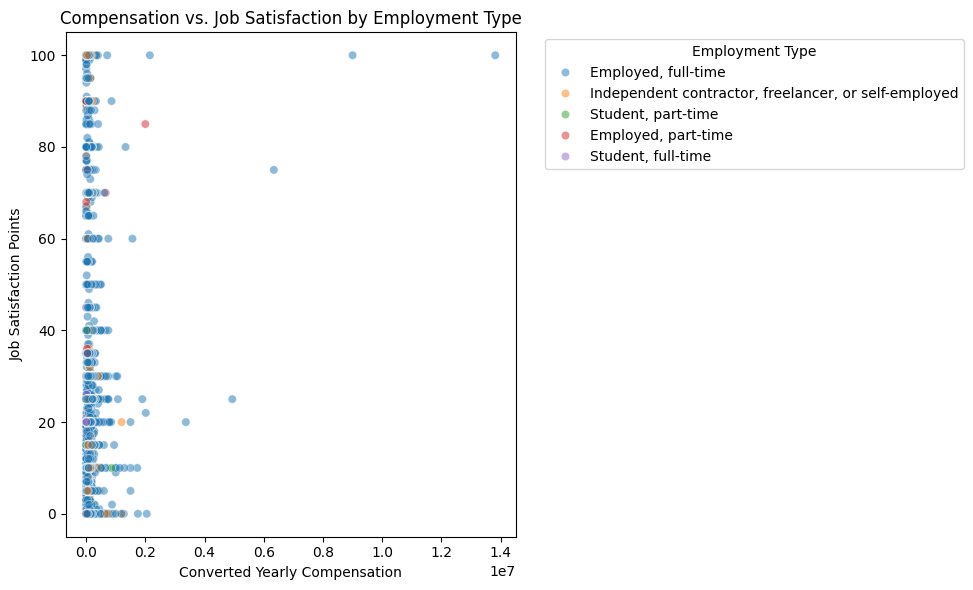

/tmp/ipykernel_4982/241203223.py:277: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")


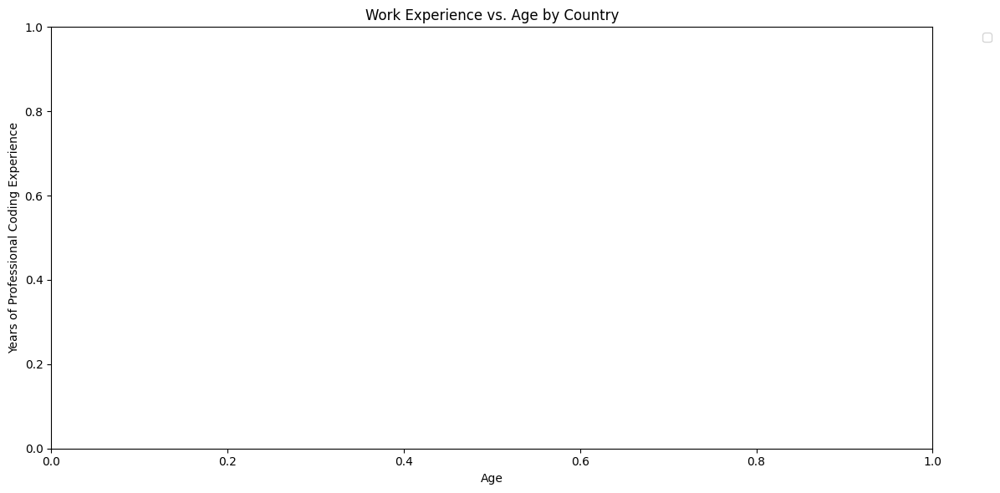

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the SQLite database
conn = sqlite3.connect("survey-data.sqlite")


# Task 1.1: Scatter Plot for Age vs. Job Satisfaction
query = """
SELECT Age, JobSatPoints_6
FROM main
WHERE Age IS NOT NULL AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df = df.dropna(subset=["Age", "JobSatPoints_6"])

plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["JobSatPoints_6"], alpha=0.4)
plt.title("Age vs. Job Satisfaction")
plt.xlabel("Age")
plt.ylabel("Job Satisfaction Points")
plt.tight_layout()
plt.show()


# Task 1.2: Scatter Plot for Compensation vs. Job Satisfaction
query = """
SELECT ConvertedCompYearly, JobSatPoints_6
FROM main
WHERE ConvertedCompYearly IS NOT NULL
AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"], errors="coerce"
)
df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df = df.dropna(subset=["ConvertedCompYearly", "JobSatPoints_6"])

plt.figure(figsize=(8, 5))
plt.scatter(
    df["ConvertedCompYearly"], df["JobSatPoints_6"], alpha=0.4
)
plt.title("Yearly Compensation vs. Job Satisfaction")
plt.xlabel("Converted Yearly Compensation")
plt.ylabel("Job Satisfaction Points")
plt.tight_layout()
plt.show()


# Task 2.1: Scatter Plot with Trend Line for Age vs. Job Satisfaction
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df if False else pd.read_sql_query(
        """SELECT Age, JobSatPoints_6 FROM main
           WHERE Age IS NOT NULL AND JobSatPoints_6 IS NOT NULL""",
        conn
    ).assign(
        Age=lambda x: pd.to_numeric(x["Age"], errors="coerce"),
        JobSatPoints_6=lambda x: pd.to_numeric(
            x["JobSatPoints_6"], errors="coerce"
        )
    ).dropna(),
    x="Age",
    y="JobSatPoints_6",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)
plt.title("Age vs. Job Satisfaction with Trend Line")
plt.xlabel("Age")
plt.ylabel("Job Satisfaction Points")
plt.tight_layout()
plt.show()


# Task 2.2: Scatter Plot for Age vs. Work Experience
query = """
SELECT Age, YearsCodePro
FROM main
WHERE Age IS NOT NULL AND YearsCodePro IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# Convert coding experience categories to numeric values
df["YearsCodePro"] = df["YearsCodePro"].replace({
    "Less than 1 year": "0.5",
    "More than 50 years": "51"
})
df["YearsCodePro"] = pd.to_numeric(
    df["YearsCodePro"], errors="coerce"
)
df = df.dropna(subset=["Age", "YearsCodePro"])

plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["YearsCodePro"], alpha=0.4)
plt.title("Age vs. Professional Coding Experience")
plt.xlabel("Age")
plt.ylabel("Years of Professional Coding Experience")
plt.tight_layout()
plt.show()


# Task 3.1: Bubble Plot of Compensation vs. Job Satisfaction
# Bubble size represents age
query = """
SELECT Age, ConvertedCompYearly, JobSatPoints_6
FROM main
WHERE Age IS NOT NULL
AND ConvertedCompYearly IS NOT NULL
AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"], errors="coerce"
)
df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df = df.dropna(
    subset=["Age", "ConvertedCompYearly", "JobSatPoints_6"]
)

plt.figure(figsize=(9, 6))
plt.scatter(
    df["ConvertedCompYearly"],
    df["JobSatPoints_6"],
    s=df["Age"] * 2,
    alpha=0.3
)
plt.title("Compensation vs. Job Satisfaction (Bubble Size = Age)")
plt.xlabel("Converted Yearly Compensation")
plt.ylabel("Job Satisfaction Points")
plt.tight_layout()
plt.show()


# Task 3.2: Programming Languages vs. Job Satisfaction
query = """
SELECT LanguageHaveWorkedWith, JobSatPoints_6
FROM main
WHERE LanguageHaveWorkedWith IS NOT NULL
AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df = df.dropna(subset=["JobSatPoints_6"])

df["LanguageHaveWorkedWith"] = (
    df["LanguageHaveWorkedWith"].str.split(";")
)
df = df.explode("LanguageHaveWorkedWith")
df["LanguageHaveWorkedWith"] = (
    df["LanguageHaveWorkedWith"].str.strip()
)

# Select the 10 most popular languages
top_languages = df["LanguageHaveWorkedWith"].value_counts().head(10).index
df = df[df["LanguageHaveWorkedWith"].isin(top_languages)]

plt.figure(figsize=(12, 6))
sns.stripplot(
    data=df,
    x="LanguageHaveWorkedWith",
    y="JobSatPoints_6",
    alpha=0.4,
    jitter=True
)
plt.title("Programming Languages vs. Job Satisfaction")
plt.xlabel("Programming Language")
plt.ylabel("Job Satisfaction Points")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Task 4.1: Compensation vs. Job Satisfaction by Employment Type
query = """
SELECT Employment, ConvertedCompYearly, JobSatPoints_6
FROM main
WHERE Employment IS NOT NULL
AND ConvertedCompYearly IS NOT NULL
AND JobSatPoints_6 IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"], errors="coerce"
)
df["JobSatPoints_6"] = pd.to_numeric(
    df["JobSatPoints_6"], errors="coerce"
)
df = df.dropna(
    subset=["Employment", "ConvertedCompYearly", "JobSatPoints_6"]
)

# Keep the first employment category for respondents with multiple values
df["Employment"] = df["Employment"].str.split(";").str[0].str.strip()

top_employment = df["Employment"].value_counts().head(5).index
df = df[df["Employment"].isin(top_employment)]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="ConvertedCompYearly",
    y="JobSatPoints_6",
    hue="Employment",
    alpha=0.5
)
plt.title("Compensation vs. Job Satisfaction by Employment Type")
plt.xlabel("Converted Yearly Compensation")
plt.ylabel("Job Satisfaction Points")
plt.legend(title="Employment Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


# Task 4.2: Work Experience vs. Age Group by Country
query = """
SELECT YearsCodePro, Age, Country
FROM main
WHERE YearsCodePro IS NOT NULL
AND Age IS NOT NULL
AND Country IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["YearsCodePro"] = df["YearsCodePro"].replace({
    "Less than 1 year": "0.5",
    "More than 50 years": "51"
})
df["YearsCodePro"] = pd.to_numeric(
    df["YearsCodePro"], errors="coerce"
)
df = df.dropna(subset=["Age", "YearsCodePro", "Country"])

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 24, 34, 44, 54, 64, 100],
    labels=["Under 25", "25-34", "35-44", "45-54", "55-64", "65+"]
)

# Select the 5 most represented countries
top_countries = df["Country"].value_counts().head(5).index
df = df[df["Country"].isin(top_countries)]

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x="Age",
    y="YearsCodePro",
    hue="Country",
    style="AgeGroup",
    alpha=0.6
)
plt.title("Work Experience vs. Age by Country")
plt.xlabel("Age")
plt.ylabel("Years of Professional Coding Experience")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


# Final Step: Close the database connection
conn.close()


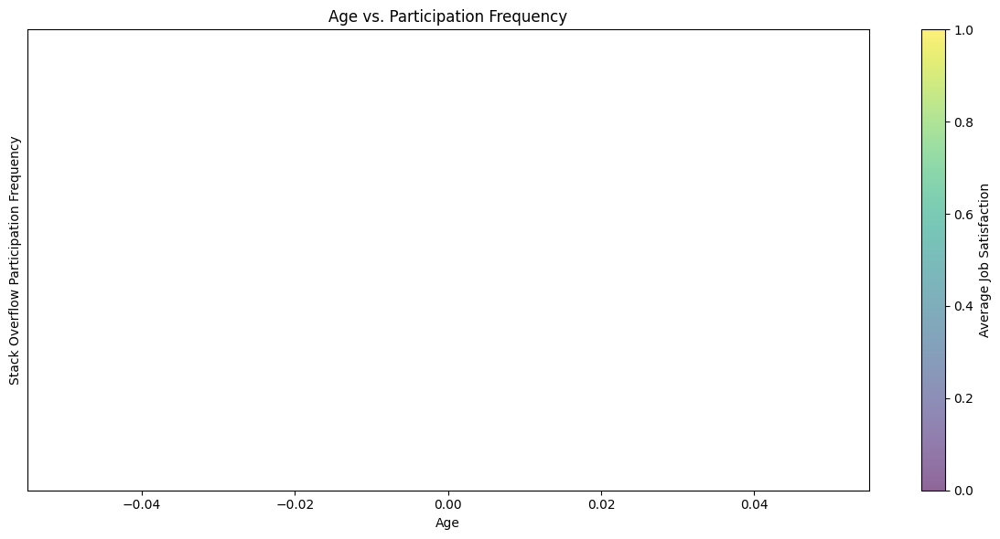

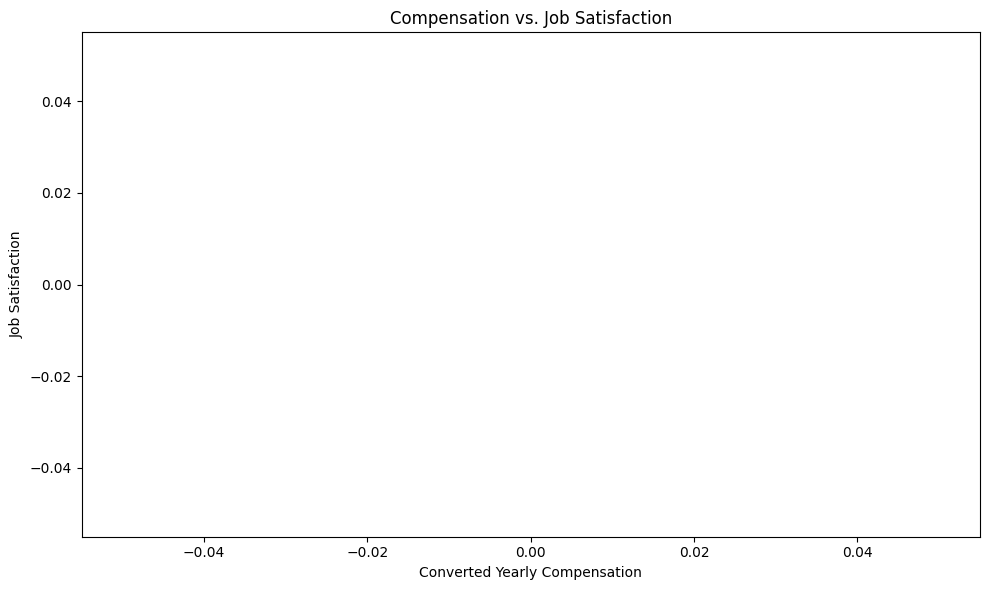

/tmp/ipykernel_4982/615674150.py:112: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  language_counts = df.groupby(


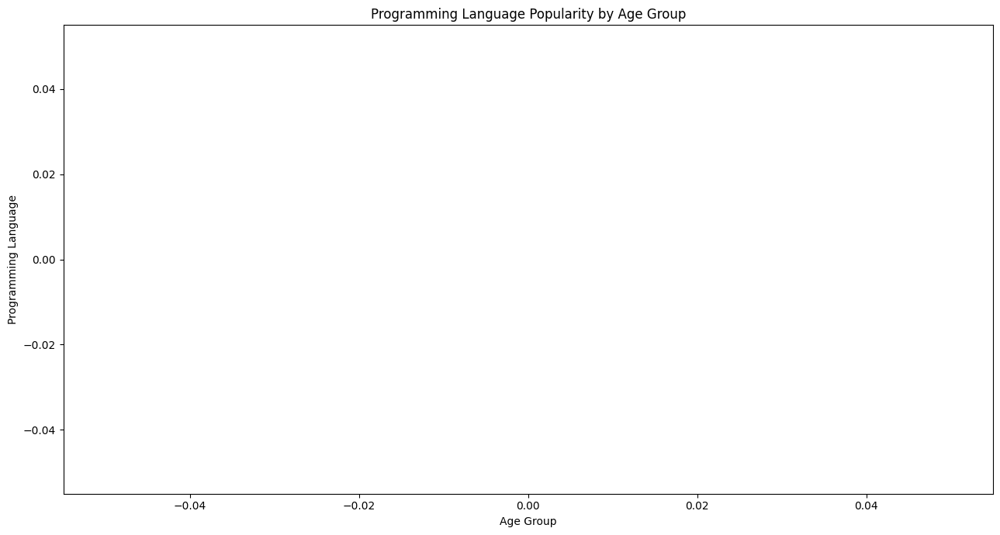

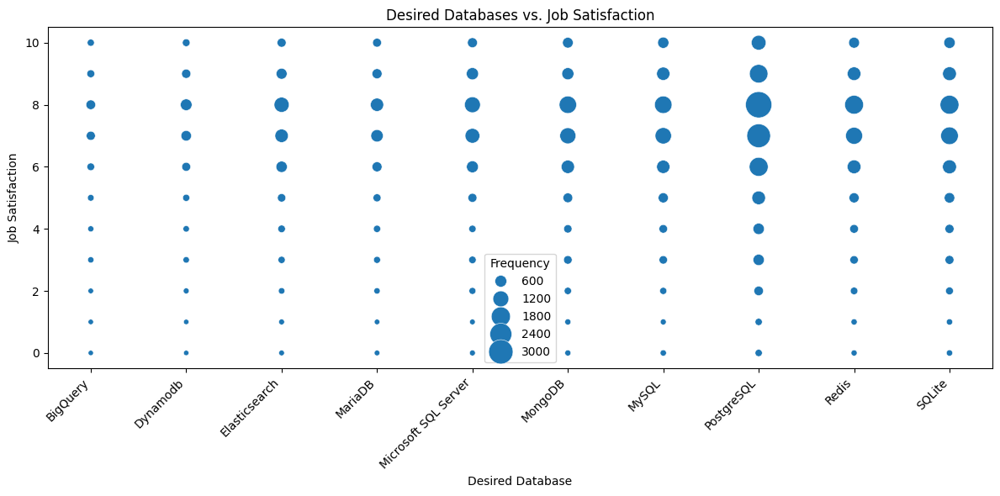

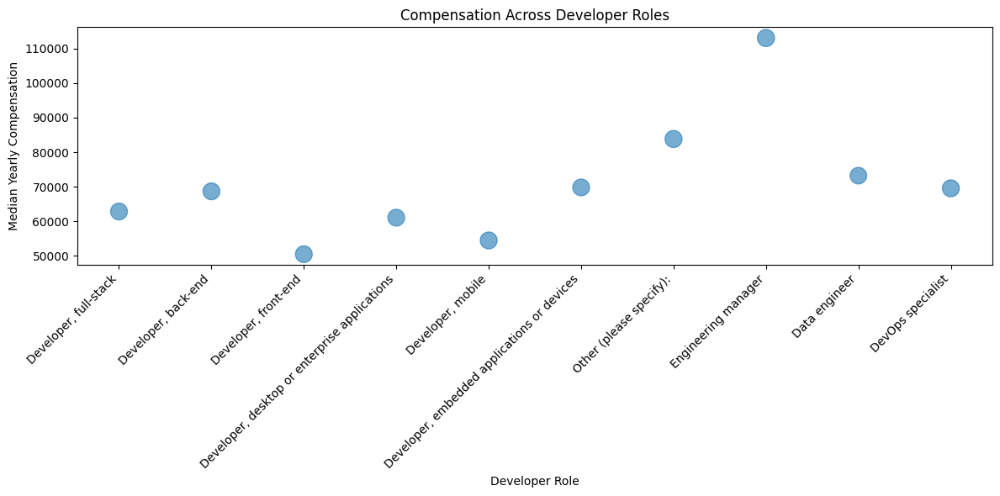

/tmp/ipykernel_4982/615674150.py:261: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tool_counts = df.groupby(


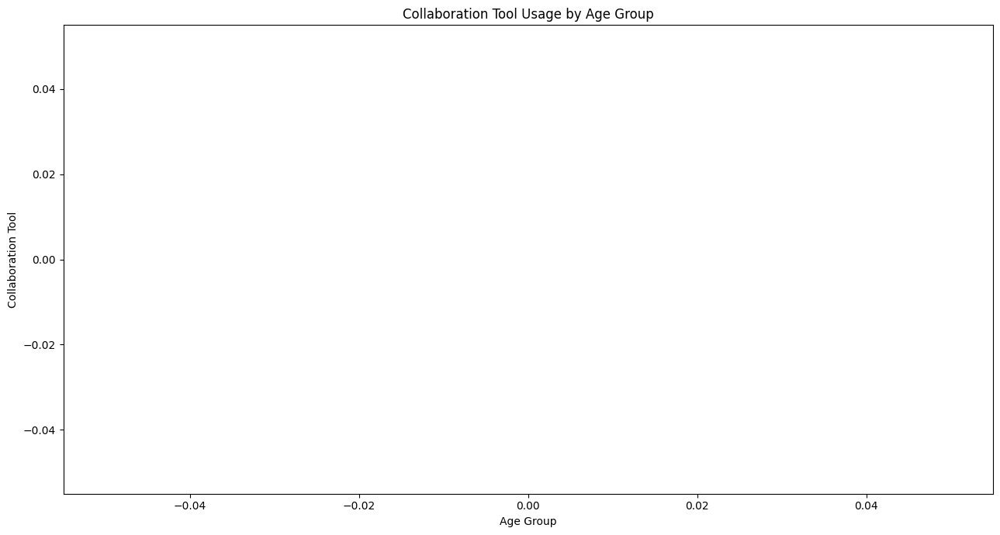

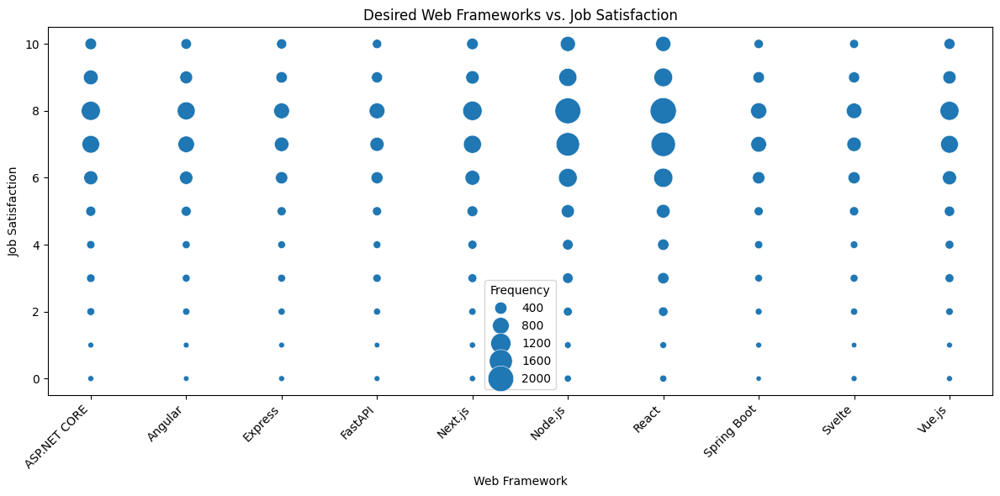

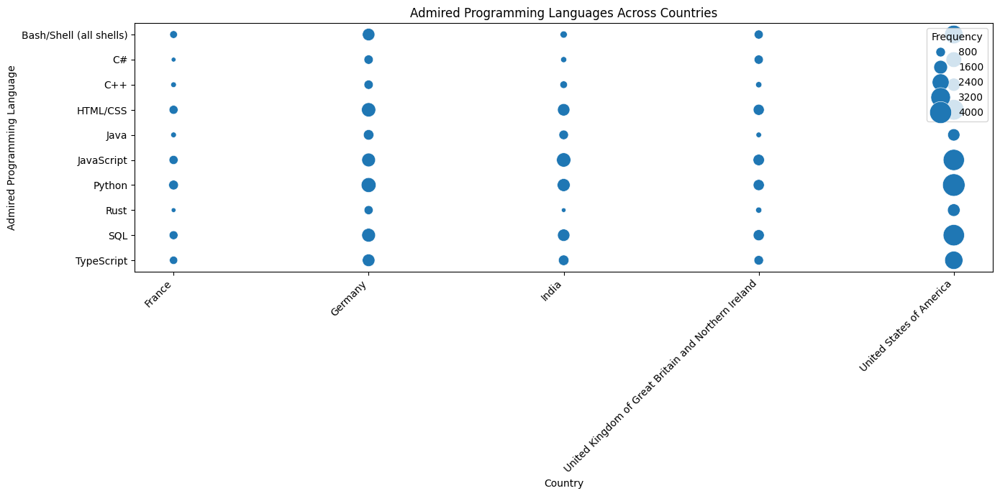

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the SQLite database
conn = sqlite3.connect("survey-data.sqlite")


# Task 1.1: Bubble Plot for Age vs. Participation Frequency
# Bubble size represents JobSat
query = """
SELECT Age, SOPartFreq, JobSat
FROM main
WHERE Age IS NOT NULL
AND SOPartFreq IS NOT NULL
AND JobSat IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["JobSat"] = pd.to_numeric(df["JobSat"], errors="coerce")
df = df.dropna(subset=["Age", "JobSat", "SOPartFreq"])

# Count respondents for each age and participation frequency
df_plot = df.groupby(["Age", "SOPartFreq"], as_index=False).agg(
    Frequency=("JobSat", "size"),
    AvgJobSat=("JobSat", "mean")
)

plt.figure(figsize=(12, 6))
scatter = plt.scatter(
    df_plot["Age"],
    df_plot["SOPartFreq"].astype("category").cat.codes,
    s=df_plot["AvgJobSat"].clip(lower=1) * 20,
    c=df_plot["AvgJobSat"],
    alpha=0.6
)
plt.yticks(
    range(len(df["SOPartFreq"].astype("category").cat.categories)),
    df["SOPartFreq"].astype("category").cat.categories
)
plt.title("Age vs. Participation Frequency")
plt.xlabel("Age")
plt.ylabel("Stack Overflow Participation Frequency")
plt.colorbar(scatter, label="Average Job Satisfaction")
plt.tight_layout()
plt.show()


# Task 1.2: Bubble Plot for Compensation vs. Job Satisfaction
# Bubble size represents Age
query = """
SELECT ConvertedCompYearly, JobSat, Age
FROM main
WHERE ConvertedCompYearly IS NOT NULL
AND JobSat IS NOT NULL
AND Age IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"], errors="coerce"
)
df["JobSat"] = pd.to_numeric(df["JobSat"], errors="coerce")
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df.dropna(
    subset=["ConvertedCompYearly", "JobSat", "Age"]
)

plt.figure(figsize=(10, 6))
plt.scatter(
    df["ConvertedCompYearly"],
    df["JobSat"],
    s=df["Age"] * 2,
    alpha=0.3
)
plt.title("Compensation vs. Job Satisfaction")
plt.xlabel("Converted Yearly Compensation")
plt.ylabel("Job Satisfaction")
plt.tight_layout()
plt.show()


# Task 2.1: Bubble Plot of Programming Languages by Age Group
# Bubble size represents language frequency
query = """
SELECT Age, LanguageHaveWorkedWith
FROM main
WHERE Age IS NOT NULL
AND LanguageHaveWorkedWith IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df.dropna(subset=["Age"])

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 24, 34, 44, 54, 64, 100],
    labels=["Under 25", "25-34", "35-44", "45-54", "55-64", "65+"]
)

df["LanguageHaveWorkedWith"] = (
    df["LanguageHaveWorkedWith"].str.split(";")
)
df = df.explode("LanguageHaveWorkedWith")
df["LanguageHaveWorkedWith"] = (
    df["LanguageHaveWorkedWith"].str.strip()
)

language_counts = df.groupby(
    ["AgeGroup", "LanguageHaveWorkedWith"]
).size().reset_index(name="Frequency")

top_languages = (
    language_counts.groupby("LanguageHaveWorkedWith")["Frequency"]
    .sum().nlargest(10).index
)
language_counts = language_counts[
    language_counts["LanguageHaveWorkedWith"].isin(top_languages)
]

plt.figure(figsize=(13, 7))
sns.scatterplot(
    data=language_counts,
    x="AgeGroup",
    y="LanguageHaveWorkedWith",
    size="Frequency",
    sizes=(20, 500),
    legend="brief"
)
plt.title("Programming Language Popularity by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Programming Language")
plt.tight_layout()
plt.show()


# Task 2.2: Bubble Plot for Desired Databases vs. Job Satisfaction
# Bubble size represents respondent count
query = """
SELECT DatabaseWantToWorkWith, JobSat
FROM main
WHERE DatabaseWantToWorkWith IS NOT NULL
AND JobSat IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["JobSat"] = pd.to_numeric(df["JobSat"], errors="coerce")
df = df.dropna(subset=["JobSat"])

df["DatabaseWantToWorkWith"] = (
    df["DatabaseWantToWorkWith"].str.split(";")
)
df = df.explode("DatabaseWantToWorkWith")
df["DatabaseWantToWorkWith"] = (
    df["DatabaseWantToWorkWith"].str.strip()
)

db_counts = df.groupby(
    ["DatabaseWantToWorkWith", "JobSat"]
).size().reset_index(name="Frequency")

top_databases = (
    db_counts.groupby("DatabaseWantToWorkWith")["Frequency"]
    .sum().nlargest(10).index
)
db_counts = db_counts[
    db_counts["DatabaseWantToWorkWith"].isin(top_databases)
]

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=db_counts,
    x="DatabaseWantToWorkWith",
    y="JobSat",
    size="Frequency",
    sizes=(20, 500),
    legend="brief"
)
plt.title("Desired Databases vs. Job Satisfaction")
plt.xlabel("Desired Database")
plt.ylabel("Job Satisfaction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Task 3.1: Bubble Plot for Compensation Across Developer Roles
# Bubble size represents average JobSat
query = """
SELECT DevType, ConvertedCompYearly, JobSat
FROM main
WHERE DevType IS NOT NULL
AND ConvertedCompYearly IS NOT NULL
AND JobSat IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["ConvertedCompYearly"] = pd.to_numeric(
    df["ConvertedCompYearly"], errors="coerce"
)
df["JobSat"] = pd.to_numeric(df["JobSat"], errors="coerce")
df = df.dropna(subset=["ConvertedCompYearly", "JobSat"])

df["DevType"] = df["DevType"].str.split(";")
df = df.explode("DevType")
df["DevType"] = df["DevType"].str.strip()

role_data = df.groupby("DevType").agg(
    MedianComp=("ConvertedCompYearly", "median"),
    AvgJobSat=("JobSat", "mean"),
    Respondents=("JobSat", "size")
).reset_index()

top_roles = role_data.nlargest(10, "Respondents")

plt.figure(figsize=(12, 6))
plt.scatter(
    top_roles["DevType"],
    top_roles["MedianComp"],
    s=top_roles["AvgJobSat"].clip(lower=1) * 30,
    alpha=0.6
)
plt.title("Compensation Across Developer Roles")
plt.xlabel("Developer Role")
plt.ylabel("Median Yearly Compensation")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Task 3.2: Bubble Plot for Collaboration Tools by Age Group
# Bubble size represents tool usage frequency
query = """
SELECT Age, NEWCollabToolsHaveWorkedWith
FROM main
WHERE Age IS NOT NULL
AND NEWCollabToolsHaveWorkedWith IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df.dropna(subset=["Age"])

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 24, 34, 44, 54, 64, 100],
    labels=["Under 25", "25-34", "35-44", "45-54", "55-64", "65+"]
)

df["NEWCollabToolsHaveWorkedWith"] = (
    df["NEWCollabToolsHaveWorkedWith"].str.split(";")
)
df = df.explode("NEWCollabToolsHaveWorkedWith")
df["NEWCollabToolsHaveWorkedWith"] = (
    df["NEWCollabToolsHaveWorkedWith"].str.strip()
)

tool_counts = df.groupby(
    ["AgeGroup", "NEWCollabToolsHaveWorkedWith"]
).size().reset_index(name="Frequency")

top_tools = (
    tool_counts.groupby("NEWCollabToolsHaveWorkedWith")["Frequency"]
    .sum().nlargest(10).index
)
tool_counts = tool_counts[
    tool_counts["NEWCollabToolsHaveWorkedWith"].isin(top_tools)
]

plt.figure(figsize=(13, 7))
sns.scatterplot(
    data=tool_counts,
    x="AgeGroup",
    y="NEWCollabToolsHaveWorkedWith",
    size="Frequency",
    sizes=(20, 500),
    legend="brief"
)
plt.title("Collaboration Tool Usage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Collaboration Tool")
plt.tight_layout()
plt.show()


# Task 4.1: Bubble Plot for Desired Web Frameworks vs. Job Satisfaction
# Bubble size represents respondent count
query = """
SELECT WebframeWantToWorkWith, JobSat
FROM main
WHERE WebframeWantToWorkWith IS NOT NULL
AND JobSat IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["JobSat"] = pd.to_numeric(df["JobSat"], errors="coerce")
df = df.dropna(subset=["JobSat"])

df["WebframeWantToWorkWith"] = (
    df["WebframeWantToWorkWith"].str.split(";")
)
df = df.explode("WebframeWantToWorkWith")
df["WebframeWantToWorkWith"] = (
    df["WebframeWantToWorkWith"].str.strip()
)

framework_counts = df.groupby(
    ["WebframeWantToWorkWith", "JobSat"]
).size().reset_index(name="Frequency")

top_frameworks = (
    framework_counts.groupby("WebframeWantToWorkWith")["Frequency"]
    .sum().nlargest(10).index
)
framework_counts = framework_counts[
    framework_counts["WebframeWantToWorkWith"].isin(top_frameworks)
]

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=framework_counts,
    x="WebframeWantToWorkWith",
    y="JobSat",
    size="Frequency",
    sizes=(20, 500),
    legend="brief"
)
plt.title("Desired Web Frameworks vs. Job Satisfaction")
plt.xlabel("Web Framework")
plt.ylabel("Job Satisfaction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Task 4.2: Bubble Plot for Admired Languages Across Countries
# Bubble size represents frequency of admiration
query = """
SELECT Country, LanguageAdmired
FROM main
WHERE Country IS NOT NULL
AND LanguageAdmired IS NOT NULL
"""
df = pd.read_sql_query(query, conn)

df["LanguageAdmired"] = df["LanguageAdmired"].str.split(";")
df = df.explode("LanguageAdmired")
df["LanguageAdmired"] = df["LanguageAdmired"].str.strip()

admired_counts = df.groupby(
    ["Country", "LanguageAdmired"]
).size().reset_index(name="Frequency")

top_countries = (
    df["Country"].value_counts().head(5).index
)
top_languages = (
    df["LanguageAdmired"].value_counts().head(10).index
)

admired_counts = admired_counts[
    admired_counts["Country"].isin(top_countries)
    & admired_counts["LanguageAdmired"].isin(top_languages)
]

plt.figure(figsize=(14, 7))
sns.scatterplot(
    data=admired_counts,
    x="Country",
    y="LanguageAdmired",
    size="Frequency",
    sizes=(20, 500),
    legend="brief"
)
plt.title("Admired Programming Languages Across Countries")
plt.xlabel("Country")
plt.ylabel("Admired Programming Language")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# Final Step: Close the database connection
conn.close()


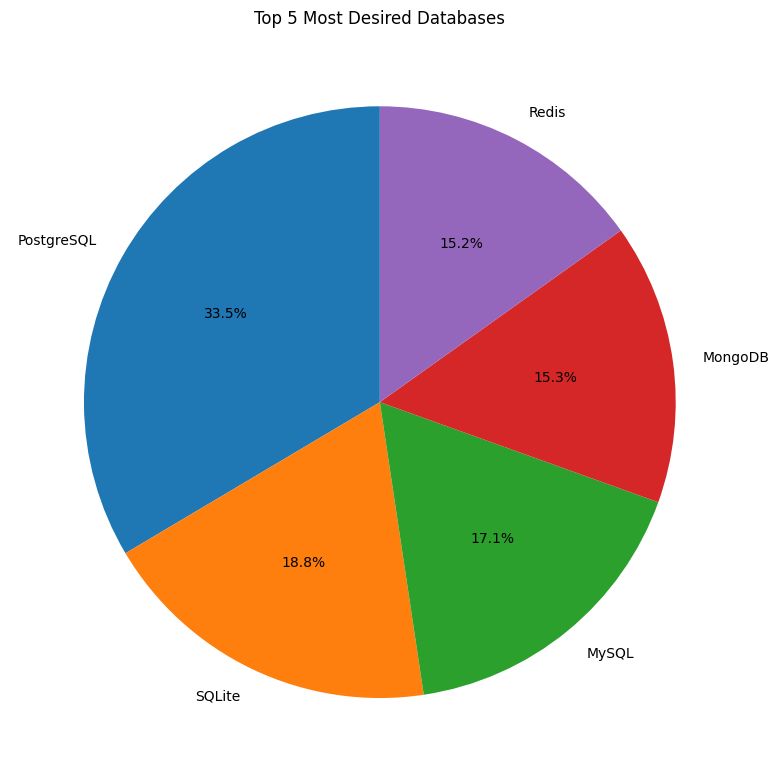

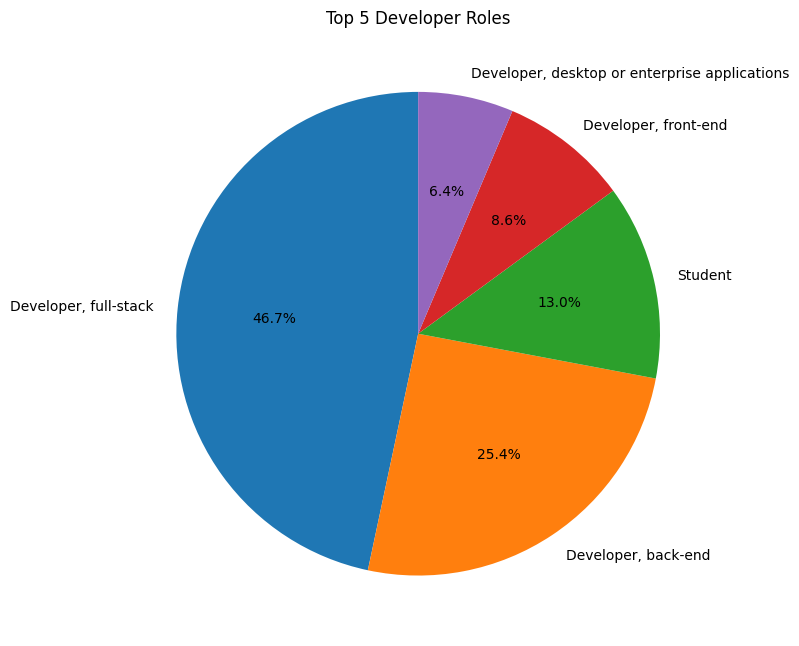

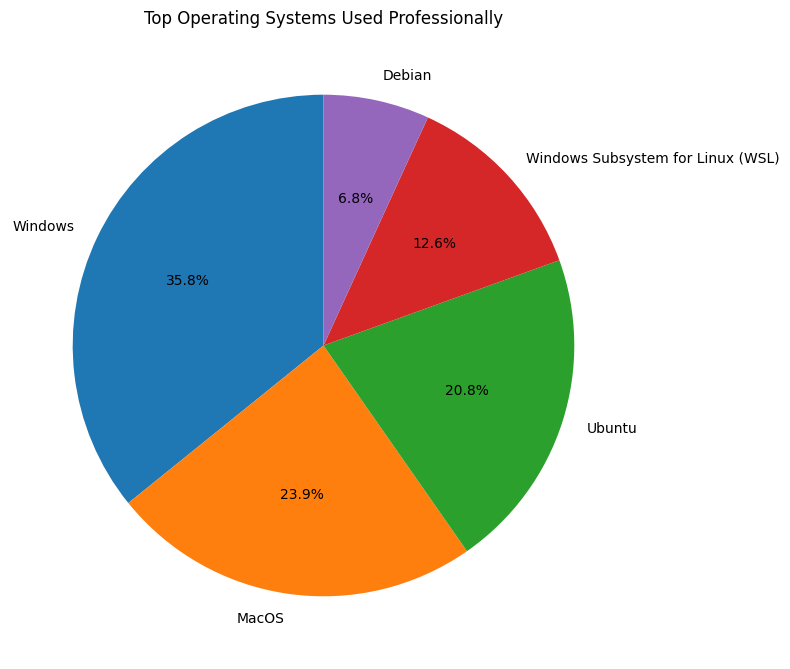

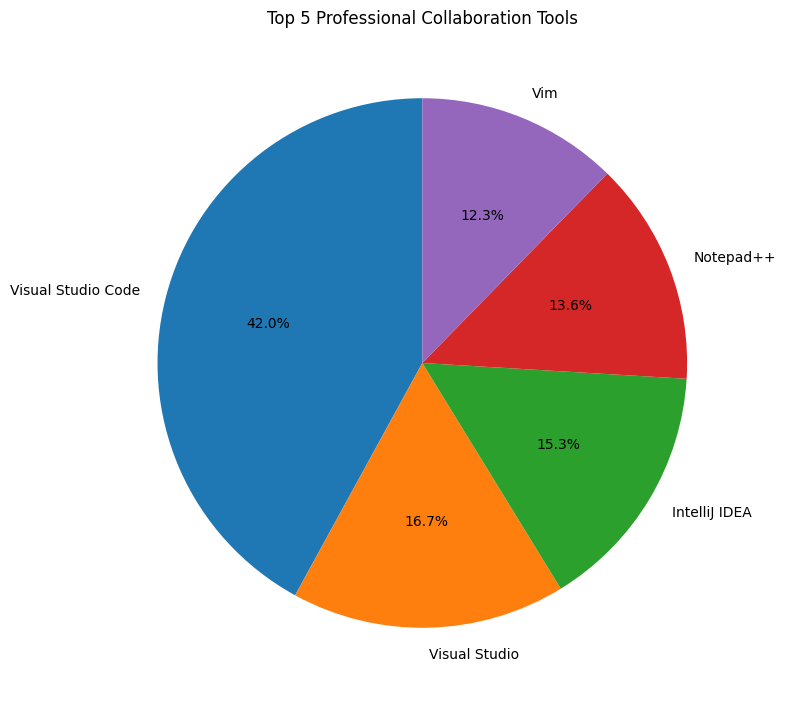

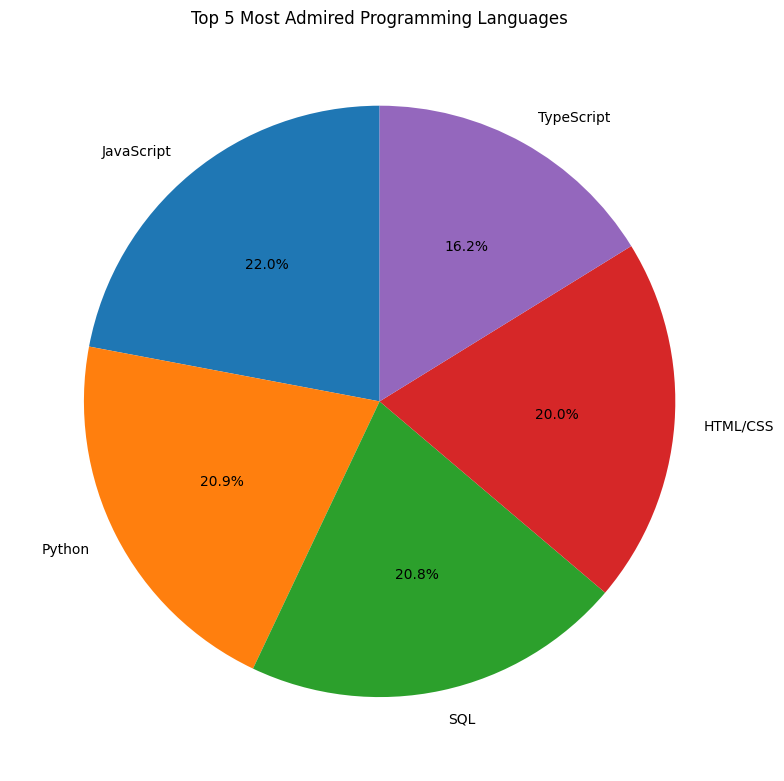

KeyError: 'AIToolCurrentlyUsing'

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Connect to the SQLite database
conn = sqlite3.connect("survey-data.sqlite")


# Helper function to create pie charts for top 5 categories
def plot_top5_pie(column, title):
    query = f"""
    SELECT "{column}"
    FROM main
    WHERE "{column}" IS NOT NULL
    """
    df = pd.read_sql_query(query, conn)

    # Split multiple selections and count each response
    counts = (
        df[column]
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
    )

    counts = counts[counts != ""].value_counts().head(5)

    plt.figure(figsize=(8, 8))
    plt.pie(
        counts.values,
        labels=counts.index,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()


# Task 1.1: Top 5 Databases Respondents Want to Work With
plot_top5_pie(
    "DatabaseWantToWorkWith",
    "Top 5 Most Desired Databases"
)


# Task 1.2: Top 5 Developer Types
plot_top5_pie(
    "DevType",
    "Top 5 Developer Roles"
)


# Task 1.3: Top Operating Systems Used Professionally
plot_top5_pie(
    "OpSysProfessional use",
    "Top Operating Systems Used Professionally"
)


# Task 2.2: Top Collaboration Tools Used Professionally
plot_top5_pie(
    "NEWCollabToolsHaveWorkedWith",
    "Top 5 Professional Collaboration Tools"
)


# Task 3.1: Top 5 Most Admired Programming Languages
plot_top5_pie(
    "LanguageAdmired",
    "Top 5 Most Admired Programming Languages"
)


# Task 3.2: Top 5 AI Development Tools Currently Used
plot_top5_pie(
    "AIToolCurrentlyUsing",
    "Top 5 AI Development Tools Currently Used"
)


# Task 3.3: Top 5 Preferred Web Frameworks
plot_top5_pie(
    "WebframeWantToWorkWith",
    "Top 5 Most Desired Web Frameworks"
)


# Task 3.4: Top 5 Most Desired Embedded Technologies
plot_top5_pie(
    "EmbeddedWantToWorkWith",
    "Top 5 Most Desired Embedded Technologies"
)


# Close the database connection
conn.close()

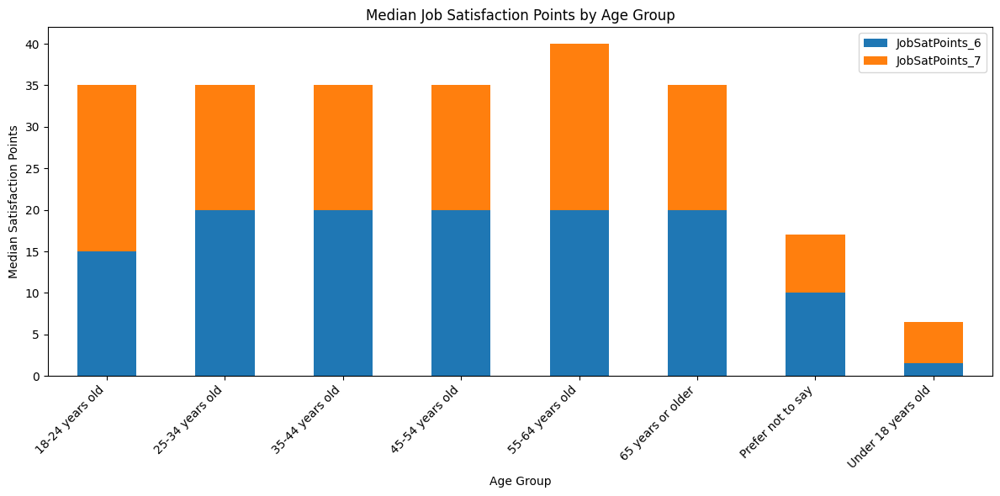

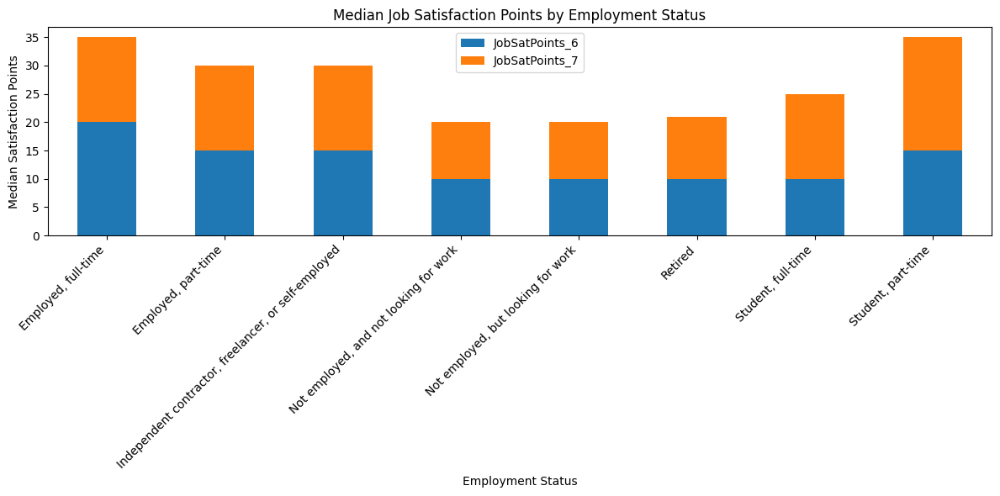

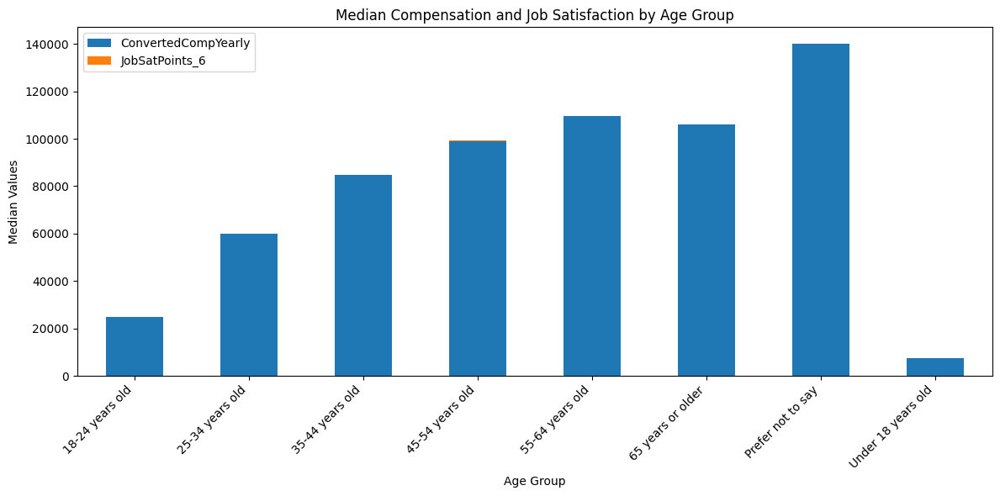

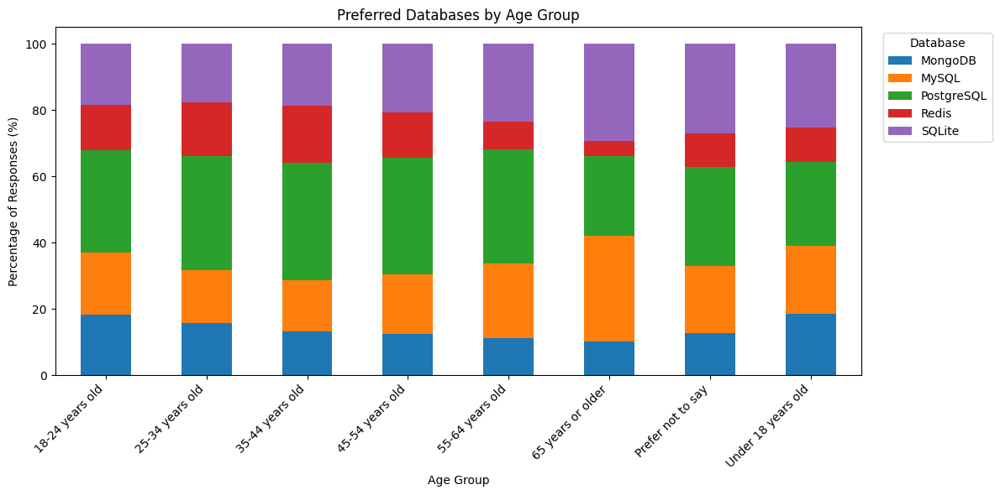

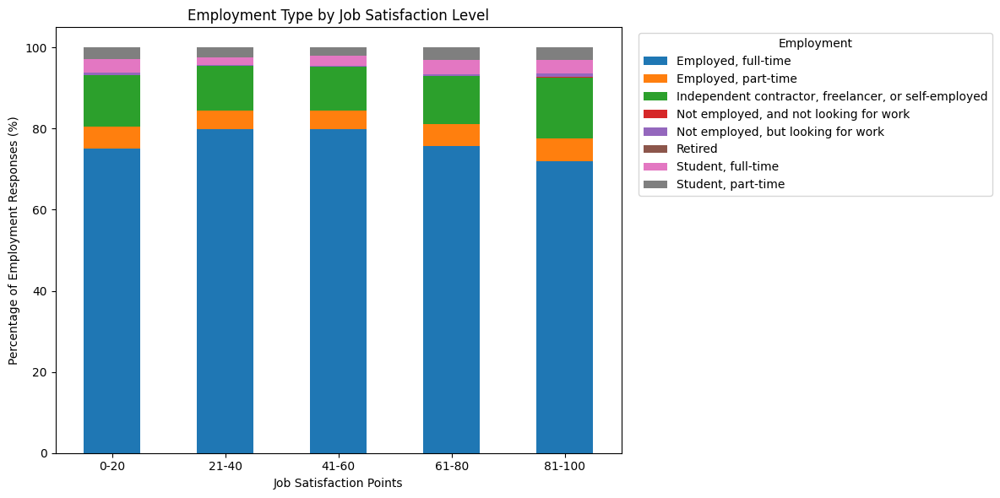

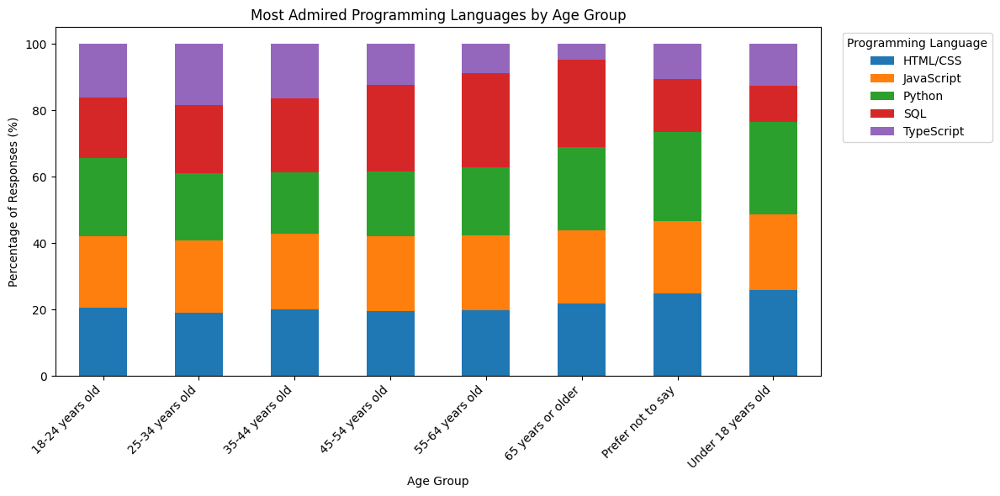

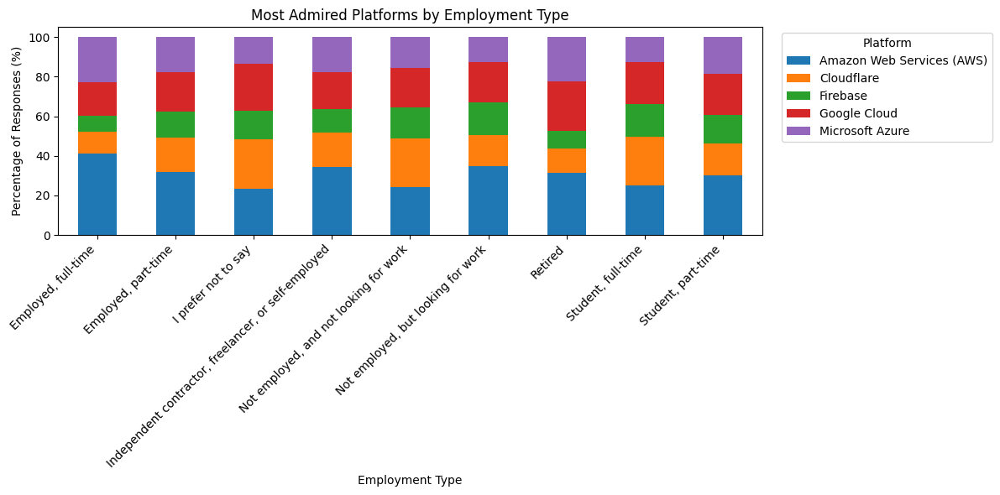

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Connect to the SQLite database and load the data
conn = sqlite3.connect("survey-data.sqlite")
df = pd.read_sql_query('SELECT * FROM main', conn)
conn.close()

# Convert relevant columns to numeric where possible
numeric_cols = [
    "JobSatPoints_6",
    "JobSatPoints_7",
    "ConvertedCompYearly"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


# Helper function to split multi-select survey responses
def split_responses(data, column):
    temp = data[["Age", column]].dropna().copy()
    temp[column] = temp[column].astype(str).str.split(";")
    temp = temp.explode(column)
    temp[column] = temp[column].str.strip()
    temp = temp[temp[column] != ""]
    return temp


# ============================================================
# TASK 1.1: Stacked Chart of Median Job Satisfaction by Age
# ============================================================

required = ["Age", "JobSatPoints_6", "JobSatPoints_7"]

if all(col in df.columns for col in required):
    age_satisfaction = (
        df.groupby("Age")[["JobSatPoints_6", "JobSatPoints_7"]]
        .median()
        .dropna(how="all")
    )

    age_satisfaction.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Median Job Satisfaction Points by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Median Satisfaction Points")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Task 1.1 skipped: Check the required column names.")


# ============================================================
# TASK 1.2: Stacked Chart of Job Satisfaction by Employment
# ============================================================

required = ["Employment", "JobSatPoints_6", "JobSatPoints_7"]

if all(col in df.columns for col in required):
    employment_df = df[required].dropna(subset=["Employment"]).copy()

    employment_df["Employment"] = (
        employment_df["Employment"].astype(str).str.split(";")
    )
    employment_df = employment_df.explode("Employment")
    employment_df["Employment"] = employment_df["Employment"].str.strip()

    employment_satisfaction = (
        employment_df.groupby("Employment")[
            ["JobSatPoints_6", "JobSatPoints_7"]
        ]
        .median()
        .dropna(how="all")
        .sort_index()
    )

    employment_satisfaction.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Median Job Satisfaction Points by Employment Status")
    plt.xlabel("Employment Status")
    plt.ylabel("Median Satisfaction Points")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Task 1.2 skipped: Check the required column names.")


# ============================================================
# TASK 2: Stacked Chart of Median Compensation and Satisfaction
# by Age Group
# ============================================================

required = ["Age", "ConvertedCompYearly", "JobSatPoints_6"]

if all(col in df.columns for col in required):
    age_comp_satisfaction = (
        df.groupby("Age")[["ConvertedCompYearly", "JobSatPoints_6"]]
        .median()
        .dropna(how="all")
    )

    age_comp_satisfaction.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Median Compensation and Job Satisfaction by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Median Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Task 2 skipped: Check the required column names.")


# ============================================================
# TASK 3.1: Stacked Chart of Preferred Databases by Age Group
# ============================================================

if all(col in df.columns for col in ["Age", "DatabaseWantToWorkWith"]):
    database_df = split_responses(df, "DatabaseWantToWorkWith")

    # Select the five most frequently preferred databases
    top_databases = database_df["DatabaseWantToWorkWith"].value_counts().head(5).index
    database_df = database_df[
        database_df["DatabaseWantToWorkWith"].isin(top_databases)
    ]

    database_counts = pd.crosstab(
        database_df["Age"],
        database_df["DatabaseWantToWorkWith"],
        normalize="index"
    ) * 100

    database_counts.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Preferred Databases by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Percentage of Responses (%)")
    plt.legend(title="Database", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Task 3.1 skipped: Check the required column names.")


# ============================================================
# TASK 3.2: Stacked Chart of Employment Type by Job Satisfaction
# ============================================================

if all(col in df.columns for col in ["Employment", "JobSatPoints_6"]):
    satisfaction_df = df[["Employment", "JobSatPoints_6"]].dropna().copy()

    # Group numeric satisfaction scores into five bands
    satisfaction_df["Satisfaction Level"] = pd.cut(
        satisfaction_df["JobSatPoints_6"],
        bins=[-float("inf"), 20, 40, 60, 80, float("inf")],
        labels=["0-20", "21-40", "41-60", "61-80", "81-100"]
    )

    satisfaction_df["Employment"] = (
        satisfaction_df["Employment"].astype(str).str.split(";")
    )
    satisfaction_df = satisfaction_df.explode("Employment")
    satisfaction_df["Employment"] = satisfaction_df["Employment"].str.strip()

    employment_by_satisfaction = pd.crosstab(
        satisfaction_df["Satisfaction Level"],
        satisfaction_df["Employment"],
        normalize="index"
    ) * 100

    employment_by_satisfaction.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Employment Type by Job Satisfaction Level")
    plt.xlabel("Job Satisfaction Points")
    plt.ylabel("Percentage of Employment Responses (%)")
    plt.legend(title="Employment", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Task 3.2 skipped: Check the required column names.")


# ============================================================
# TASK 4.1: Stacked Chart of Admired Programming Languages by Age
# ============================================================

if all(col in df.columns for col in ["Age", "LanguageAdmired"]):
    language_df = split_responses(df, "LanguageAdmired")

    top_languages = language_df["LanguageAdmired"].value_counts().head(5).index
    language_df = language_df[
        language_df["LanguageAdmired"].isin(top_languages)
    ]

    language_counts = pd.crosstab(
        language_df["Age"],
        language_df["LanguageAdmired"],
        normalize="index"
    ) * 100

    language_counts.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Most Admired Programming Languages by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Percentage of Responses (%)")
    plt.legend(title="Programming Language", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Task 4.1 skipped: Check the required column names.")


# ============================================================
# TASK 4.2: Stacked Chart of Admired Platforms by Employment Type
# ============================================================

if all(col in df.columns for col in ["Employment", "PlatformAdmired"]):
    platform_df = df[["Employment", "PlatformAdmired"]].dropna().copy()

    platform_df["Employment"] = platform_df["Employment"].astype(str).str.split(";")
    platform_df["PlatformAdmired"] = (
        platform_df["PlatformAdmired"].astype(str).str.split(";")
    )

    # Expand multiple employment and platform selections
    platform_df = platform_df.explode("Employment")
    platform_df = platform_df.explode("PlatformAdmired")

    platform_df["Employment"] = platform_df["Employment"].str.strip()
    platform_df["PlatformAdmired"] = platform_df["PlatformAdmired"].str.strip()

    top_platforms = platform_df["PlatformAdmired"].value_counts().head(5).index
    platform_df = platform_df[
        platform_df["PlatformAdmired"].isin(top_platforms)
    ]

    platform_counts = pd.crosstab(
        platform_df["Employment"],
        platform_df["PlatformAdmired"],
        normalize="index"
    ) * 100

    platform_counts.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )
    plt.title("Most Admired Platforms by Employment Type")
    plt.xlabel("Employment Type")
    plt.ylabel("Percentage of Responses (%)")
    plt.legend(title="Platform", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Task 4.2 skipped: Check the required column names.")


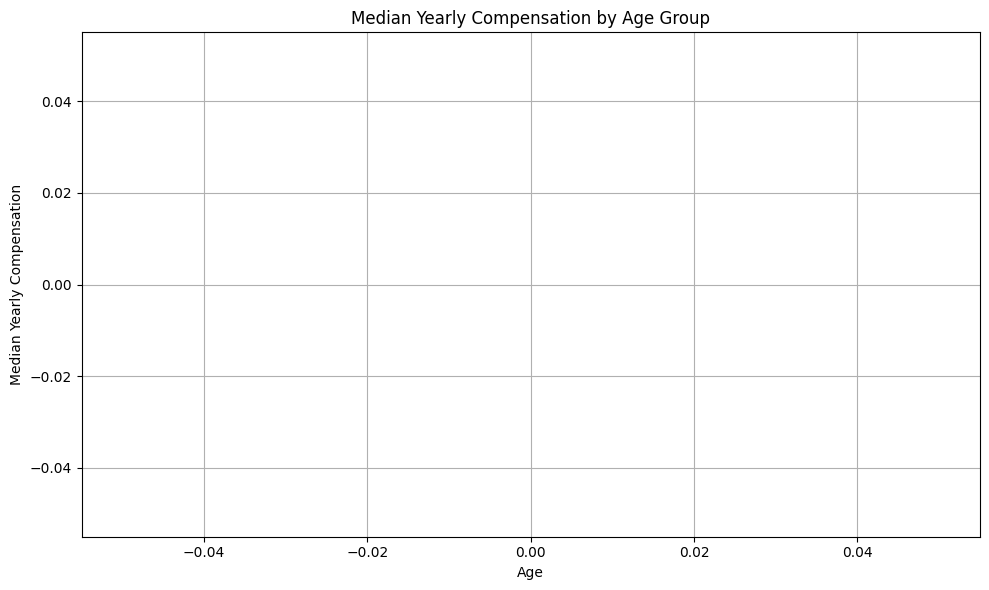

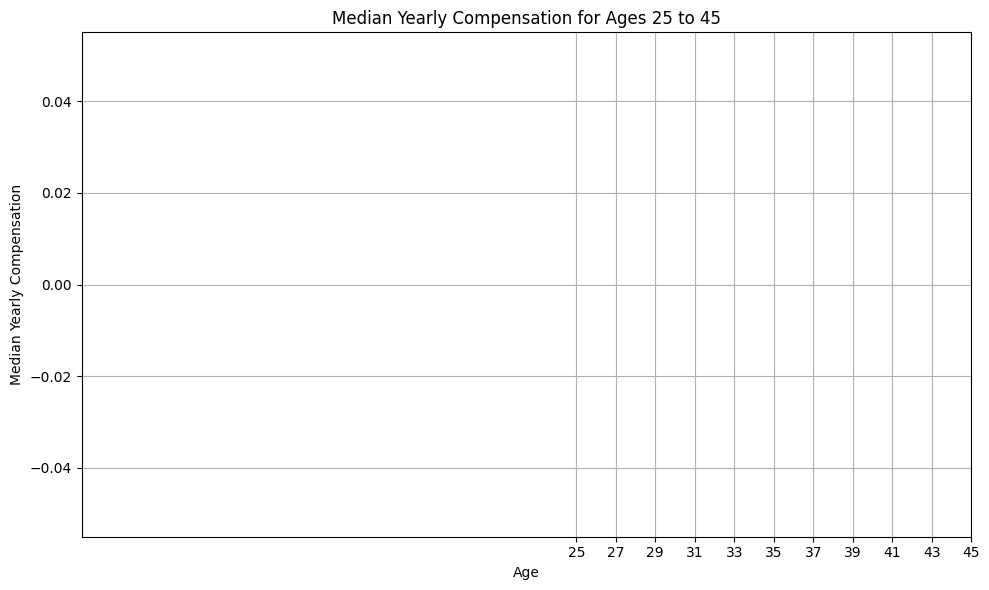

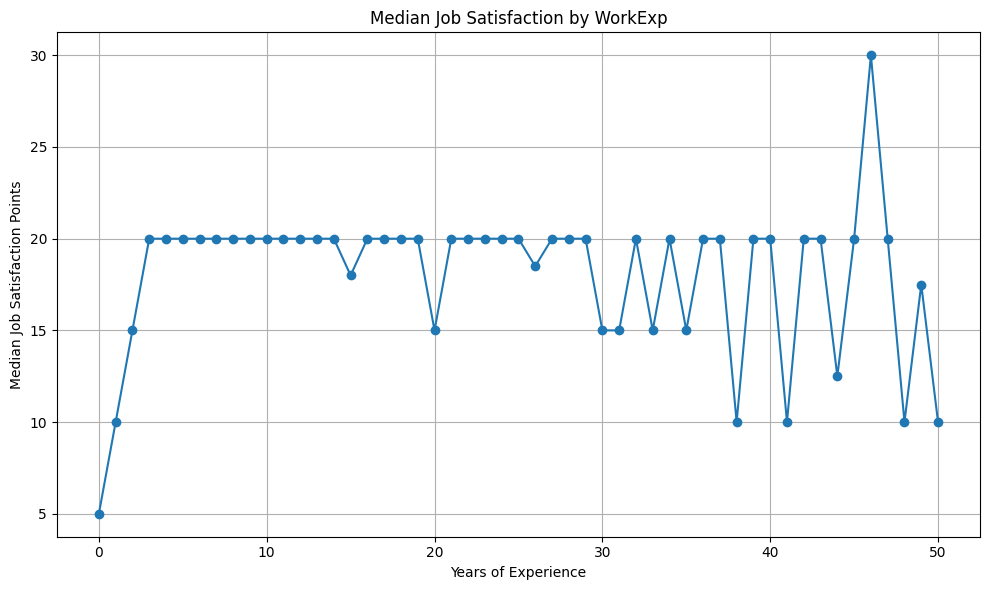

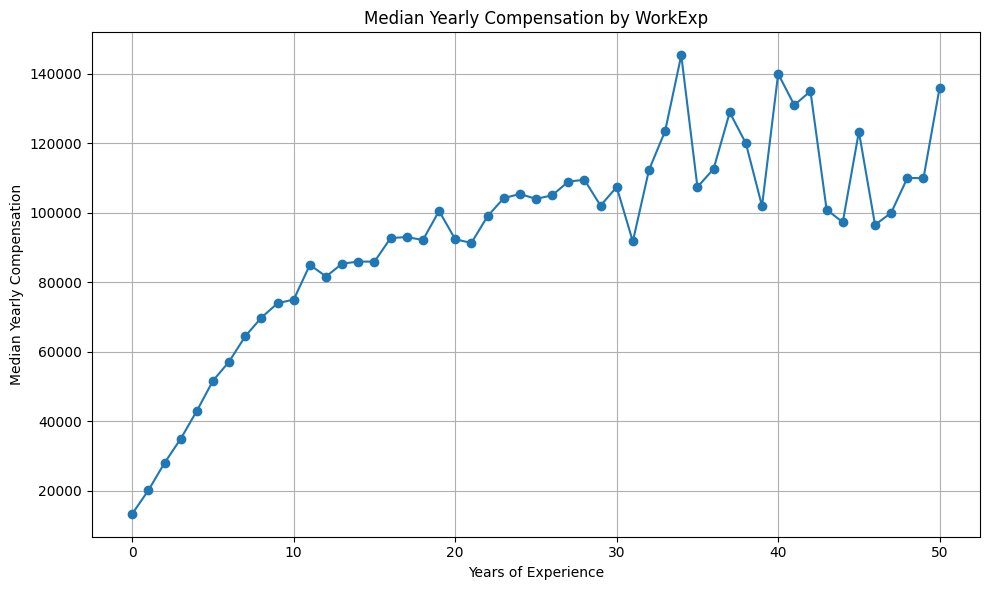

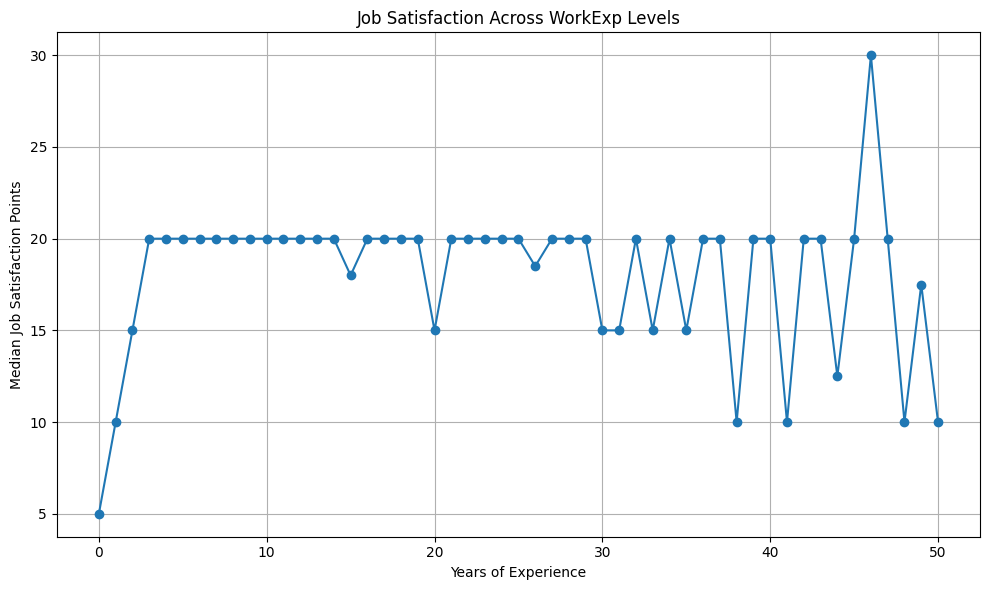

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Connect to SQLite database
conn = sqlite3.connect("survey-data.sqlite")
df = pd.read_sql_query("SELECT * FROM main", conn)
conn.close()

# Convert columns to numeric
numeric_columns = [
    "Age",
    "ConvertedCompYearly",
    "JobSatPoints_6",
    "WorkExp",
    "YearsCodePro"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


# ============================================================
# TASK 1.1: Line Chart of Median Compensation by Age Group
# ============================================================

if all(col in df.columns for col in ["Age", "ConvertedCompYearly"]):
    compensation_by_age = (
        df.groupby("Age")["ConvertedCompYearly"]
        .median()
        .dropna()
        .sort_index()
    )

    plt.figure(figsize=(10, 6))
    plt.plot(compensation_by_age.index, compensation_by_age.values, marker="o")
    plt.title("Median Yearly Compensation by Age Group")
    plt.xlabel("Age")
    plt.ylabel("Median Yearly Compensation")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Task 1.1: Required columns not found.")


# ============================================================
# TASK 1.2: Line Chart of Median Compensation for Ages 25-45
# ============================================================

if all(col in df.columns for col in ["Age", "ConvertedCompYearly"]):
    age_filtered = df[df["Age"].between(25, 45)]

    compensation_25_45 = (
        age_filtered.groupby("Age")["ConvertedCompYearly"]
        .median()
        .dropna()
        .sort_index()
    )

    plt.figure(figsize=(10, 6))
    plt.plot(compensation_25_45.index, compensation_25_45.values, marker="o")
    plt.title("Median Yearly Compensation for Ages 25 to 45")
    plt.xlabel("Age")
    plt.ylabel("Median Yearly Compensation")
    plt.xticks(range(25, 46, 2))
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Task 1.2: Required columns not found.")


# ============================================================
# TASK 2: Line Chart of Job Satisfaction by Experience Level
# Use WorkExp if available; otherwise use YearsCodePro
# ============================================================

if "WorkExp" in df.columns:
    experience_col = "WorkExp"
elif "YearsCodePro" in df.columns:
    experience_col = "YearsCodePro"
else:
    experience_col = None

if experience_col and "JobSatPoints_6" in df.columns:
    satisfaction_by_experience = (
        df.groupby(experience_col)["JobSatPoints_6"]
        .median()
        .dropna()
        .sort_index()
    )

    plt.figure(figsize=(10, 6))
    plt.plot(
        satisfaction_by_experience.index,
        satisfaction_by_experience.values,
        marker="o"
    )
    plt.title(f"Median Job Satisfaction by {experience_col}")
    plt.xlabel("Years of Experience")
    plt.ylabel("Median Job Satisfaction Points")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Task 2: No suitable experience or satisfaction column found.")


# ============================================================
# TASK 3.1: Line Chart of Median Compensation by Experience
# ============================================================

if experience_col and "ConvertedCompYearly" in df.columns:
    compensation_by_experience = (
        df.groupby(experience_col)["ConvertedCompYearly"]
        .median()
        .dropna()
        .sort_index()
    )

    plt.figure(figsize=(10, 6))
    plt.plot(
        compensation_by_experience.index,
        compensation_by_experience.values,
        marker="o"
    )
    plt.title(f"Median Yearly Compensation by {experience_col}")
    plt.xlabel("Years of Experience")
    plt.ylabel("Median Yearly Compensation")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Task 3.1: No suitable experience or compensation column found.")


# ============================================================
# TASK 3.2: Line Chart of Job Satisfaction Across Experience
# ============================================================

if experience_col and "JobSatPoints_6" in df.columns:
    satisfaction_by_experience = (
        df.groupby(experience_col)["JobSatPoints_6"]
        .median()
        .dropna()
        .sort_index()
    )

    plt.figure(figsize=(10, 6))
    plt.plot(
        satisfaction_by_experience.index,
        satisfaction_by_experience.values,
        marker="o"
    )
    plt.title(f"Job Satisfaction Across {experience_col} Levels")
    plt.xlabel("Years of Experience")
    plt.ylabel("Median Job Satisfaction Points")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Task 3.2: No suitable experience or satisfaction column found.")


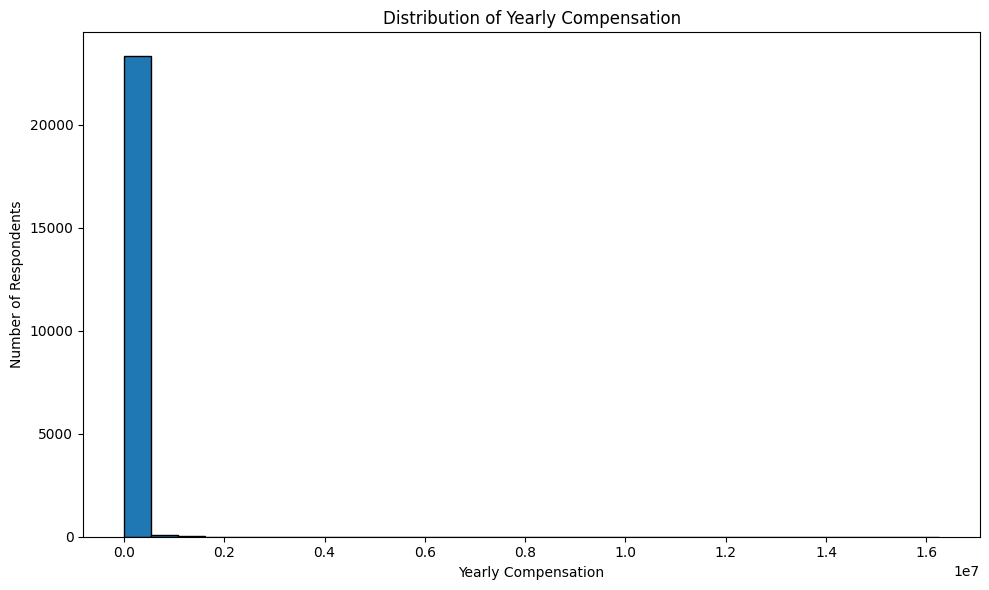

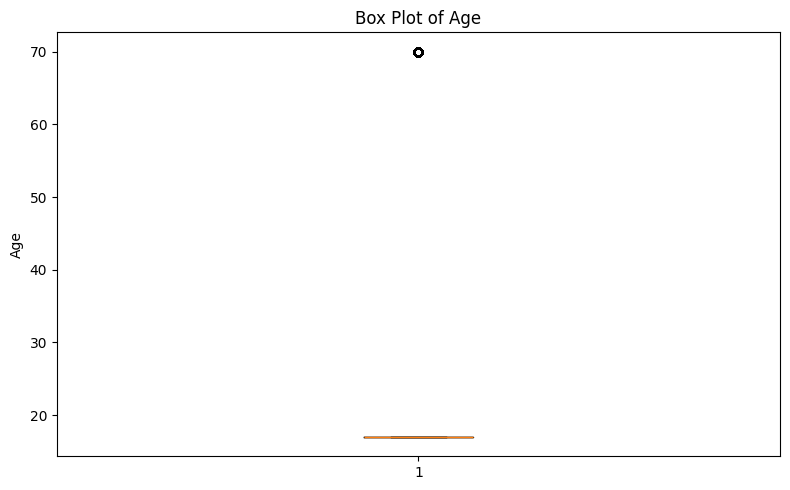

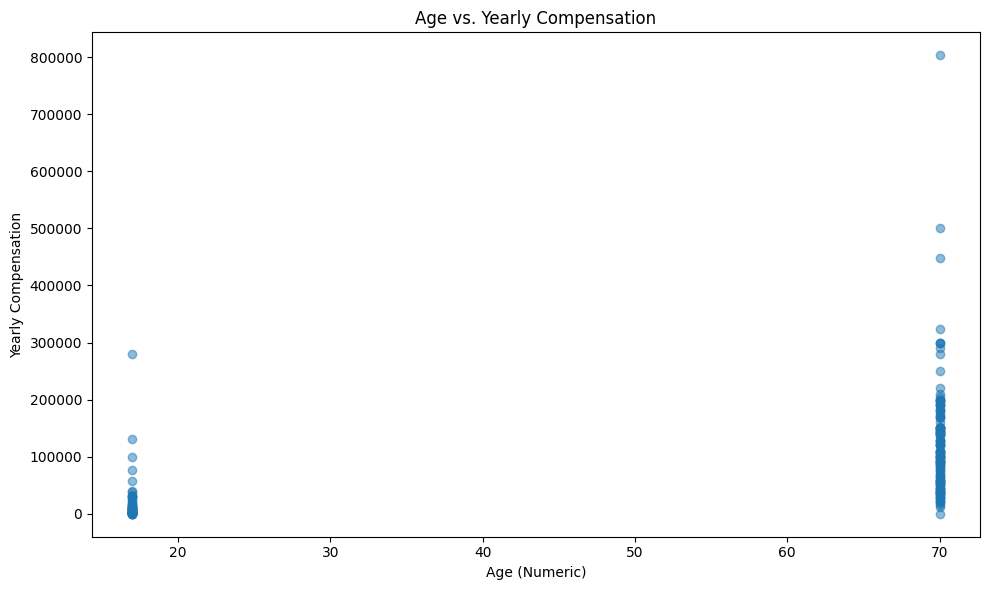

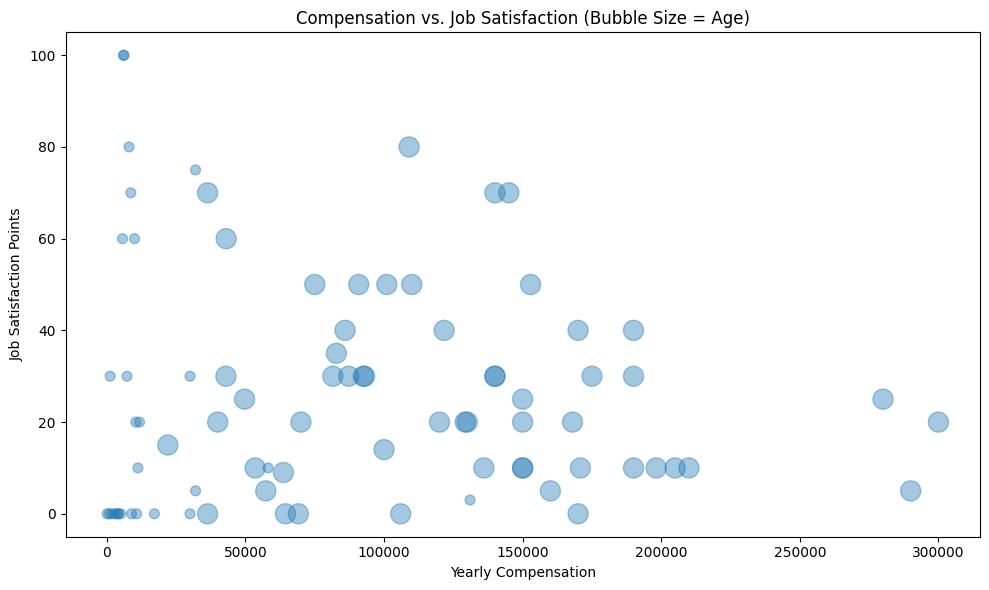

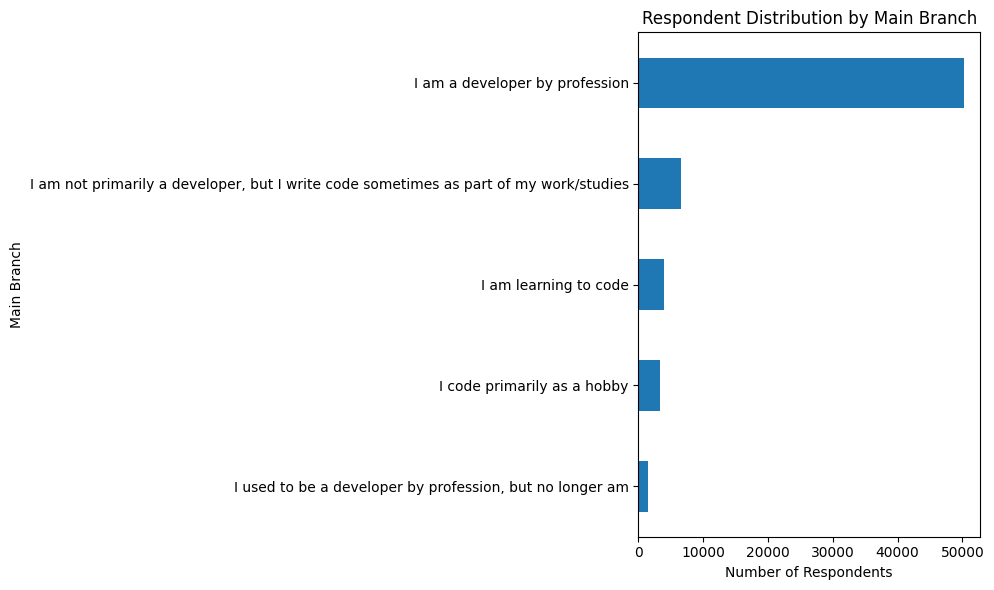

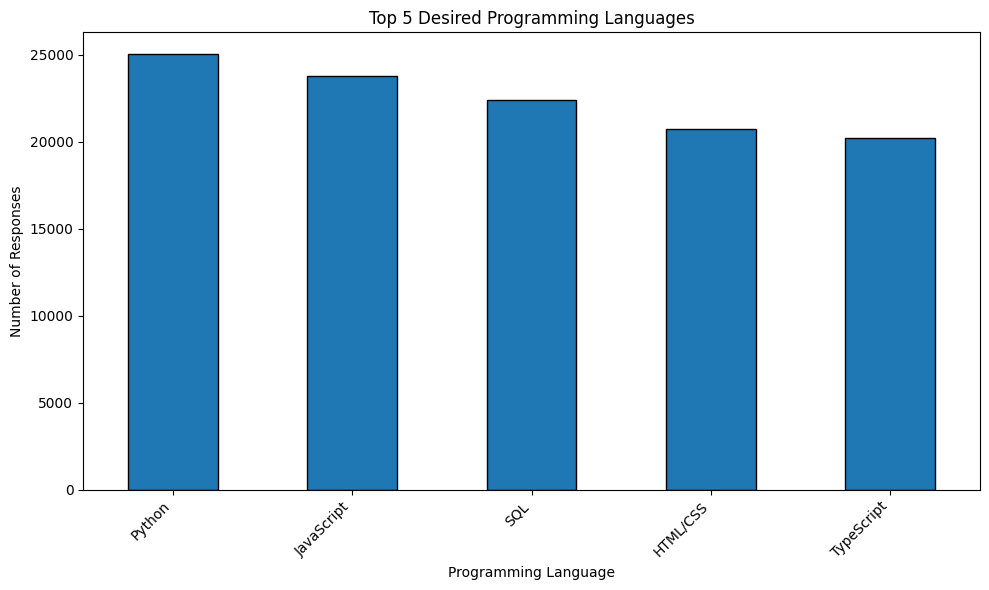

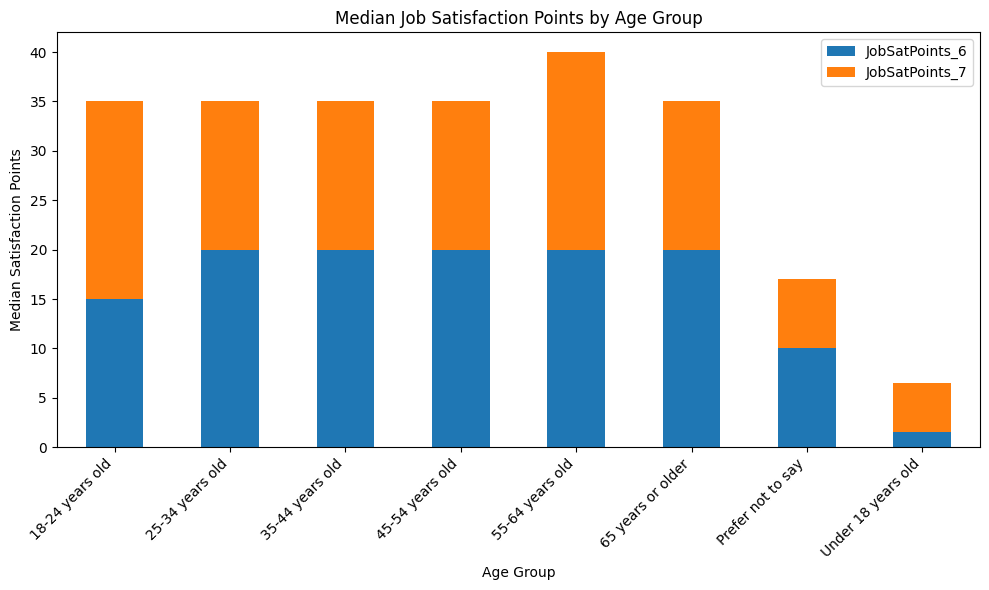

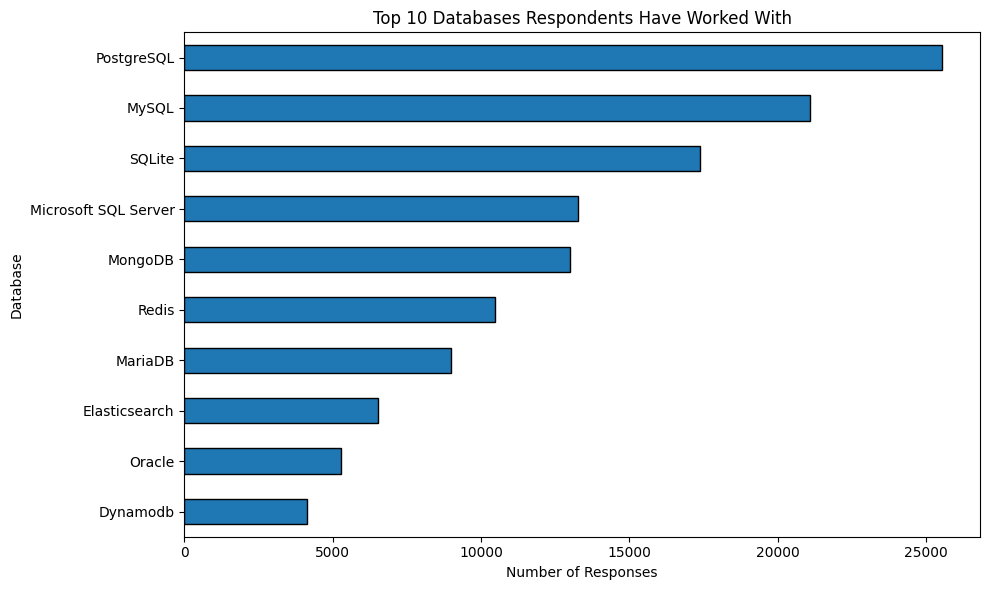

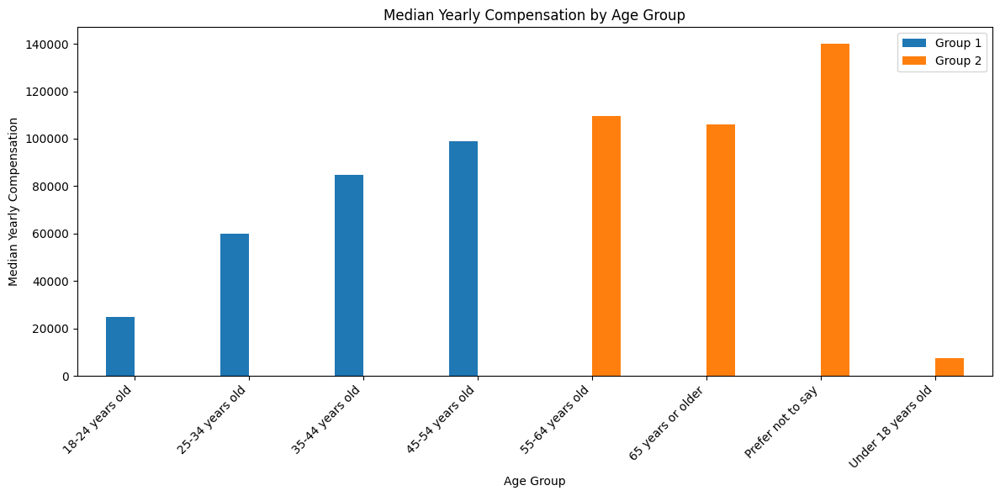

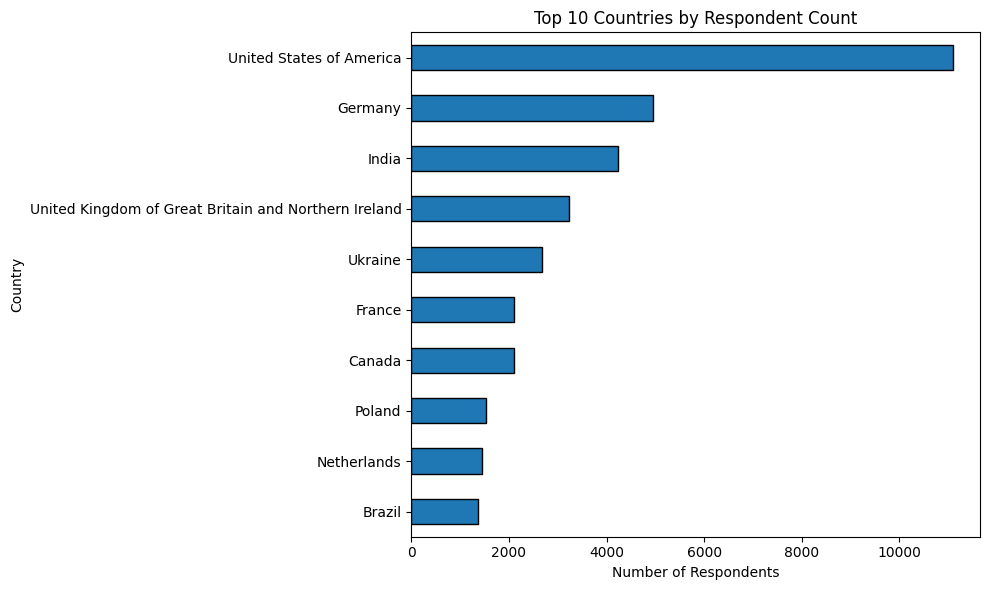

In [ ]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import numpy as np

# Connect to SQLite database
conn = sqlite3.connect("survey-data.sqlite")
df = pd.read_sql_query("SELECT * FROM main", conn)
conn.close()


# Prepare numerical columns
for col in ["ConvertedCompYearly", "JobSatPoints_6", "JobSatPoints_7"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


# Convert categorical Age values to numeric values
# Handles values such as "25-34", "35-44", and "65 years or older"
def convert_age(age):
    if pd.isna(age):
        return np.nan

    age = str(age).strip()

    if age.lower() in ["under 18", "under 18 years old"]:
        return 17

    if "prefer not to say" in age.lower() or "not applicable" in age.lower():
        return np.nan

    if "older" in age.lower():
        return 70

    if "-" in age:
        parts = age.split("-")
        try:
            return (float(parts[0]) + float(parts[1])) / 2
        except ValueError:
            return np.nan

    try:
        return float(age)
    except ValueError:
        return np.nan


if "Age" in df.columns:
    df["Age_numeric"] = df["Age"].apply(convert_age)


# ============================================================
# TASK 1.1: Histogram of ConvertedCompYearly
# ============================================================

if "ConvertedCompYearly" in df.columns:
    compensation = df["ConvertedCompYearly"].dropna()

    plt.figure(figsize=(10, 6))
    plt.hist(compensation, bins=30, edgecolor="black")
    plt.title("Distribution of Yearly Compensation")
    plt.xlabel("Yearly Compensation")
    plt.ylabel("Number of Respondents")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 1.2: Box Plot of Age
# ============================================================

if "Age_numeric" in df.columns:
    age_data = df["Age_numeric"].dropna()

    plt.figure(figsize=(8, 5))
    plt.boxplot(age_data)
    plt.title("Box Plot of Age")
    plt.ylabel("Age")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 2.1: Scatter Plot of Age and Compensation
# ============================================================

if all(c in df.columns for c in ["Age_numeric", "ConvertedCompYearly"]):
    scatter_data = df[["Age_numeric", "ConvertedCompYearly"]].dropna()

    plt.figure(figsize=(10, 6))
    plt.scatter(
        scatter_data["Age_numeric"],
        scatter_data["ConvertedCompYearly"],
        alpha=0.5
    )
    plt.title("Age vs. Yearly Compensation")
    plt.xlabel("Age (Numeric)")
    plt.ylabel("Yearly Compensation")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 2.2: Bubble Plot of Compensation and Job Satisfaction
# with Age as Bubble Size
# ============================================================

required = ["ConvertedCompYearly", "JobSatPoints_6", "Age_numeric"]

if all(c in df.columns for c in required):
    bubble_data = df[required].dropna().copy()
    bubble_data = bubble_data[
        (bubble_data["ConvertedCompYearly"] >= 0) &
        (bubble_data["Age_numeric"] > 0)
    ]

    # Limit bubble sizes so the plot remains readable
    bubble_sizes = bubble_data["Age_numeric"] * 3

    plt.figure(figsize=(10, 6))
    plt.scatter(
        bubble_data["ConvertedCompYearly"],
        bubble_data["JobSatPoints_6"],
        s=bubble_sizes,
        alpha=0.4
    )
    plt.title("Compensation vs. Job Satisfaction (Bubble Size = Age)")
    plt.xlabel("Yearly Compensation")
    plt.ylabel("Job Satisfaction Points")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 3.1: Horizontal Bar Chart of MainBranch Distribution
# ============================================================

if "MainBranch" in df.columns:
    mainbranch_counts = df["MainBranch"].dropna().value_counts().sort_values()

    plt.figure(figsize=(10, 6))
    mainbranch_counts.plot(kind="barh")
    plt.title("Respondent Distribution by Main Branch")
    plt.xlabel("Number of Respondents")
    plt.ylabel("Main Branch")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 3.2: Top 5 Programming Languages Respondents Want to Use
# ============================================================

if "LanguageWantToWorkWith" in df.columns:
    languages = (
        df["LanguageWantToWorkWith"]
        .dropna()
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
    )

    language_counts = languages[languages != ""].value_counts().head(5)

    plt.figure(figsize=(10, 6))
    language_counts.plot(kind="bar", edgecolor="black")
    plt.title("Top 5 Desired Programming Languages")
    plt.xlabel("Programming Language")
    plt.ylabel("Number of Responses")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 3.3: Stacked Bar Chart of Median Job Satisfaction by Age
# ============================================================

required = ["Age", "JobSatPoints_6", "JobSatPoints_7"]

if all(c in df.columns for c in required):
    satisfaction_by_age = (
        df.groupby("Age")[["JobSatPoints_6", "JobSatPoints_7"]]
        .median()
        .dropna(how="all")
    )

    satisfaction_by_age.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 6)
    )
    plt.title("Median Job Satisfaction Points by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Median Satisfaction Points")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 3.4: Bar Chart of Database Popularity
# ============================================================

if "DatabaseHaveWorkedWith" in df.columns:
    databases = (
        df["DatabaseHaveWorkedWith"]
        .dropna()
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
    )

    database_counts = databases[databases != ""].value_counts().head(10)

    plt.figure(figsize=(10, 6))
    database_counts.sort_values().plot(kind="barh", edgecolor="black")
    plt.title("Top 10 Databases Respondents Have Worked With")
    plt.xlabel("Number of Responses")
    plt.ylabel("Database")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 4.1: Grouped Bar Chart of Median Compensation by Age
# ============================================================

if all(c in df.columns for c in ["Age", "ConvertedCompYearly"]):
    compensation_by_age = (
        df.groupby("Age")["ConvertedCompYearly"]
        .median()
        .dropna()
    )

    # Split age groups into two groups for side-by-side comparison
    midpoint = (len(compensation_by_age) + 1) // 2
    group1 = compensation_by_age.iloc[:midpoint]
    group2 = compensation_by_age.iloc[midpoint:]

    grouped_data = pd.DataFrame({
        "Group 1": group1,
        "Group 2": group2
    }).fillna(0)

    grouped_data.plot(
        kind="bar",
        figsize=(12, 6)
    )
    plt.title("Median Yearly Compensation by Age Group")
    plt.xlabel("Age Group")
    plt.ylabel("Median Yearly Compensation")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# TASK 4.2: Bar Chart of Respondent Count by Country
# ============================================================

if "Country" in df.columns:
    country_counts = df["Country"].dropna().value_counts().head(10)

    plt.figure(figsize=(10, 6))
    country_counts.sort_values().plot(kind="barh", edgecolor="black")
    plt.title("Top 10 Countries by Respondent Count")
    plt.xlabel("Number of Respondents")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()
